# EE513 Project 1 — Camera Characterization

**Camera:** iPhone 14 Pro main rear camera | **Data:** Bayer RAW DNG | **Course:** EE513

I brought together the code I used for calibration, MTF50, sensor noise, dynamic range, and color accuracy. I kept the original calculations and added a few checks that show whether the methods are working.

**Python packages:** `numpy`, `pandas`, `matplotlib`, `opencv-python`, `rawpy`, `tifffile`, `scipy`, `colour-science`, and `ipython`.

## 0. Setup — check the image folder first

I keep the image folder in one place here, so I do not have to edit every section if I move the project. On my computer the original folder was `C:\EE513\Images`. You can also set an `EE513_DATA_ROOT` environment variable.

### 0.1 Set the RAW image folder

In [1]:
from pathlib import Path
import os
import numpy as np

# All my Project 1 DNG folders are inside this directory.
DATA_ROOT = Path(os.environ.get("EE513_DATA_ROOT", r"C:\EE513\Images"))
print("Using image folder:", DATA_ROOT)
assert DATA_ROOT.is_dir(), (
    "The image folder was not found. Change DATA_ROOT above "
    "to the folder containing the Project 1 DNG captures."
)


Using image folder: C:\EE513\Images


## 1. Geometry — calibration and straight-edge test

I recaptured the checkerboard with better coverage because the earlier calibration gave a low reprojection error but made a separate straight-edge image worse. I kept `k3 = 0` in the final model.

The first part below uses the original calibration functions and checkerboard images. The last cells check the independent edge instead of judging the fit from reprojection error alone.

### 1.1 Import libraries and checkerboard settings

In [2]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True,
                     "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)

BOARD = (9, 6)            # inner corners of the printed target
SQUARE_MM = 20.0          # measure yours with a ruler and put the real number here
print("OpenCV", cv2.__version__)

OpenCV 5.0.0


### 1.2 Read camera identification from DNG metadata

In [3]:
import tifffile


def lens_id(path):
    """The fingerprint of the camera that made this raw file."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]
        return (exif.get("LensModel", "unknown"),
                round(fl[0] / fl[1], 3),
                exif.get("FocalLengthIn35mmFilm"),
                (p.tags["ImageWidth"].value, p.tags["ImageLength"].value))


def assert_one_camera(paths):
    ids = {lens_id(p) for p in paths}
    if len(ids) != 1:
        raise SystemExit(f"more than one camera in this series:\n  " +
                         "\n  ".join(map(str, ids)))
    return ids.pop()

### 1.3 Detect checkerboard corners in RAW captures

In [4]:
CAPTURE_DIR = Path(str(DATA_ROOT / 'Calibration1'))
import rawpy  

def board_object_points():
    objp = np.zeros((BOARD[0] * BOARD[1], 3), np.float32)
    objp[:, :2] = np.mgrid[0:BOARD[0], 0:BOARD[1]].T.reshape(-1, 2) * SQUARE_MM
    return objp


def from_real_images(folder):
    """Decode DNG captures and detect the BOARD internal corners."""
    files = sorted(p for p in Path(folder).iterdir() if p.suffix.lower() == ".dng")
    print(f"Found {len(files)} DNG files in {folder}")
    if not files:
        raise RuntimeError("No DNGs found; check CAPTURE_DIR and file extensions")
    obj, img, used, shape = [], [], [], None
    for f in files:
        with rawpy.imread(str(f)) as raw:
            rgb = raw.postprocess(use_camera_wb=True, no_auto_bright=True,
                                  output_bps=8)
        gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
        this_shape = gray.shape[::-1]
        if shape is not None and this_shape != shape:
            raise RuntimeError(f"Image dimensions differ at {f.name}: {this_shape} vs {shape}")
        shape = this_shape
        ok, corners = cv2.findChessboardCornersSB(gray, BOARD)
        if not ok:
            continue
        obj.append(board_object_points())
        img.append(corners.astype(np.float32))
        used.append(f)
    return obj, img, shape, used


def synthetic(n=15, tilt_deg=40.0, noise_px=0.20, seed=513):
    """A believable capture session: varied tilts, sub-pixel corner noise."""
    rng = np.random.default_rng(seed)
    K = np.array([[2795.7, 0, 2015.5], [0, 2795.7, 1511.5], [0, 0, 1]])
    dist = np.array([-0.12, 0.08, 0.0, 0.0, 0.0])
    objp, obj, img = board_object_points(), [], []
    while len(img) < n:
        ax = rng.normal(size=3); ax /= np.linalg.norm(ax)
        rvec = ax * np.radians(rng.uniform(0.35, 1.0) * tilt_deg)
        span = BOARD[0] * SQUARE_MM
        tvec = np.array([rng.uniform(-0.75, 0.15) * span,
                         rng.uniform(-0.75, 0.15) * span * 0.8,
                         rng.uniform(320, 900)])
        p, _ = cv2.projectPoints(objp, rvec, tvec, K, dist)
        p = p.reshape(-1, 2)
        if (p[:, 0].min() > 60 and p[:, 0].max() < 4032 - 60 and
                p[:, 1].min() > 60 and p[:, 1].max() < 3024 - 60):
            obj.append(objp)
            img.append((p + rng.normal(0, noise_px, p.shape)).astype(np.float32)
                       .reshape(-1, 1, 2))
    return obj, img, (4032, 3024), K, dist


if CAPTURE_DIR and Path(CAPTURE_DIR).exists():
    obj_points, img_points, img_shape, used = from_real_images(CAPTURE_DIR)
    TRUTH = None
    print(f"{len(img_points)} of {len([p for p in Path(CAPTURE_DIR).iterdir() if p.suffix.lower() == ".dng"])} captures gave a full {BOARD} grid")
    if len(img_points) < 3:
        raise RuntimeError("Insufficient checkerboard views for calibration")
else:
    raise FileNotFoundError(f"Calibration folder not found: {CAPTURE_DIR}")

Found 16 DNG files in C:\EE513\Images\Calibration1
16 of 16 captures gave a full (9, 6) grid


### 1.4 Fit camera intrinsics and distortion coefficients

In [82]:
rms, K, dist, rvecs, tvecs, sd_int, sd_ext, per_view = cv2.calibrateCameraExtended(
    obj_points, img_points, img_shape, None, None,
    flags=cv2.CALIB_FIX_K3)

calibration_rms = float(rms)
fx, fy, cx, cy = K[0, 0], K[1, 1], K[0, 2], K[1, 2]
sfx, sfy, scx, scy = sd_int.ravel()[:4]

print(f"RMS reprojection error   {rms:.4f} px\n")
print(f"f_x  {fx:9.2f}  +/- {sfx:.2f} px")
print(f"f_y  {fy:9.2f}  +/- {sfy:.2f} px")
print(f"c_x  {cx:9.2f}  +/- {scx:.2f} px      (image centre {img_shape[0]/2:.1f})")
print(f"c_y  {cy:9.2f}  +/- {scy:.2f} px      (image centre {img_shape[1]/2:.1f})")
print("\ndistortion  k1 k2 p1 p2 k3")
print("  ", dist.ravel())
print("  +/-", sd_int.ravel()[4:9])

if TRUTH is not None:
    print(f"\ntrue f_x {TRUTH[0][0,0]:.1f}, "
          f"error {(fx - TRUTH[0][0,0]) / TRUTH[0][0,0] * 100:+.3f}%")
print(f"\nEXIF predicted 2796 px for the instructor's iPhone 15 Pro. "
      f"Does yours agree with your own prediction?")
print("\nModel: k3 fixed at zero using cv2.CALIB_FIX_K3 (four fitted distortion coefficients).")


RMS reprojection error   0.8946 px

f_x    2786.07  +/- 11.03 px
f_y    2791.50  +/- 10.45 px
c_x    1501.06  +/- 5.76 px      (image centre 1512.0)
c_y    2003.55  +/- 7.76 px      (image centre 2016.0)

distortion  k1 k2 p1 p2 k3
   [ 0.0552 -0.0493 -0.0001 -0.0017  0.    ]
  +/- [ 0.003   0.0037  0.0006  0.0007  0.    ]

EXIF predicted 2796 px for the instructor's iPhone 15 Pro. Does yours agree with your own prediction?

Model: k3 fixed at zero using cv2.CALIB_FIX_K3 (four fitted distortion coefficients).


### 1.5 Inspect distortion across image positions

In [6]:
import numpy as np

h, w = 4032, 3024

fx, fy = K[0, 0], K[1, 1]
cx, cy = K[0, 2], K[1, 2]

k1, k2, p1, p2, k3 = dist.ravel()[:5]

locations = {
    "Center": (w / 2, h / 2),
    "Top-left": (0, 0),
    "Top-right": (w - 1, 0),
    "Bottom-left": (0, h - 1),
    "Bottom-right": (w - 1, h - 1)
}

print("Radial distortion relative to ideal radius:\n")

for name, (u, v) in locations.items():

    x = (u - cx) / fx
    y = (v - cy) / fy

    r2 = x*x + y*y

    radial = 1 + k1*r2 + k2*r2**2 + k3*r2**3

    distortion_pct = (radial - 1) * 100

    print(f"{name:15s}: {distortion_pct:+.2f}%")

Radial distortion relative to ideal radius:

Center         : +0.00%
Top-left       : +1.25%
Top-right      : +1.23%
Bottom-left    : +1.22%
Bottom-right   : +1.20%


### 1.6 Display checkerboard detections

Detected 16 of 16 images


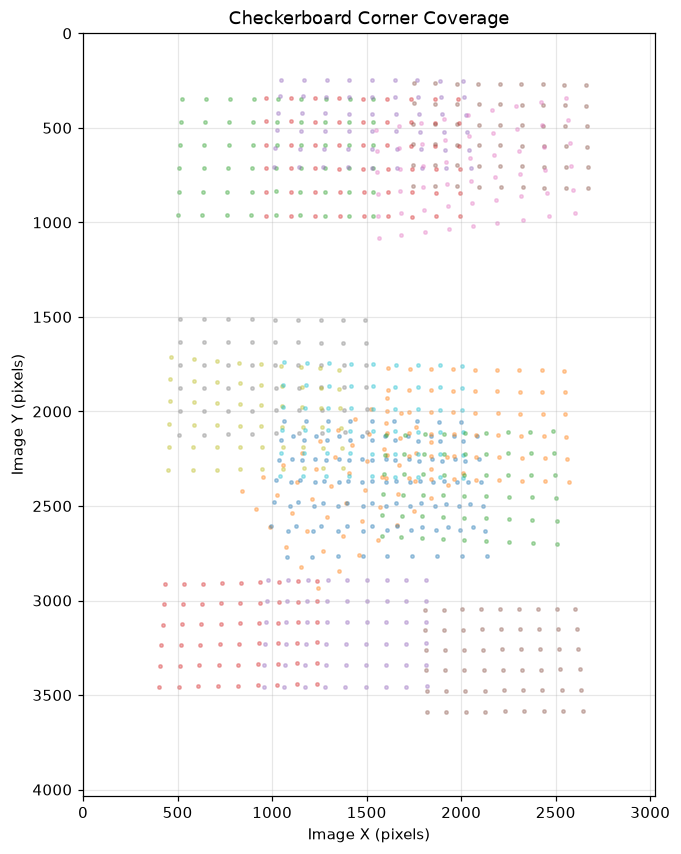

In [7]:

import cv2
import rawpy
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Your calibration folder
CAPTURE_DIR = Path(str(DATA_ROOT / 'Calibration1'))
BOARD = (9, 6)

dng_files = sorted(
    p for p in CAPTURE_DIR.iterdir()
    if p.suffix.lower() == ".dng"
)

if not dng_files:
    raise RuntimeError("No DNG images found.")

all_corners = []
image_size = None
successful_files = []

for file in dng_files:

    with rawpy.imread(str(file)) as raw:
        rgb = raw.postprocess(
            use_camera_wb=True,
            no_auto_bright=True,
            output_bps=8
        )

    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    h, w = gray.shape
    image_size = (w, h)

    found, corners = cv2.findChessboardCornersSB(
        gray, BOARD
    )

    if found:
        all_corners.append(corners.reshape(-1, 2))
        successful_files.append(file.name)

print(f"Detected {len(successful_files)} of {len(dng_files)} images")

# Plot actual checkerboard coverage
plt.figure(figsize=(7, 9))

for corners in all_corners:
    plt.scatter(
        corners[:, 0],
        corners[:, 1],
        s=5,
        alpha=0.35
    )

plt.xlim(0, image_size[0])
plt.ylim(image_size[1], 0)
plt.gca().set_aspect("equal")

plt.title("Checkerboard Corner Coverage")
plt.xlabel("Image X (pixels)")
plt.ylabel("Image Y (pixels)")
plt.grid(alpha=0.3)

plt.show()


### 1.7 Measure checkerboard coverage

In [8]:
import numpy as np

all_pts = np.vstack([
    pts.reshape(-1, 2) for pts in img_points
])

w, h = img_shape

xmin, ymin = all_pts.min(axis=0)
xmax, ymax = all_pts.max(axis=0)

print("=== PROJECT 1 CORNER COVERAGE ===")
print(f"Calibration images: {len(img_points)}")
print(f"X coverage: {xmin:.1f} to {xmax:.1f} px")
print(f"Y coverage: {ymin:.1f} to {ymax:.1f} px")

print(f"Horizontal span: {(xmax-xmin)/w*100:.1f}%")
print(f"Vertical span:   {(ymax-ymin)/h*100:.1f}%")

print(f"Left unsampled margin:   {xmin:.1f} px")
print(f"Right unsampled margin:  {w-xmax:.1f} px")
print(f"Top unsampled margin:    {ymin:.1f} px")
print(f"Bottom unsampled margin: {h-ymax:.1f} px")

=== PROJECT 1 CORNER COVERAGE ===
Calibration images: 16
X coverage: 401.6 to 2672.7 px
Y coverage: 244.7 to 3589.4 px
Horizontal span: 75.1%
Vertical span:   83.0%
Left unsampled margin:   401.6 px
Right unsampled margin:  351.3 px
Top unsampled margin:    244.7 px
Bottom unsampled margin: 442.6 px


### 1.8 Load the independent straight-edge image

Image dimensions: 3024 x 4032
Verification dimensions: (3024, 4032)
Calibration dimensions: (3024, 4032)
Image dimensions match!


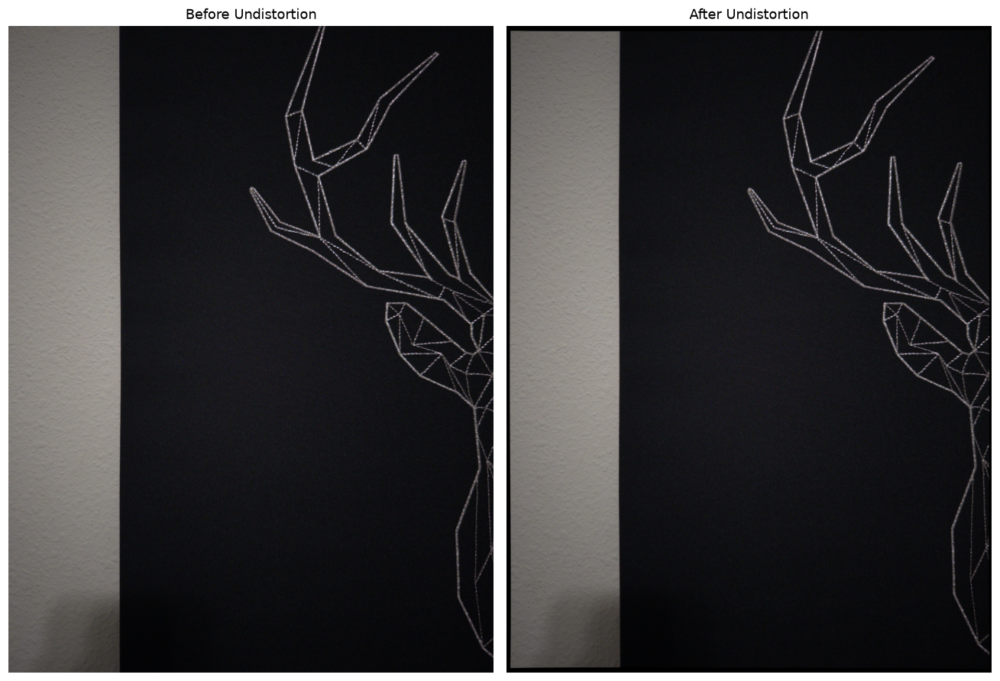

In [9]:
import cv2
import rawpy
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Project 1 independent verification image
dng_path = Path(
    str(DATA_ROOT / 'GeometryVerification' / 'IMG_5155.dng')
)

# Same image-loading method as calibration
with rawpy.imread(str(dng_path)) as raw:
    rgb = raw.postprocess(
        use_camera_wb=True,
        no_auto_bright=True,
        output_bps=8
    )

print("Image dimensions:", rgb.shape[1], "x", rgb.shape[0])

# Use the actual calibration values in the notebook

# Calibration image dimensions (width, height)
img_shape = (3024, 4032)

print("Verification dimensions:", rgb.shape[1::-1])
print("Calibration dimensions:", img_shape)

assert rgb.shape[1::-1] == img_shape, (
    "Verification image dimensions do not match calibration"
)

print("Image dimensions match!")


# Use the fitted camera matrix and distortion coefficients
# from your original calibration cell
corrected = cv2.undistort(rgb, K, dist, None, K)

fig, ax = plt.subplots(1, 2, figsize=(12, 10))

ax[0].imshow(rgb)
ax[0].set_title("Before Undistortion")
ax[0].axis("off")

ax[1].imshow(corrected)
ax[1].set_title("After Undistortion")
ax[1].axis("off")

plt.tight_layout()
plt.show()


### 1.9 Define the straight-edge deviation measurement

In [10]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def measure_vertical_edge(image, x1, x2, y1, y2):

    # Convert RGB image to grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

    # Select region of interest
    roi = gray[y1:y2, x1:x2].astype(np.float32)

    # Smooth noise before edge detection
    smooth = cv2.GaussianBlur(roi, (5, 5), 1.0)

    # Horizontal gradient detects vertical edges
    grad_x = cv2.Sobel(
        smooth, cv2.CV_32F, 1, 0, ksize=3
    )

    # Strongest vertical edge in each row
    x_local = np.argmax(np.abs(grad_x), axis=1)

    ys = np.arange(y1, y2)
    xs = x_local.astype(float) + x1

    # Fit straight line: x = m*y + b
    m, b = np.polyfit(ys, xs, 1)

    # Perpendicular deviation in pixels
    residuals = (
        xs - (m * ys + b)
    ) / np.sqrt(1 + m**2)

    rms = np.sqrt(np.mean(residuals**2))
    max_dev = np.max(np.abs(residuals))

    return xs, ys, m, b, rms, max_dev

print("Vertical-edge measurement function ready!")


Vertical-edge measurement function ready!


### 1.10 Compare straight-edge RMS before and after correction

=== PROJECT 1 STRAIGHT-EDGE VERIFICATION ===
Before: RMS = 2.769 px, Maximum = 5.289 px
After:  RMS = 1.634 px, Maximum = 3.152 px


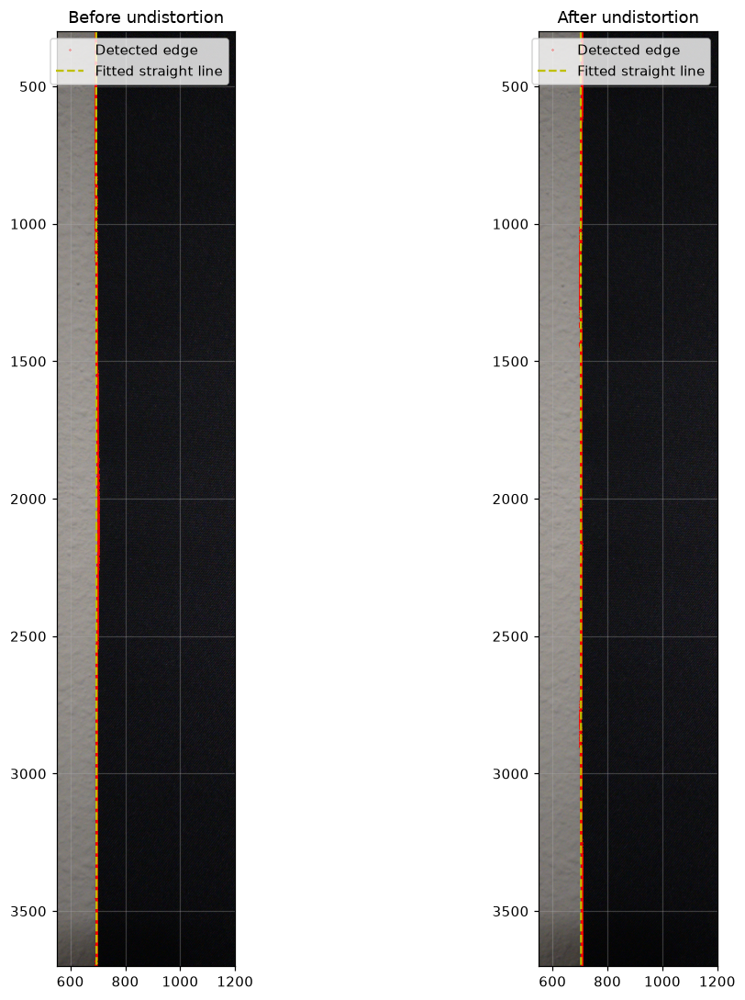

In [11]:
# ROI for the vertical black-to-wall boundary
x1, x2 = 550, 1200
y1, y2 = 300, 3700

before = measure_vertical_edge(rgb, x1, x2, y1, y2)
after = measure_vertical_edge(corrected, x1, x2, y1, y2)

print("=== PROJECT 1 STRAIGHT-EDGE VERIFICATION ===")

print(f"Before: RMS = {before[4]:.3f} px, "
      f"Maximum = {before[5]:.3f} px")

print(f"After:  RMS = {after[4]:.3f} px, "
      f"Maximum = {after[5]:.3f} px")

# Display only — no saving
fig, axes = plt.subplots(1, 2, figsize=(12, 10))

for ax, image, result, title in zip(
    axes,
    [rgb, corrected],
    [before, after],
    ["Before undistortion", "After undistortion"]
):
    ax.imshow(image)

    ax.plot(
        result[0], result[1],
        "r.", markersize=0.5,
        label="Detected edge"
    )

    ys = result[1]

    ax.plot(
        result[2] * ys + result[3],
        ys,
        "y--", linewidth=1.5,
        label="Fitted straight line"
    )

    ax.set_xlim(x1, x2)
    ax.set_ylim(y2, y1)
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()


### 1.11 Plot detected edges and fitted lines

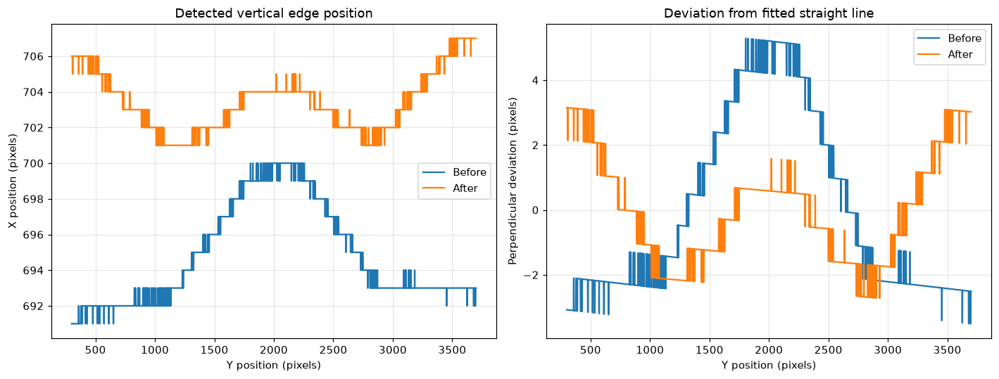

In [12]:

import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for result, label in [
    (before, "Before"),
    (after, "After")
]:
    xs, ys, m, b, rms, max_dev = result

    residual = (xs - (m * ys + b)) / np.sqrt(1 + m**2)

    axes[0].plot(ys, xs, label=label)
    axes[1].plot(ys, residual, label=label)

axes[0].set_title("Detected vertical edge position")
axes[0].set_xlabel("Y position (pixels)")
axes[0].set_ylabel("X position (pixels)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].set_title("Deviation from fitted straight line")
axes[1].set_xlabel("Y position (pixels)")
axes[1].set_ylabel("Perpendicular deviation (pixels)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 2. Spatial resolution — MTF50

I used the green Bayer plane instead of a demosaiced RGB image. I also chose one clean edge ROI for each region and measured five captures per region.

The synthetic Gaussian edge gives me a numerical check on the MTF50 method before I trust the measurements from real photographs.

### 2.1 Load center slanted-edge RAW captures

Number of RAW DNG files: 5
Files: ['IMG_5193.DNG', 'IMG_5194.DNG', 'IMG_5195.DNG', 'IMG_5196.DNG', 'IMG_5197.DNG']
RAW mosaic shape: (3024, 4032)
Bayer pattern: [[2 3]
 [1 0]]
Color descriptions: b'RGBG'


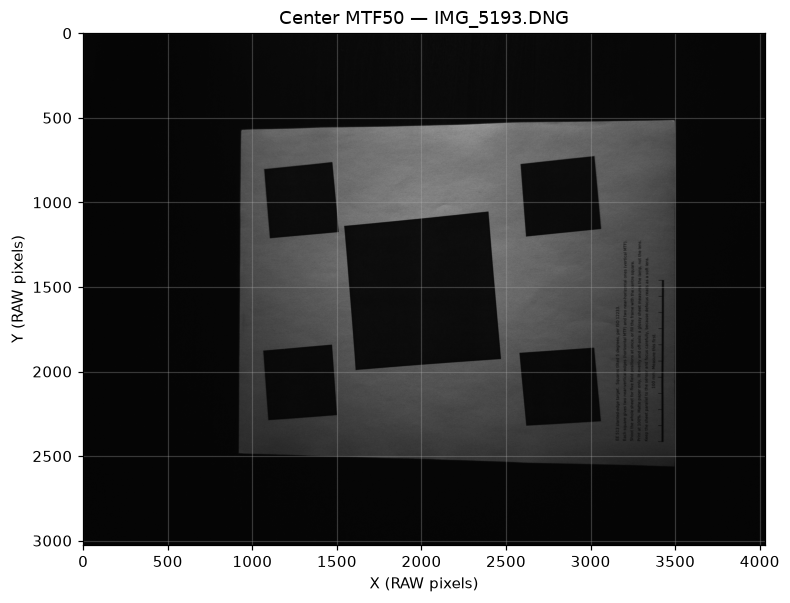

In [13]:
import rawpy
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Folder containing your five center MTF50 images
MTF_DIR = Path(str(DATA_ROOT / 'MTF50' / 'Center'))

files = sorted(
    f for f in MTF_DIR.iterdir()
    if f.is_file() and f.suffix.lower() == ".dng"
)

print("Number of RAW DNG files:", len(files))
print("Files:", [f.name for f in files])

assert len(files) >= 5, "Expected at least five center DNG captures"

# Load first RAW DNG (no demosaicing or gamma)
with rawpy.imread(str(files[0])) as raw:
    mosaic = raw.raw_image_visible.copy()
    raw_pattern = raw.raw_pattern.copy()
    color_desc = raw.color_desc

print("RAW mosaic shape:", mosaic.shape)
print("Bayer pattern:", raw_pattern)
print("Color descriptions:", color_desc)

# Display RAW mosaic for ROI inspection only
plt.figure(figsize=(8, 10))
plt.imshow(mosaic, cmap="gray")
plt.title(f"Center MTF50 — {files[0].name}")
plt.xlabel("X (RAW pixels)")
plt.ylabel("Y (RAW pixels)")
plt.show()


### 2.2 Identify and extract the green Bayer plane

Green photosite positions: [(0, 1), (1, 0)]
Green plane dimensions: (1512, 2016)


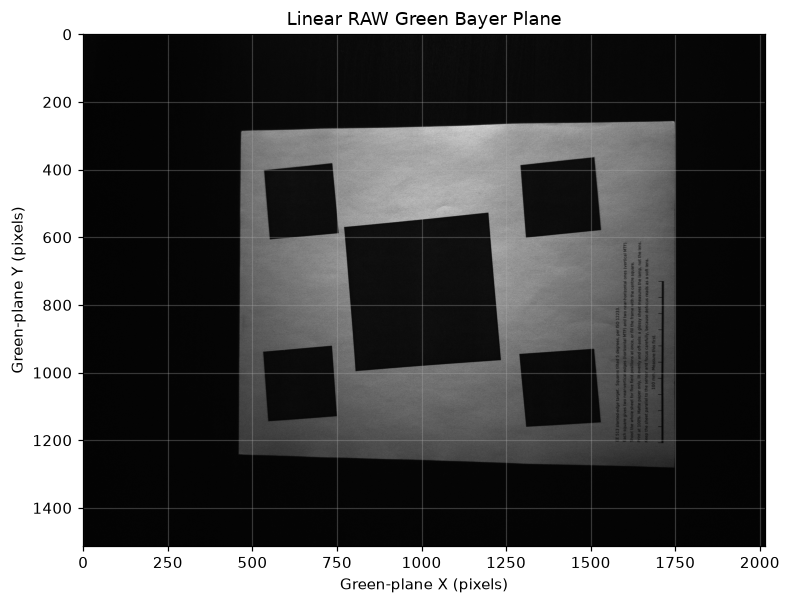

In [14]:

# Identify green photosites from the CFA metadata
desc = color_desc.decode("ascii").replace("\x00", "")

green_positions = []

for row in range(2):
    for col in range(2):
        channel = raw_pattern[row, col]
        if desc[channel] == "G":
            green_positions.append((row, col))

print("Green photosite positions:", green_positions)

assert len(green_positions) == 2, (
    "Expected two green positions in a 2x2 Bayer CFA"
)

# Extract one consistent green lattice
green_row, green_col = green_positions[0]

green = mosaic[
    green_row::2,
    green_col::2
].astype(np.float32)

print("Green plane dimensions:", green.shape)

plt.figure(figsize=(8, 10))
plt.imshow(green, cmap="gray")
plt.title("Linear RAW Green Bayer Plane")
plt.xlabel("Green-plane X (pixels)")
plt.ylabel("Green-plane Y (pixels)")
plt.show()


### 2.3 Display the center green-plane image

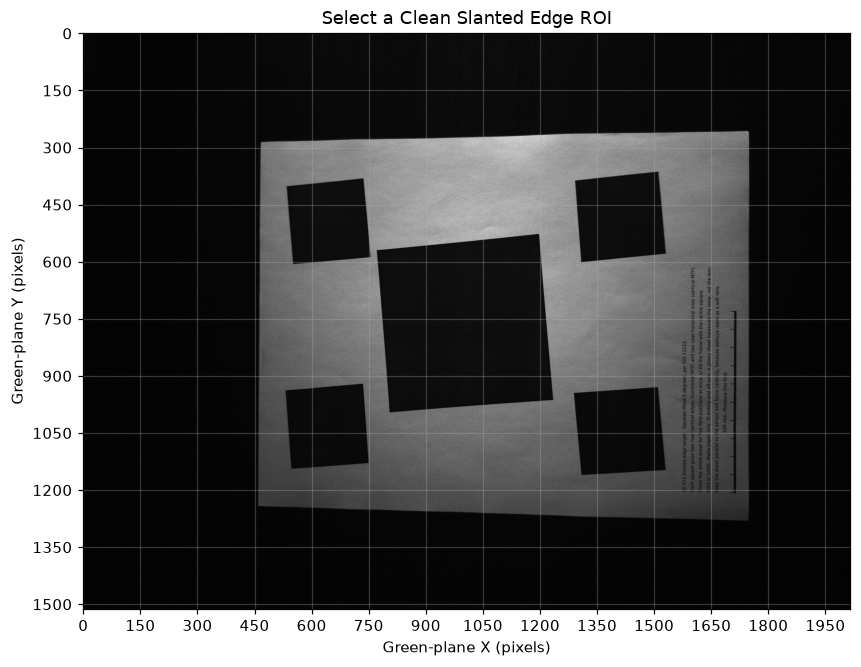

In [15]:
plt.figure(figsize=(9, 10))

plt.imshow(green, cmap="gray")

plt.xticks(np.arange(0, green.shape[1] + 1, 150))
plt.yticks(np.arange(0, green.shape[0] + 1, 150))

plt.xlabel("Green-plane X (pixels)")
plt.ylabel("Green-plane Y (pixels)")
plt.title("Select a Clean Slanted Edge ROI")

plt.grid(alpha=0.3)
plt.show()


### 2.4 Select the center slanted-edge ROI

ROI dimensions: (260, 120)
ROI minimum DN: 534.0
ROI maximum DN: 1261.0


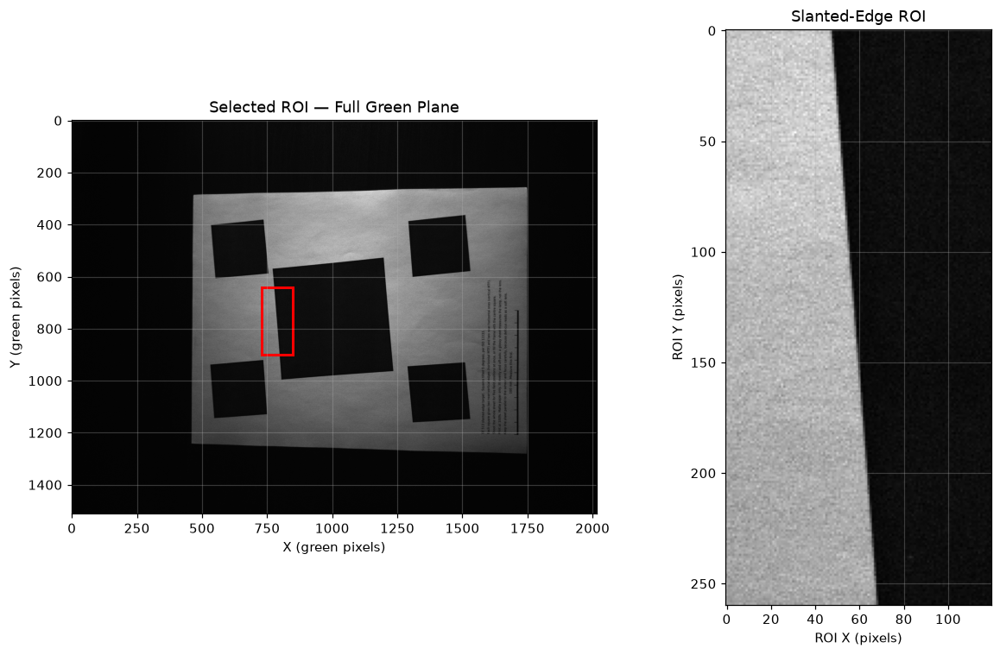

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Green-plane ROI coordinates
x1, x2 = 730, 850
y1, y2 = 640, 900

roi = green[y1:y2, x1:x2]

print("ROI dimensions:", roi.shape)
print("ROI minimum DN:", np.min(roi))
print("ROI maximum DN:", np.max(roi))

fig, ax = plt.subplots(1, 2, figsize=(12, 7))

# Full green-plane image with ROI highlighted
ax[0].imshow(green, cmap="gray")
ax[0].add_patch(
    Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)
ax[0].set_title("Selected ROI — Full Green Plane")
ax[0].set_xlabel("X (green pixels)")
ax[0].set_ylabel("Y (green pixels)")

# Zoomed slanted edge
ax[1].imshow(roi, cmap="gray")
ax[1].set_title("Slanted-Edge ROI")
ax[1].set_xlabel("ROI X (pixels)")
ax[1].set_ylabel("ROI Y (pixels)")

plt.tight_layout()
plt.show()


### 2.5 Detect the slanted edge and fit its angle

=== SLANTED-EDGE VERIFICATION ===
Measured edge angle: 4.596 degrees
Edge slope: 0.080395 px/row
ROI mean DN: 807.6
ROI minimum DN: 534.0
ROI maximum DN: 1261.0


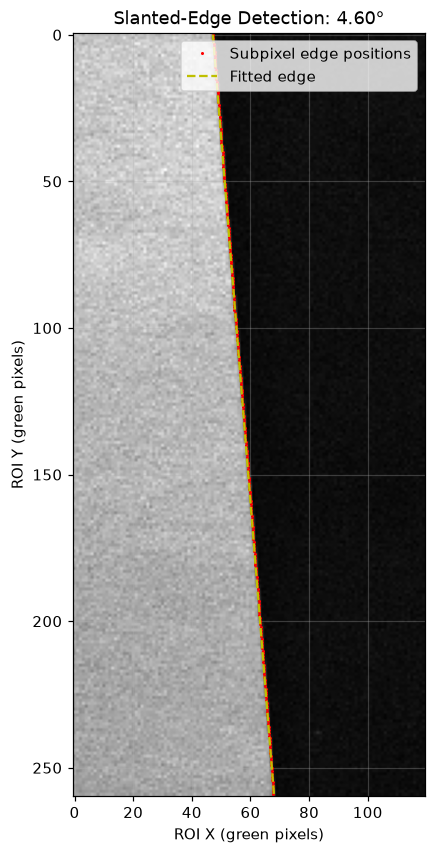

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# ROI from Step 4
roi_float = roi.astype(np.float32)

# Smooth lightly for edge-position detection only
smooth = cv2.GaussianBlur(roi_float, (5, 5), 1.0)

# Horizontal gradient for approximately vertical edge
grad_x = cv2.Sobel(
    smooth, cv2.CV_32F, 1, 0, ksize=3
)

# Coarse edge position in each row
coarse_x = np.argmax(np.abs(grad_x), axis=1)

# Subpixel centroid within ±5 pixels of each coarse position
edge_x = []

for row in range(roi.shape[0]):
    center = int(coarse_x[row])

    lo = max(0, center - 5)
    hi = min(roi.shape[1], center + 6)

    weights = np.abs(grad_x[row, lo:hi])
    positions = np.arange(lo, hi)

    if weights.sum() > 0:
        x_sub = np.sum(positions * weights) / weights.sum()
    else:
        x_sub = float(center)

    edge_x.append(x_sub)

edge_x = np.array(edge_x)
edge_y = np.arange(len(edge_x))

# Fit x = m*y + b
m, b = np.polyfit(edge_y, edge_x, 1)

angle_deg = np.degrees(np.arctan(abs(m)))

print("=== SLANTED-EDGE VERIFICATION ===")
print(f"Measured edge angle: {angle_deg:.3f} degrees")
print(f"Edge slope: {m:.6f} px/row")
print(f"ROI mean DN: {np.mean(roi):.1f}")
print(f"ROI minimum DN: {np.min(roi):.1f}")
print(f"ROI maximum DN: {np.max(roi):.1f}")

# Plot detected edge and fitted line
plt.figure(figsize=(6, 9))
plt.imshow(roi, cmap="gray")

plt.plot(
    edge_x, edge_y,
    "r.", markersize=2,
    label="Subpixel edge positions"
)

plt.plot(
    m * edge_y + b,
    edge_y,
    "y--", linewidth=1.5,
    label="Fitted edge"
)

plt.title(f"Slanted-Edge Detection: {angle_deg:.2f}°")
plt.xlabel("ROI X (green pixels)")
plt.ylabel("ROI Y (green pixels)")
plt.legend()

plt.show()


### 2.6 Calculate ESF, LSF, MTF, and MTF50

=== CENTER MTF50 — FIRST CAPTURE ===
MTF50: 0.3699 cycles/green-plane pixel
Nyquist: 0.5000 cycles/green-plane pixel


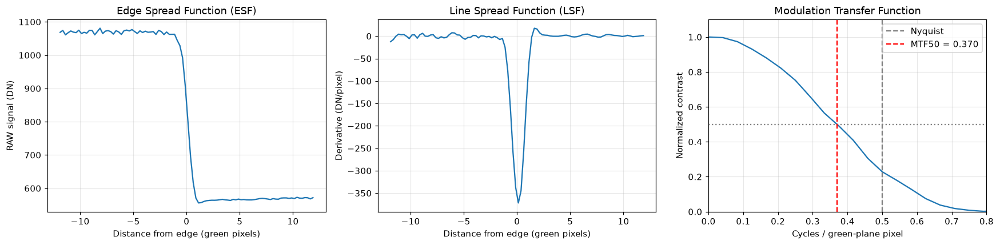

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import savgol_filter

# Step 6 — Slanted-edge MTF50
# Inputs: roi (linear green Bayer data), m and b (edge fit)

roi_float = roi.astype(np.float64)

# 1. Project pixels onto the fitted edge normal
yy, xx = np.indices(roi_float.shape)
distance = (xx - m * yy - b) / np.sqrt(1 + m**2)

# 2. Build supersampled ESF (4 samples per green pixel)
bin_width = 0.25
edges = np.arange(-12, 12 + bin_width, bin_width)
centers = (edges[:-1] + edges[1:]) / 2

signal_sum, _ = np.histogram(
    distance.ravel(),
    bins=edges,
    weights=roi_float.ravel()
)
counts, _ = np.histogram(distance.ravel(), bins=edges)

valid = counts > 0
assert valid.all(), "Empty ESF bins: check ROI and edge angle"

esf = signal_sum / counts

# 3. Smooth ESF lightly and differentiate to obtain LSF
esf_smooth = savgol_filter(
    esf, window_length=9, polyorder=3
)

lsf = np.gradient(esf_smooth, bin_width)

# 4. Window the LSF and calculate normalized Fourier magnitude
window = np.hanning(len(lsf))
lsf_windowed = lsf * window

mtf = np.abs(np.fft.rfft(lsf_windowed))
mtf = mtf / mtf[0]

freq = np.fft.rfftfreq(len(lsf_windowed), d=bin_width)

# 5. Find first MTF=0.5 crossing
crossings = np.where(mtf <= 0.5)[0]
assert len(crossings) > 0, "MTF did not cross 0.5"

i = crossings[0]
assert i > 0, "Invalid MTF50 crossing"

mtf50 = np.interp(
    0.5,
    [mtf[i], mtf[i-1]],
    [freq[i], freq[i-1]]
)

print("=== CENTER MTF50 — FIRST CAPTURE ===")
print(f"MTF50: {mtf50:.4f} cycles/green-plane pixel")
print("Nyquist: 0.5000 cycles/green-plane pixel")

# 6. Display ESF, LSF, and MTF
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(centers, esf)
ax[0].set_title("Edge Spread Function (ESF)")
ax[0].set_xlabel("Distance from edge (green pixels)")
ax[0].set_ylabel("RAW signal (DN)")
ax[0].grid(alpha=0.3)

ax[1].plot(centers, lsf)
ax[1].set_title("Line Spread Function (LSF)")
ax[1].set_xlabel("Distance from edge (green pixels)")
ax[1].set_ylabel("Derivative (DN/pixel)")
ax[1].grid(alpha=0.3)

ax[2].plot(freq, mtf)
ax[2].axhline(0.5, color="gray", linestyle=":")
ax[2].axvline(0.5, color="gray", linestyle="--",
              label="Nyquist")
ax[2].axvline(mtf50, color="red", linestyle="--",
              label=f"MTF50 = {mtf50:.3f}")
ax[2].set_xlim(0, 0.8)
ax[2].set_ylim(0, 1.1)
ax[2].set_title("Modulation Transfer Function")
ax[2].set_xlabel("Cycles / green-plane pixel")
ax[2].set_ylabel("Normalized contrast")
ax[2].legend()
ax[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 2.7 Verify MTF50 using a synthetic Gaussian edge

=== SYNTHETIC GAUSSIAN VALIDATION ===
Theoretical MTF50: 0.1874 cy/px
Measured MTF50:    0.1877 cy/px
Relative error:    +0.16%


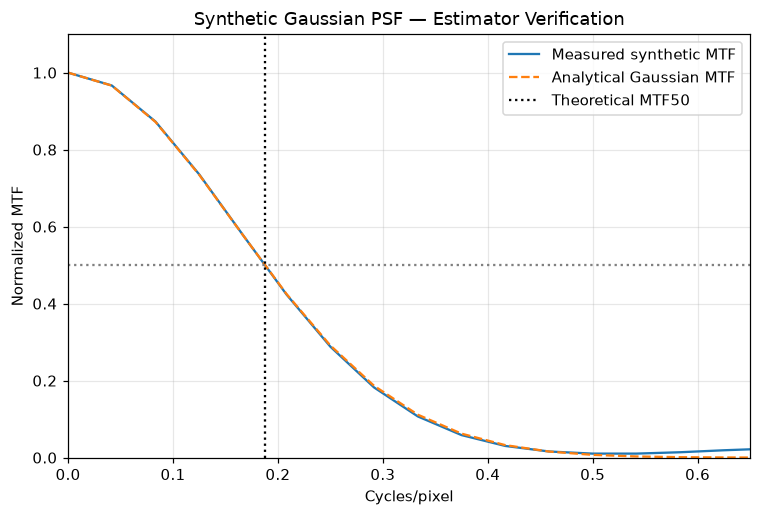

In [19]:

import numpy as np
import cv2
from scipy.ndimage import gaussian_filter
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt

# Create synthetic slanted edge with known Gaussian blur
H, W = 260, 120
sigma_true = 1.0
slope_true = np.tan(np.deg2rad(4.596))

yy, xx = np.indices((H, W))
edge_location = 50 + slope_true * yy

# Ideal bright-to-dark slanted edge
synthetic = np.where(xx < edge_location, 1070.0, 565.0)

# Apply Gaussian PSF of known sigma
synthetic = gaussian_filter(synthetic, sigma=sigma_true)

# Same edge detection procedure as Step 5
smooth = cv2.GaussianBlur(
    synthetic.astype(np.float32), (5, 5), 1.0
)
grad = cv2.Sobel(smooth, cv2.CV_32F, 1, 0, ksize=3)

coarse = np.argmax(np.abs(grad), axis=1)
edge_x = []

for row in range(H):
    c = int(coarse[row])
    lo, hi = max(0, c - 5), min(W, c + 6)

    weights = np.abs(grad[row, lo:hi])
    positions = np.arange(lo, hi)

    edge_x.append(np.sum(positions * weights) / weights.sum())

m_test, b_test = np.polyfit(np.arange(H), edge_x, 1)

# Same ESF/LSF/MTF procedure as Step 6
distance = (xx - m_test * yy - b_test) / np.sqrt(1 + m_test**2)

bin_width = 0.25
edges = np.arange(-12, 12 + bin_width, bin_width)
centers = (edges[:-1] + edges[1:]) / 2

sums, _ = np.histogram(
    distance.ravel(), bins=edges, weights=synthetic.ravel()
)
counts, _ = np.histogram(distance.ravel(), bins=edges)

assert np.all(counts > 0), "Empty ESF bins"

esf_test = sums / counts
esf_smooth_test = savgol_filter(esf_test, 9, 3)
lsf_test = np.gradient(esf_smooth_test, bin_width)

lsf_windowed = lsf_test * np.hanning(len(lsf_test))
mtf_test = np.abs(np.fft.rfft(lsf_windowed))
mtf_test /= mtf_test[0]

freq_test = np.fft.rfftfreq(len(lsf_windowed), d=bin_width)

crossing = np.where(mtf_test <= 0.5)[0][0]

mtf50_test = np.interp(
    0.5,
    [mtf_test[crossing], mtf_test[crossing - 1]],
    [freq_test[crossing], freq_test[crossing - 1]]
)

theory = np.sqrt(np.log(2)) / (np.sqrt(2) * np.pi * sigma_true)
error_pct = 100 * (mtf50_test - theory) / theory

print("=== SYNTHETIC GAUSSIAN VALIDATION ===")
print(f"Theoretical MTF50: {theory:.4f} cy/px")
print(f"Measured MTF50:    {mtf50_test:.4f} cy/px")
print(f"Relative error:    {error_pct:+.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(freq_test, mtf_test, label="Measured synthetic MTF")
plt.plot(
    freq_test,
    np.exp(-2 * np.pi**2 * sigma_true**2 * freq_test**2),
    "--",
    label="Analytical Gaussian MTF"
)
plt.axhline(0.5, color="gray", linestyle=":")
plt.axvline(theory, color="black", linestyle=":", label="Theoretical MTF50")
plt.xlim(0, 0.65)
plt.ylim(0, 1.1)
plt.xlabel("Cycles/pixel")
plt.ylabel("Normalized MTF")
plt.title("Synthetic Gaussian PSF — Estimator Verification")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 2.8 Check the synthetic MTF50 result against theory

In [20]:
# This is an independent check using a known Gaussian edge.
assert np.isfinite(mtf50_test)
assert abs(error_pct) < 1.0, f"Check the MTF50 code: error is {error_pct:+.2f}%"
print(f"PASS — synthetic Gaussian MTF50 error: {error_pct:+.2f}%")


PASS — synthetic Gaussian MTF50 error: +0.16%


### 2.9 Measure center MTF50 across all captures

IMG_5193.DNG: MTF50 = 0.3699 cy/green-px, angle = 4.60°
IMG_5194.DNG: MTF50 = 0.3638 cy/green-px, angle = 4.76°
IMG_5195.DNG: MTF50 = 0.3800 cy/green-px, angle = 4.85°
IMG_5196.DNG: MTF50 = 0.3753 cy/green-px, angle = 5.04°
IMG_5197.DNG: MTF50 = 0.3759 cy/green-px, angle = 4.84°

=== CENTER MTF50 SUMMARY ===
Captures: 5
Mean MTF50: 0.3730 cy/green-px
Sample standard deviation: 0.0063 cy/green-px


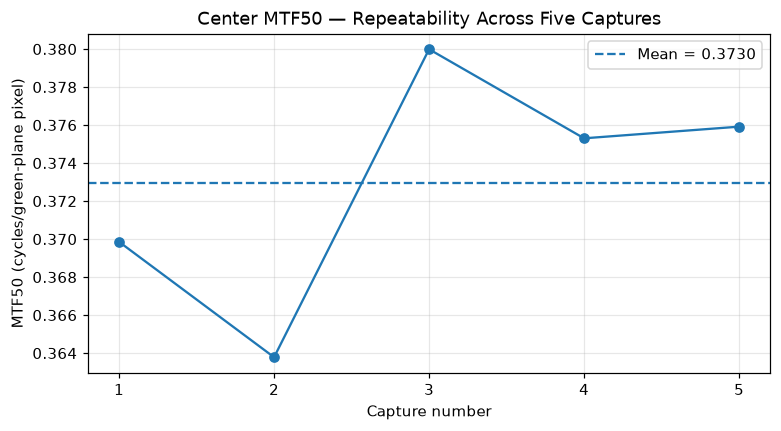

In [21]:
import rawpy
import cv2
import numpy as np
from scipy.signal import savgol_filter
import matplotlib.pyplot as plt

# Same ROI from Step 4, in green-plane coordinates
x1, x2 = 730, 850
y1, y2 = 640, 900

def measure_mtf50(image_roi):
    image_roi = image_roi.astype(np.float64)
    H, W = image_roi.shape

    # Detect edge using a local gradient centroid
    smooth = cv2.GaussianBlur(
        image_roi.astype(np.float32), (5, 5), 1.0
    )
    grad = cv2.Sobel(
        smooth, cv2.CV_32F, 1, 0, ksize=3
    )

    coarse = np.argmax(np.abs(grad), axis=1)
    edge_x = []

    for row in range(H):
        c = int(coarse[row])
        lo = max(0, c - 5)
        hi = min(W, c + 6)

        weights = np.abs(grad[row, lo:hi])
        positions = np.arange(lo, hi)

        if weights.sum() == 0:
            raise ValueError("No detectable edge in a row")

        edge_x.append(
            np.sum(positions * weights) / weights.sum()
        )

    m, b = np.polyfit(np.arange(H), edge_x, 1)
    angle = np.degrees(np.arctan(abs(m)))

    # Project samples onto the edge normal
    yy, xx = np.indices((H, W))
    distance = (xx - m * yy - b) / np.sqrt(1 + m**2)

    # Supersampled ESF
    bin_width = 0.25
    bins = np.arange(-12, 12 + bin_width, bin_width)

    sums, _ = np.histogram(
        distance.ravel(),
        bins=bins,
        weights=image_roi.ravel()
    )
    counts, _ = np.histogram(distance.ravel(), bins=bins)

    if np.any(counts == 0):
        raise ValueError("Empty ESF bins")

    esf = sums / counts

    # ESF -> LSF -> normalized MTF
    esf_smooth = savgol_filter(esf, 9, 3)
    lsf = np.gradient(esf_smooth, bin_width)

    lsf_windowed = lsf * np.hanning(len(lsf))

    mtf = np.abs(np.fft.rfft(lsf_windowed))
    mtf /= mtf[0]

    freq = np.fft.rfftfreq(len(lsf_windowed), d=bin_width)

    crossings = np.where(mtf <= 0.5)[0]
    if len(crossings) == 0 or crossings[0] == 0:
        raise ValueError("No valid MTF50 crossing")

    i = crossings[0]

    mtf50 = np.interp(
        0.5,
        [mtf[i], mtf[i-1]],
        [freq[i], freq[i-1]]
    )

    return mtf50, angle

# Analyze each Project 1 center DNG
results = []

for file in files:
    with rawpy.imread(str(file)) as raw:
        mosaic_i = raw.raw_image_visible.copy()

        # Check that the CFA remains consistent
        assert np.array_equal(raw.raw_pattern, raw_pattern)
        assert raw.color_desc == color_desc

    green_i = mosaic_i[
        green_row::2,
        green_col::2
    ].astype(np.float32)

    roi_i = green_i[y1:y2, x1:x2]

    mtf50_i, angle_i = measure_mtf50(roi_i)

    results.append(mtf50_i)

    print(
        f"{file.name}: "
        f"MTF50 = {mtf50_i:.4f} cy/green-px, "
        f"angle = {angle_i:.2f}°"
    )

results = np.array(results)

mean_mtf50 = np.mean(results)
std_mtf50 = np.std(results, ddof=1)

print("\n=== CENTER MTF50 SUMMARY ===")
print(f"Captures: {len(results)}")
print(f"Mean MTF50: {mean_mtf50:.4f} cy/green-px")
print(f"Sample standard deviation: {std_mtf50:.4f} cy/green-px")

# Display repeatability
plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(results)+1), results, "o-")
plt.axhline(
    mean_mtf50,
    linestyle="--",
    label=f"Mean = {mean_mtf50:.4f}"
)
plt.xlabel("Capture number")
plt.ylabel("MTF50 (cycles/green-plane pixel)")
plt.title("Center MTF50 — Repeatability Across Five Captures")
plt.xticks(np.arange(1, len(results)+1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 2.10 Load top-left RAW captures

Top-left DNG files: 5
['IMG_5208.DNG', 'IMG_5209.DNG', 'IMG_5210.DNG', 'IMG_5211.DNG', 'IMG_5212.DNG']


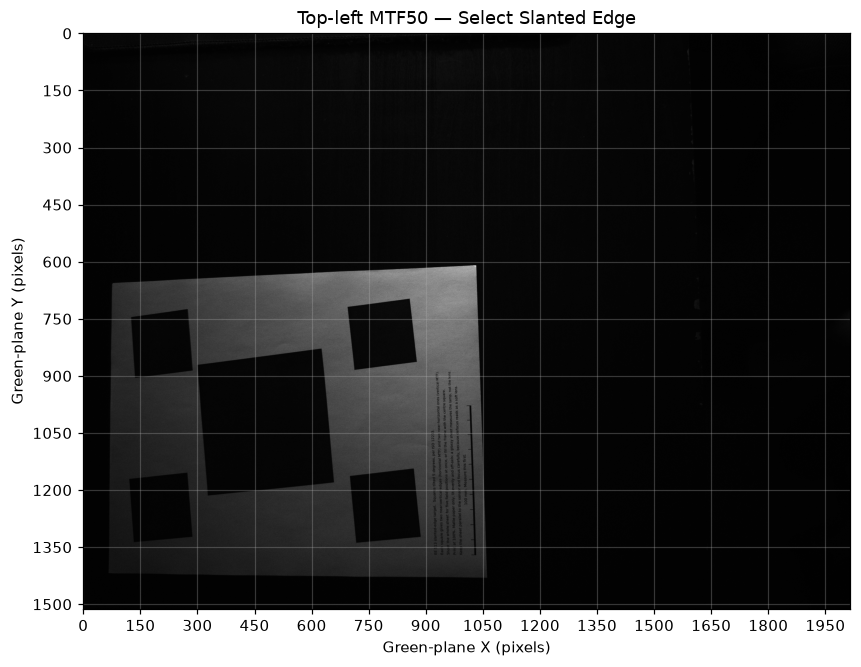

In [22]:
from pathlib import Path
import rawpy
import numpy as np
import matplotlib.pyplot as plt

TOPLEFT_DIR = Path(str(DATA_ROOT / 'MTF50' / 'TopLeft'))

top_left_files = sorted(
    f for f in TOPLEFT_DIR.iterdir()
    if f.is_file() and f.suffix.lower() == ".dng"
)

print("Top-left DNG files:", len(top_left_files))
print([f.name for f in top_left_files])

assert len(top_left_files) == 5

with rawpy.imread(str(top_left_files[0])) as raw:
    mosaic_tl = raw.raw_image_visible.copy()
    pattern_tl = raw.raw_pattern.copy()
    desc_tl = raw.color_desc

assert np.array_equal(pattern_tl, raw_pattern)
assert desc_tl == color_desc

# Same green Bayer lattice used for center MTF50
green_tl = mosaic_tl[
    green_row::2,
    green_col::2
].astype(np.float32)

plt.figure(figsize=(9, 10))
plt.imshow(green_tl, cmap="gray")

plt.xticks(np.arange(0, green_tl.shape[1] + 1, 150))
plt.yticks(np.arange(0, green_tl.shape[0] + 1, 150))

plt.xlabel("Green-plane X (pixels)")
plt.ylabel("Green-plane Y (pixels)")
plt.title("Top-left MTF50 — Select Slanted Edge")
plt.grid(alpha=0.3)
plt.show()


### 2.11 Select the top-left edge ROI

ROI dimensions: (200, 120)
ROI minimum DN: 526.0
ROI maximum DN: 922.0


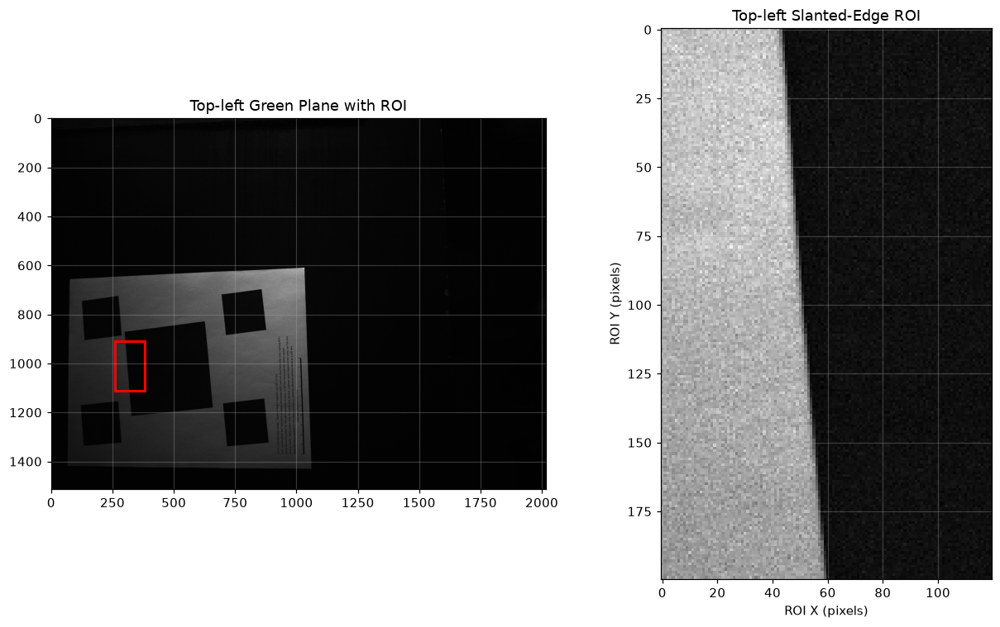

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Top-left green-plane ROI
tl_x1, tl_x2 = 260, 380
tl_y1, tl_y2 = 910, 1110

roi_tl = green_tl[tl_y1:tl_y2, tl_x1:tl_x2]

print("ROI dimensions:", roi_tl.shape)
print("ROI minimum DN:", np.min(roi_tl))
print("ROI maximum DN:", np.max(roi_tl))

fig, ax = plt.subplots(1, 2, figsize=(12, 7))

ax[0].imshow(green_tl, cmap="gray")
ax[0].add_patch(
    Rectangle(
        (tl_x1, tl_y1),
        tl_x2 - tl_x1,
        tl_y2 - tl_y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)
ax[0].set_title("Top-left Green Plane with ROI")

ax[1].imshow(roi_tl, cmap="gray")
ax[1].set_title("Top-left Slanted-Edge ROI")
ax[1].set_xlabel("ROI X (pixels)")
ax[1].set_ylabel("ROI Y (pixels)")

plt.tight_layout()
plt.show()


### 2.12 Measure MTF50 for the first top-left capture

In [24]:
# Top-left MTF50 — first capture
mtf50_tl, angle_tl = measure_mtf50(roi_tl)

print("=== TOP-LEFT MTF50 — FIRST CAPTURE ===")
print(f"Edge angle: {angle_tl:.3f} degrees")
print(f"MTF50: {mtf50_tl:.4f} cycles/green-plane pixel")
print("Green-plane Nyquist: 0.5000 cycles/pixel")

# Check the recommended 3–7 degree range
if 3 <= angle_tl <= 7:
    print("PASS: Edge angle is within the recommended range")
else:
    print("CHECK: Edge angle is outside the recommended range")


=== TOP-LEFT MTF50 — FIRST CAPTURE ===
Edge angle: 4.581 degrees
MTF50: 0.2426 cycles/green-plane pixel
Green-plane Nyquist: 0.5000 cycles/pixel
PASS: Edge angle is within the recommended range


### 2.13 Measure top-left MTF50 across five captures

IMG_5208.DNG: MTF50 = 0.2426 cy/green-px, angle = 4.58°
IMG_5209.DNG: MTF50 = 0.2547 cy/green-px, angle = 4.73°
IMG_5210.DNG: MTF50 = 0.2403 cy/green-px, angle = 4.69°
IMG_5211.DNG: MTF50 = 0.2448 cy/green-px, angle = 4.59°
IMG_5212.DNG: MTF50 = 0.2500 cy/green-px, angle = 4.56°

=== TOP-LEFT MTF50 SUMMARY ===
Captures: 5
Mean MTF50: 0.2465 cy/green-px
Sample standard deviation: 0.0058 cy/green-px


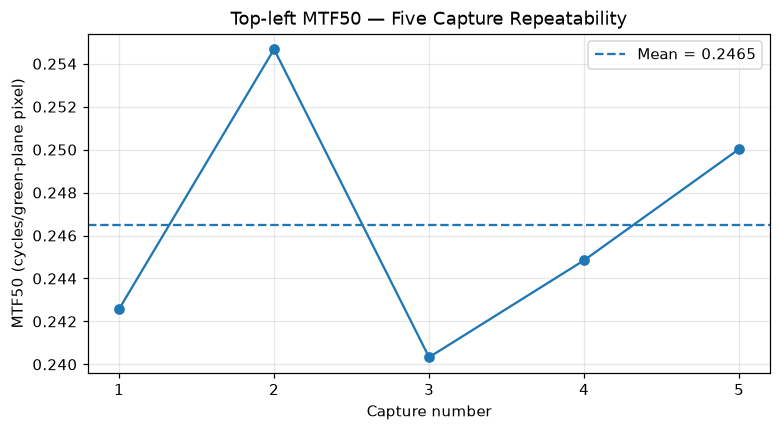

In [25]:
import rawpy
import numpy as np
import matplotlib.pyplot as plt

tl_results = []
tl_angles = []

for file in top_left_files:
    with rawpy.imread(str(file)) as raw:
        mosaic_i = raw.raw_image_visible.copy()

        assert np.array_equal(raw.raw_pattern, raw_pattern)
        assert raw.color_desc == color_desc

    green_i = mosaic_i[
        green_row::2,
        green_col::2
    ].astype(np.float32)

    roi_i = green_i[tl_y1:tl_y2, tl_x1:tl_x2]

    mtf_i, angle_i = measure_mtf50(roi_i)

    tl_results.append(mtf_i)
    tl_angles.append(angle_i)

    print(
        f"{file.name}: "
        f"MTF50 = {mtf_i:.4f} cy/green-px, "
        f"angle = {angle_i:.2f}°"
    )

tl_results = np.array(tl_results)
tl_angles = np.array(tl_angles)

tl_mean = np.mean(tl_results)
tl_std = np.std(tl_results, ddof=1)

print("\n=== TOP-LEFT MTF50 SUMMARY ===")
print(f"Captures: {len(tl_results)}")
print(f"Mean MTF50: {tl_mean:.4f} cy/green-px")
print(f"Sample standard deviation: {tl_std:.4f} cy/green-px")

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(tl_results)+1), tl_results, "o-")
plt.axhline(tl_mean, linestyle="--",
            label=f"Mean = {tl_mean:.4f}")

plt.xlabel("Capture number")
plt.ylabel("MTF50 (cycles/green-plane pixel)")
plt.title("Top-left MTF50 — Five Capture Repeatability")
plt.xticks(np.arange(1, len(tl_results)+1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 2.14 Load top-right RAW captures

Top-right DNG files: 5
['IMG_5223.DNG', 'IMG_5224.DNG', 'IMG_5225.DNG', 'IMG_5226.DNG', 'IMG_5227.DNG']


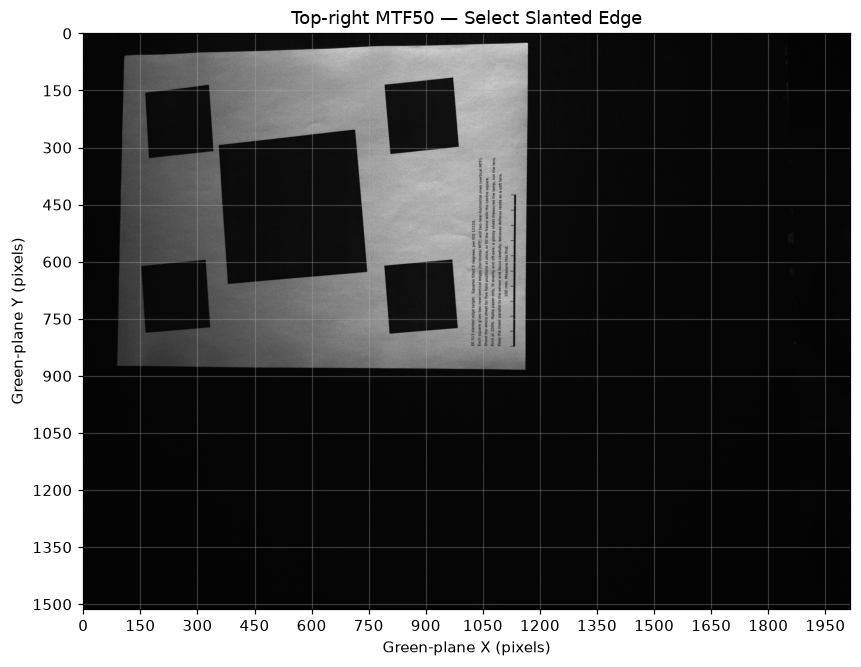

In [26]:
from pathlib import Path
import rawpy
import numpy as np
import matplotlib.pyplot as plt

TOPRIGHT_DIR = Path(str(DATA_ROOT / 'MTF50' / 'TopRight'))

top_right_files = sorted(
    f for f in TOPRIGHT_DIR.iterdir()
    if f.is_file() and f.suffix.lower() == ".dng"
)

print("Top-right DNG files:", len(top_right_files))
print([f.name for f in top_right_files])

assert len(top_right_files) == 5

with rawpy.imread(str(top_right_files[0])) as raw:
    mosaic_tr = raw.raw_image_visible.copy()

    assert np.array_equal(raw.raw_pattern, raw_pattern)
    assert raw.color_desc == color_desc

# Same green Bayer lattice as previous MTF50 measurements
green_tr = mosaic_tr[
    green_row::2,
    green_col::2
].astype(np.float32)

plt.figure(figsize=(9, 10))
plt.imshow(green_tr, cmap="gray")

plt.xticks(np.arange(0, green_tr.shape[1] + 1, 150))
plt.yticks(np.arange(0, green_tr.shape[0] + 1, 150))

plt.xlabel("Green-plane X (pixels)")
plt.ylabel("Green-plane Y (pixels)")
plt.title("Top-right MTF50 — Select Slanted Edge")
plt.grid(alpha=0.3)
plt.show()


### 2.15 Select the top-right edge ROI

ROI dimensions: (200, 120)
ROI minimum DN: 528.0
ROI maximum DN: 1128.0


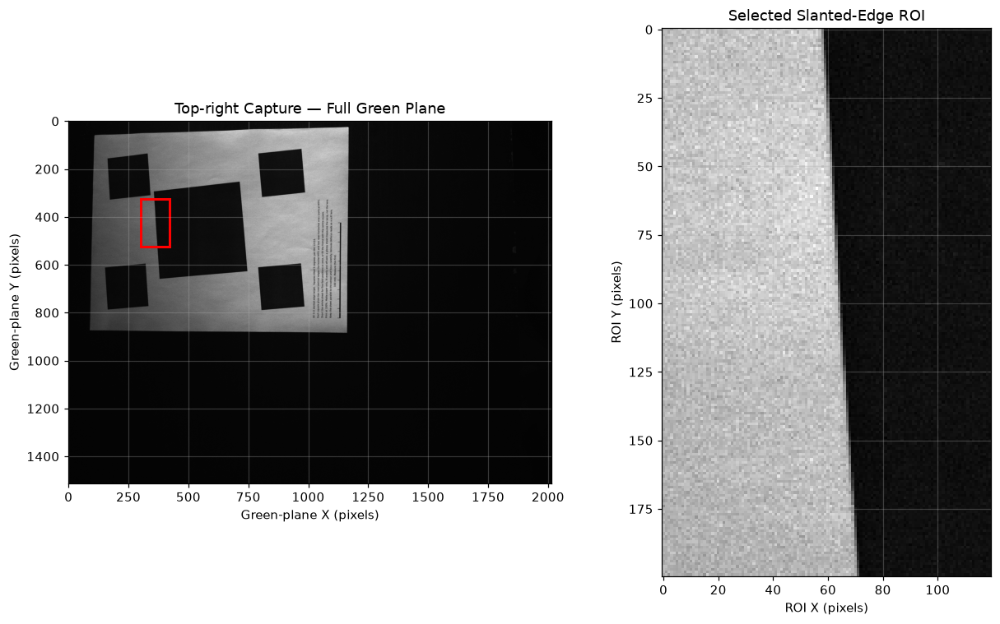

In [27]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Top-right capture set — initial green-plane ROI
tr_x1, tr_x2 = 300, 420
tr_y1, tr_y2 = 325, 525

roi_tr = green_tr[tr_y1:tr_y2, tr_x1:tr_x2]

print("ROI dimensions:", roi_tr.shape)
print("ROI minimum DN:", np.min(roi_tr))
print("ROI maximum DN:", np.max(roi_tr))

fig, ax = plt.subplots(1, 2, figsize=(12, 7))

ax[0].imshow(green_tr, cmap="gray")
ax[0].add_patch(
    Rectangle(
        (tr_x1, tr_y1),
        tr_x2 - tr_x1,
        tr_y2 - tr_y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)
ax[0].set_title("Top-right Capture — Full Green Plane")
ax[0].set_xlabel("Green-plane X (pixels)")
ax[0].set_ylabel("Green-plane Y (pixels)")

ax[1].imshow(roi_tr, cmap="gray")
ax[1].set_title("Selected Slanted-Edge ROI")
ax[1].set_xlabel("ROI X (pixels)")
ax[1].set_ylabel("ROI Y (pixels)")

plt.tight_layout()
plt.show()

### 2.16 Measure MTF50 for the first top-right capture

In [28]:
# First verify the new ROI coordinates are defined
print("ROI:", tr_x1, tr_x2, tr_y1, tr_y2)

# Measure first top-right capture
mtf50_tr, angle_tr = measure_mtf50(roi_tr)

print("=== TOP-RIGHT MTF50 — FIRST CAPTURE ===")
print(f"Edge angle: {angle_tr:.3f} degrees")
print(f"MTF50: {mtf50_tr:.4f} cy/green-px")

if 3 <= angle_tr <= 7:
    print("PASS: Edge angle within 3–7 degrees")
else:
    print("CHECK: Edge angle outside recommended range")


ROI: 300 420 325 525
=== TOP-RIGHT MTF50 — FIRST CAPTURE ===
Edge angle: 3.653 degrees
MTF50: 0.3180 cy/green-px
PASS: Edge angle within 3–7 degrees


### 2.17 Measure top-right MTF50 across five captures

IMG_5223.DNG: MTF50 = 0.3180 cy/green-px, angle = 3.65°
IMG_5224.DNG: MTF50 = 0.3042 cy/green-px, angle = 3.75°
IMG_5225.DNG: MTF50 = 0.3074 cy/green-px, angle = 3.63°
IMG_5226.DNG: MTF50 = 0.3033 cy/green-px, angle = 3.54°
IMG_5227.DNG: MTF50 = 0.3182 cy/green-px, angle = 3.26°

=== TOP-RIGHT MTF50 SUMMARY ===
Captures: 5
Mean MTF50: 0.3102 cy/green-px
Sample standard deviation: 0.0073 cy/green-px


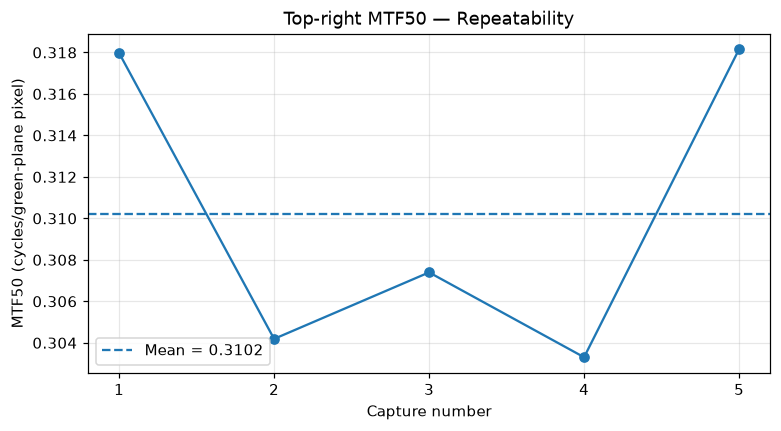

In [29]:
tr_results = []
tr_angles = []

for file in top_right_files:
    with rawpy.imread(str(file)) as raw:
        mosaic_i = raw.raw_image_visible.copy()

        assert np.array_equal(raw.raw_pattern, raw_pattern)
        assert raw.color_desc == color_desc

    green_i = mosaic_i[
        green_row::2,
        green_col::2
    ].astype(np.float32)

    roi_i = green_i[tr_y1:tr_y2, tr_x1:tr_x2]

    mtf_i, angle_i = measure_mtf50(roi_i)

    tr_results.append(mtf_i)
    tr_angles.append(angle_i)

    print(
        f"{file.name}: MTF50 = {mtf_i:.4f} cy/green-px, "
        f"angle = {angle_i:.2f}°"
    )

tr_results = np.array(tr_results)
tr_mean = np.mean(tr_results)
tr_std = np.std(tr_results, ddof=1)

print("\n=== TOP-RIGHT MTF50 SUMMARY ===")
print(f"Captures: {len(tr_results)}")
print(f"Mean MTF50: {tr_mean:.4f} cy/green-px")
print(f"Sample standard deviation: {tr_std:.4f} cy/green-px")

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(tr_results)+1), tr_results, "o-")
plt.axhline(tr_mean, linestyle="--",
            label=f"Mean = {tr_mean:.4f}")
plt.xlabel("Capture number")
plt.ylabel("MTF50 (cycles/green-plane pixel)")
plt.title("Top-right MTF50 — Repeatability")
plt.xticks(range(1, len(tr_results)+1))
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 2.18 Load bottom-left RAW captures

Bottom-left DNG files: 5
['IMG_5228.DNG', 'IMG_5229.DNG', 'IMG_5230.DNG', 'IMG_5231.DNG', 'IMG_5232.DNG']


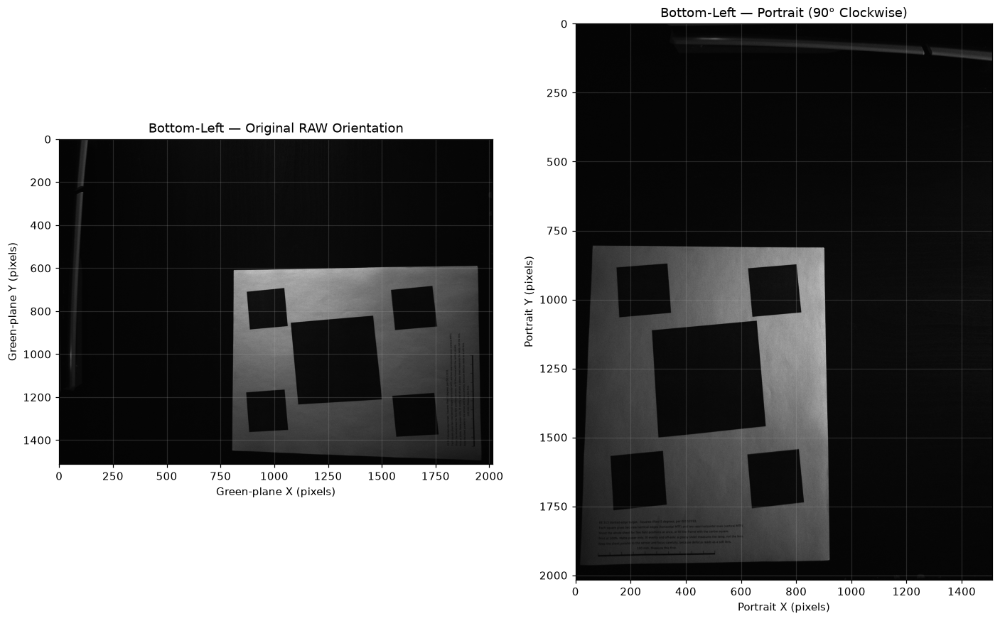

In [30]:
from pathlib import Path
import rawpy
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Bottom-left MTF50 photographs
BOTTOMLEFT_DIR = Path(str(DATA_ROOT / 'MTF50' / 'BottomLeft'))

bottom_left_files = sorted(
    f for f in BOTTOMLEFT_DIR.iterdir()
    if f.is_file() and f.suffix.lower() == ".dng"
)

print("Bottom-left DNG files:", len(bottom_left_files))
print([f.name for f in bottom_left_files])

assert len(bottom_left_files) == 5, (
    "Expected five BottomLeft RAW DNG images"
)

# Load first RAW photograph
with rawpy.imread(str(bottom_left_files[0])) as raw:
    mosaic_bl = raw.raw_image_visible.copy()

    # Verify same Bayer CFA as previous measurements
    assert np.array_equal(raw.raw_pattern, raw_pattern)
    assert raw.color_desc == color_desc

# Extract same green Bayer plane
green_bl = mosaic_bl[
    green_row::2,
    green_col::2
].astype(np.float32)

# Rotate for visualization ONLY
green_bl_portrait = cv2.rotate(
    green_bl,
    cv2.ROTATE_90_CLOCKWISE
)

fig, axes = plt.subplots(1, 2, figsize=(13, 8))

axes[0].imshow(green_bl, cmap="gray")
axes[0].set_title("Bottom-Left — Original RAW Orientation")
axes[0].set_xlabel("Green-plane X (pixels)")
axes[0].set_ylabel("Green-plane Y (pixels)")
axes[0].grid(alpha=0.2)

axes[1].imshow(green_bl_portrait, cmap="gray")
axes[1].set_title("Bottom-Left — Portrait (90° Clockwise)")
axes[1].set_xlabel("Portrait X (pixels)")
axes[1].set_ylabel("Portrait Y (pixels)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


### 2.19 Select the bottom-left edge ROI

ROI dimensions: (200, 120)
ROI minimum DN: 524.0
ROI maximum DN: 1092.0


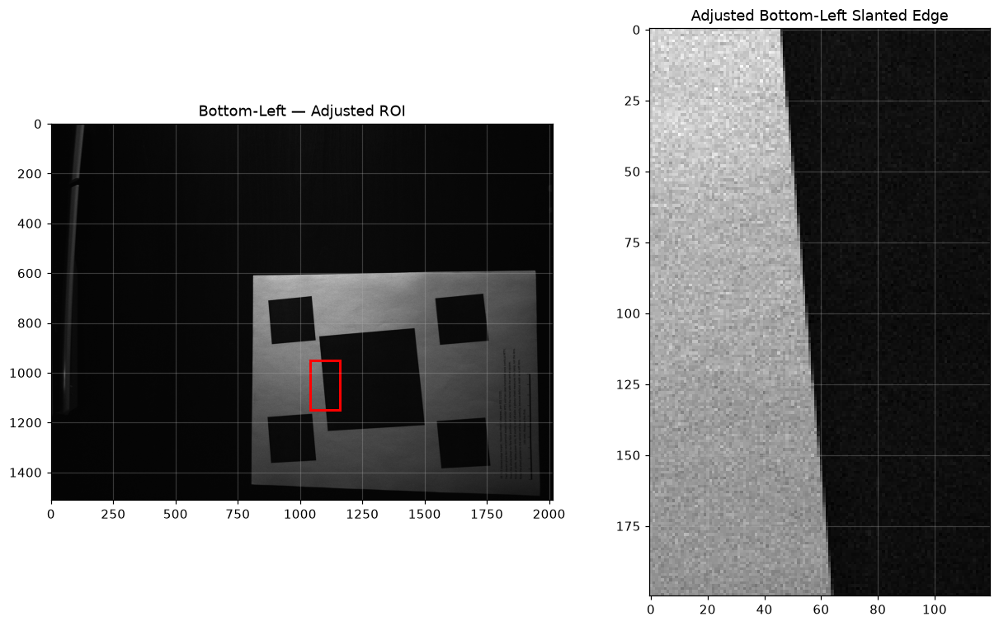

In [31]:

# Adjusted Bottom-Left ROI — green-plane coordinates
bl_x1, bl_x2 = 1040, 1160
bl_y1, bl_y2 = 950, 1150

roi_bl = green_bl[bl_y1:bl_y2, bl_x1:bl_x2]

print("ROI dimensions:", roi_bl.shape)
print("ROI minimum DN:", np.min(roi_bl))
print("ROI maximum DN:", np.max(roi_bl))

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

axes[0].imshow(green_bl, cmap="gray")
axes[0].add_patch(
    Rectangle(
        (bl_x1, bl_y1),
        bl_x2 - bl_x1,
        bl_y2 - bl_y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)
axes[0].set_title("Bottom-Left — Adjusted ROI")
axes[1].imshow(roi_bl, cmap="gray")
axes[1].set_title("Adjusted Bottom-Left Slanted Edge")

plt.tight_layout()
plt.show()


### 2.20 Measure MTF50 for the first bottom-left capture

In [32]:
# Bottom-Left MTF50 — First capture
mtf50_bl, angle_bl = measure_mtf50(roi_bl)

print("=== BOTTOM-LEFT MTF50 — FIRST CAPTURE ===")
print(f"Edge angle: {angle_bl:.3f} degrees")
print(f"MTF50: {mtf50_bl:.4f} cy/green-px")

if 3 <= angle_bl <= 7:
    print("PASS: Edge angle within recommended range")
else:
    print("CHECK: Edge angle outside 3–7 degrees")


=== BOTTOM-LEFT MTF50 — FIRST CAPTURE ===
Edge angle: 5.257 degrees
MTF50: 0.4207 cy/green-px
PASS: Edge angle within recommended range


### 2.21 Measure bottom-left MTF50 across five captures

IMG_5228.DNG: MTF50 = 0.4207 cy/green-px, angle = 5.26°
IMG_5229.DNG: MTF50 = 0.4289 cy/green-px, angle = 5.13°
IMG_5230.DNG: MTF50 = 0.4269 cy/green-px, angle = 5.03°
IMG_5231.DNG: MTF50 = 0.4191 cy/green-px, angle = 4.96°
IMG_5232.DNG: MTF50 = 0.4296 cy/green-px, angle = 4.89°

=== BOTTOM-LEFT MTF50 SUMMARY ===
Captures: 5
Mean MTF50: 0.4251 cy/green-px
Sample standard deviation: 0.0048 cy/green-px
PASS: All edge angles within 3–7 degrees


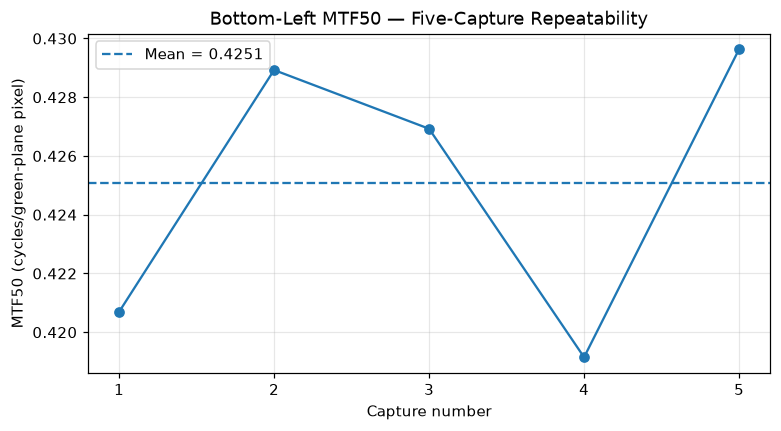

In [33]:
import rawpy
import numpy as np
import matplotlib.pyplot as plt

# Bottom-Left ROI (original RAW green-plane coordinates)
bl_x1, bl_x2 = 1040, 1160
bl_y1, bl_y2 = 950, 1150

bl_results = []
bl_angles = []

for file in bottom_left_files:

    with rawpy.imread(str(file)) as raw:
        mosaic_i = raw.raw_image_visible.copy()

        # Check CFA consistency
        assert np.array_equal(raw.raw_pattern, raw_pattern)
        assert raw.color_desc == color_desc

    # Extract the same green Bayer lattice
    green_i = mosaic_i[
        green_row::2,
        green_col::2
    ].astype(np.float32)

    # Select the Bottom-Left ROI
    roi_i = green_i[
        bl_y1:bl_y2,
        bl_x1:bl_x2
    ]

    # Calculate MTF50 and edge angle
    mtf_i, angle_i = measure_mtf50(roi_i)

    bl_results.append(mtf_i)
    bl_angles.append(angle_i)

    print(
        f"{file.name}: "
        f"MTF50 = {mtf_i:.4f} cy/green-px, "
        f"angle = {angle_i:.2f}°"
    )

# Calculate repeatability
bl_results = np.array(bl_results)
bl_angles = np.array(bl_angles)

bl_mean = np.mean(bl_results)
bl_std = np.std(bl_results, ddof=1)

print("\n=== BOTTOM-LEFT MTF50 SUMMARY ===")
print(f"Captures: {len(bl_results)}")
print(f"Mean MTF50: {bl_mean:.4f} cy/green-px")
print(f"Sample standard deviation: {bl_std:.4f} cy/green-px")

# Check all edge angles
if np.all((bl_angles >= 3) & (bl_angles <= 7)):
    print("PASS: All edge angles within 3–7 degrees")
else:
    print("CHECK: One or more edge angles outside 3–7 degrees")

# Display repeatability
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, len(bl_results) + 1),
    bl_results,
    "o-"
)

plt.axhline(
    bl_mean,
    linestyle="--",
    label=f"Mean = {bl_mean:.4f}"
)

plt.xlabel("Capture number")
plt.ylabel("MTF50 (cycles/green-plane pixel)")
plt.title("Bottom-Left MTF50 — Five-Capture Repeatability")
plt.xticks(range(1, len(bl_results) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### 2.22 Load bottom-right RAW captures

Bottom-Right DNG files: 5
['IMG_5233.DNG', 'IMG_5234.DNG', 'IMG_5235.DNG', 'IMG_5236.DNG', 'IMG_5237.DNG']


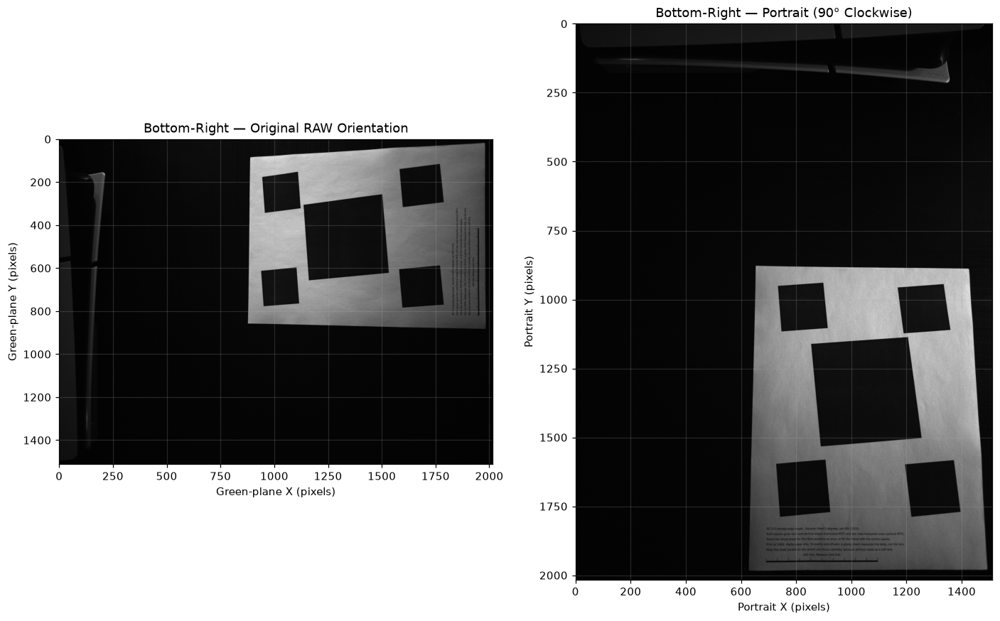

In [34]:
import rawpy
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Bottom-Right MTF50 photographs
BOTTOMRIGHT_DIR = Path(str(DATA_ROOT / 'MTF50' / 'BottomRight'))

bottom_right_files = sorted(
    f for f in BOTTOMRIGHT_DIR.iterdir()
    if f.is_file() and f.suffix.lower() == ".dng"
)

print("Bottom-Right DNG files:", len(bottom_right_files))
print([f.name for f in bottom_right_files])

assert len(bottom_right_files) == 5, (
    "Expected five BottomRight RAW DNG images"
)

# Load first RAW photograph
with rawpy.imread(str(bottom_right_files[0])) as raw:
    mosaic_br = raw.raw_image_visible.copy()

    # Verify same Bayer CFA as previous captures
    assert np.array_equal(raw.raw_pattern, raw_pattern)
    assert raw.color_desc == color_desc

# Extract the same green Bayer lattice as before
green_br = mosaic_br[
    green_row::2,
    green_col::2
].astype(np.float32)

# Rotate 90 degrees clockwise for visualization only
green_br_portrait = cv2.rotate(
    green_br,
    cv2.ROTATE_90_CLOCKWISE
)

fig, axes = plt.subplots(1, 2, figsize=(13, 8))

axes[0].imshow(green_br, cmap="gray")
axes[0].set_title("Bottom-Right — Original RAW Orientation")
axes[0].set_xlabel("Green-plane X (pixels)")
axes[0].set_ylabel("Green-plane Y (pixels)")
axes[0].grid(alpha=0.2)

axes[1].imshow(green_br_portrait, cmap="gray")
axes[1].set_title("Bottom-Right — Portrait (90° Clockwise)")
axes[1].set_xlabel("Portrait X (pixels)")
axes[1].set_ylabel("Portrait Y (pixels)")
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()


### 2.23 Select the bottom-right edge ROI

ROI dimensions: (200, 120)
ROI minimum DN: 557.0
ROI maximum DN: 1592.0


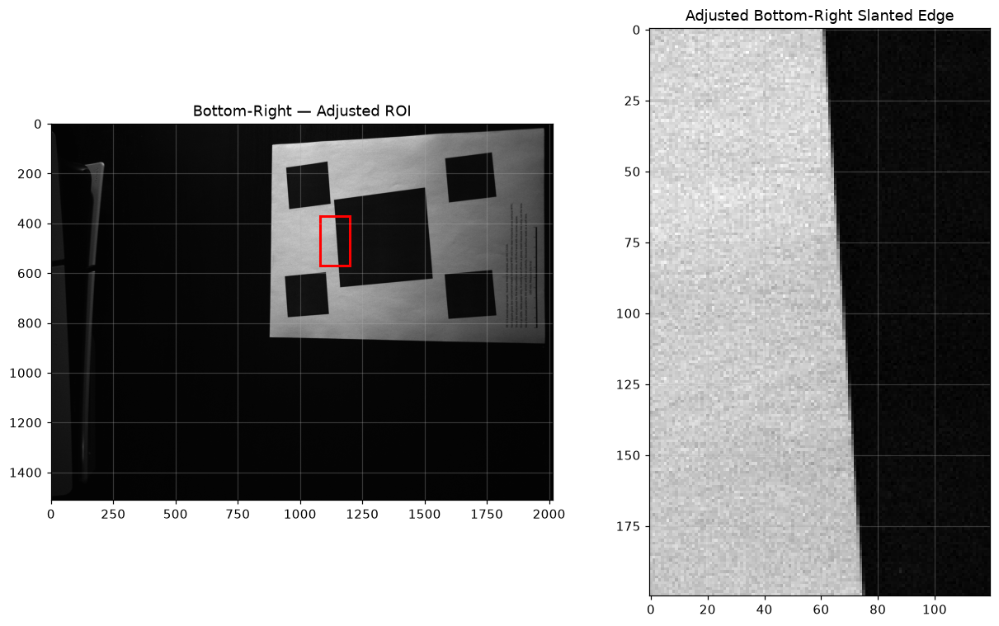

In [35]:
br_x1, br_x2 = 1080, 1200
br_y1, br_y2 = 370, 570

roi_br = green_br[br_y1:br_y2, br_x1:br_x2]

print("ROI dimensions:", roi_br.shape)
print("ROI minimum DN:", np.min(roi_br))
print("ROI maximum DN:", np.max(roi_br))

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

axes[0].imshow(green_br, cmap="gray")
axes[0].add_patch(
    Rectangle(
        (br_x1, br_y1),
        br_x2 - br_x1,
        br_y2 - br_y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
)
axes[0].set_title("Bottom-Right — Adjusted ROI")
axes[1].imshow(roi_br, cmap="gray")
axes[1].set_title("Adjusted Bottom-Right Slanted Edge")

plt.tight_layout()
plt.show()


### 2.24 Measure bottom-right MTF50 across five captures

IMG_5233.DNG: MTF50 = 0.3738 cy/green-px, angle = 4.02°
IMG_5234.DNG: MTF50 = 0.3823 cy/green-px, angle = 3.86°
IMG_5235.DNG: MTF50 = 0.3684 cy/green-px, angle = 3.64°
IMG_5236.DNG: MTF50 = 0.3731 cy/green-px, angle = 3.60°
IMG_5237.DNG: MTF50 = 0.3756 cy/green-px, angle = 3.80°

=== BOTTOM-RIGHT MTF50 SUMMARY ===
Captures: 5
Mean MTF50: 0.3746 cy/green-px
Sample standard deviation: 0.0050 cy/green-px
PASS: All edge angles within 3–7 degrees


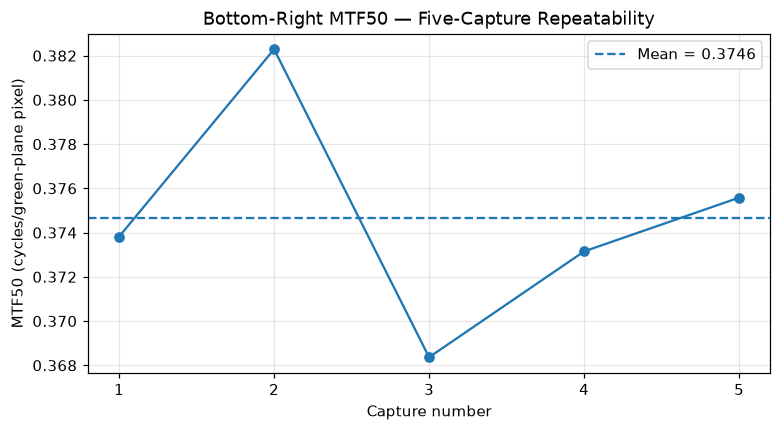

In [36]:

import rawpy
import numpy as np
import matplotlib.pyplot as plt

# Final Bottom-Right ROI (original green-plane coordinates)
br_x1, br_x2 = 1080, 1200
br_y1, br_y2 = 370, 570

br_results = []
br_angles = []

for file in bottom_right_files:

    with rawpy.imread(str(file)) as raw:
        mosaic_i = raw.raw_image_visible.copy()

        # Verify consistent CFA
        assert np.array_equal(raw.raw_pattern, raw_pattern)
        assert raw.color_desc == color_desc

    # Extract the same green Bayer lattice
    green_i = mosaic_i[
        green_row::2,
        green_col::2
    ].astype(np.float32)

    # Apply the selected ROI
    roi_i = green_i[
        br_y1:br_y2,
        br_x1:br_x2
    ]

    mtf_i, angle_i = measure_mtf50(roi_i)

    br_results.append(mtf_i)
    br_angles.append(angle_i)

    print(
        f"{file.name}: "
        f"MTF50 = {mtf_i:.4f} cy/green-px, "
        f"angle = {angle_i:.2f}°"
    )

br_results = np.array(br_results)
br_angles = np.array(br_angles)

br_mean = np.mean(br_results)
br_std = np.std(br_results, ddof=1)

print("\n=== BOTTOM-RIGHT MTF50 SUMMARY ===")
print(f"Captures: {len(br_results)}")
print(f"Mean MTF50: {br_mean:.4f} cy/green-px")
print(f"Sample standard deviation: {br_std:.4f} cy/green-px")

# Verify all edge angles
if np.all((br_angles >= 3) & (br_angles <= 7)):
    print("PASS: All edge angles within 3–7 degrees")
else:
    print("CHECK: Some edge angles are outside 3–7 degrees")

# Repeatability plot (display only)
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(br_results) + 1),
    br_results,
    "o-"
)

plt.axhline(
    br_mean,
    linestyle="--",
    label=f"Mean = {br_mean:.4f}"
)

plt.xlabel("Capture number")
plt.ylabel("MTF50 (cycles/green-plane pixel)")
plt.title("Bottom-Right MTF50 — Five-Capture Repeatability")
plt.xticks(range(1, len(br_results) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.show()


### 2.25 Compare measurement locations on the sensor

=== PROJECT 1 MTF50 ROI LOCATION VERIFICATION ===
Center       : X =  49.0% of width, Y =  39.2% of height
Top-left     : X =  33.1% of width, Y =  15.9% of height
Top-right    : X =  71.8% of width, Y =  18.8% of height
Bottom-left  : X =  30.5% of width, Y =  54.6% of height
Bottom-right : X =  68.8% of width, Y =  56.5% of height


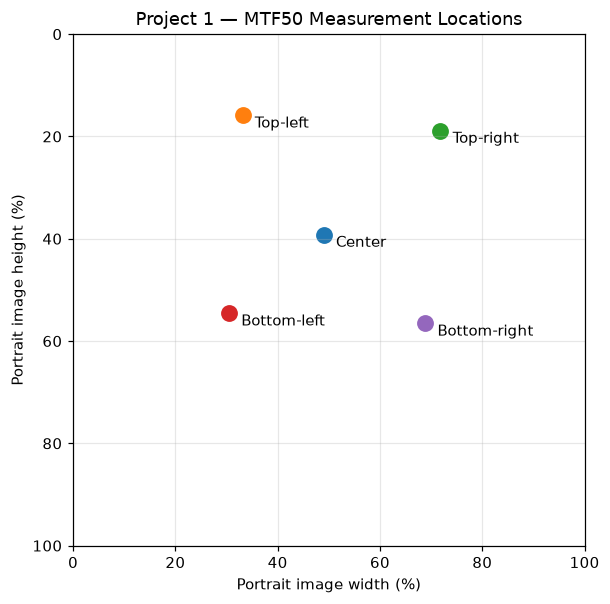

In [37]:

import numpy as np
import matplotlib.pyplot as plt

# Original RAW green-plane dimensions
raw_h, raw_w = green.shape

# Measured ROI coordinates: (x1, x2, y1, y2)
roi_locations = {
    "Center":       (730, 850, 640, 900),
    "Top-left":     (260, 380, 910, 1110),
    "Top-right":    (320, 440, 325, 525),
    "Bottom-left":  (1040, 1160, 950, 1150),
    "Bottom-right": (1080, 1200, 370, 570)
}

print("=== PROJECT 1 MTF50 ROI LOCATION VERIFICATION ===")

portrait_locations = {}

for name, (x1, x2, y1, y2) in roi_locations.items():

    # Center of selected ROI in RAW coordinates
    x_raw = (x1 + x2) / 2
    y_raw = (y1 + y2) / 2

    # RAW -> portrait (90 degrees clockwise)
    x_portrait = raw_h - 1 - y_raw
    y_portrait = x_raw

    # Portrait image dimensions
    portrait_w = raw_h
    portrait_h = raw_w

    x_percent = 100 * x_portrait / portrait_w
    y_percent = 100 * y_portrait / portrait_h

    portrait_locations[name] = (x_percent, y_percent)

    print(
        f"{name:13s}: "
        f"X = {x_percent:5.1f}% of width, "
        f"Y = {y_percent:5.1f}% of height"
    )

# Display all measurement locations
fig, ax = plt.subplots(figsize=(6, 9))

ax.set_xlim(0, 100)
ax.set_ylim(100, 0)

for name, (xp, yp) in portrait_locations.items():
    ax.scatter(xp, yp, s=100)
    ax.annotate(
        name,
        (xp, yp),
        xytext=(8, -8),
        textcoords="offset points"
    )

ax.set_title("Project 1 — MTF50 Measurement Locations")
ax.set_xlabel("Portrait image width (%)")
ax.set_ylabel("Portrait image height (%)")
ax.set_aspect("equal")
ax.grid(alpha=0.3)

plt.show()


## 3. Sensor noise — photon-transfer curve and dark frames

I captured 10 pairs of flat fields at ISO 64 and measured the center 128 × 128 green patch. I used the difference of each pair to reduce fixed spatial patterns.

Pair 10 is still shown in the analysis, but I kept it out of the baseline weighted PTC fit because the measured variance did not follow the earlier exposure pairs. I measured read noise separately from dark frames because the fit intercept did not agree with the dark-frame estimate.

### 3.1 Set up flat-field data and metadata tools

In [38]:
from pathlib import Path
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import rawpy
import tifffile

# New flat-field capture folder
FLAT_DIR = Path(str(DATA_ROOT / 'FlatFields'))

# Existing dark-frame capture folder
# Change this if your dark frames are elsewhere
DARK_DIR = Path(str(DATA_ROOT / 'Part1_RAW_Dark'))

PATCH_SIZE = 128
EXPECTED_ISO = 64

print("=== PROJECT 1 PART 3 SETUP ===")
print("Flat-field folder exists:", FLAT_DIR.exists())
print("Dark-frame folder exists:", DARK_DIR.exists())
print("Patch size:", PATCH_SIZE)
print("Expected ISO:", EXPECTED_ISO)


=== PROJECT 1 PART 3 SETUP ===
Flat-field folder exists: True
Dark-frame folder exists: True
Patch size: 128
Expected ISO: 64


### 3.2 Check the new flat-field capture inventory

In [39]:

# ==================================================
# STEP 1 — NEW FLAT-FIELD INVENTORY
# ==================================================

assert FLAT_DIR.exists(), f"Folder not found: {FLAT_DIR}"

flat_files = sorted(
    f for f in FLAT_DIR.iterdir()
    if f.is_file() and f.suffix.lower() == ".dng"
)

print("=== NEW FLAT-FIELD INVENTORY ===")
print("Total DNG files:", len(flat_files))

for i, file in enumerate(flat_files, start=1):
    print(f"{i:02d}. {file.name}")

assert len(flat_files) == 20, (
    f"Expected 20 DNG files, found {len(flat_files)}"
)

print("\nPASS: All 20 new flat-field DNGs found.")


=== NEW FLAT-FIELD INVENTORY ===
Total DNG files: 20
01. 1_10 (1).DNG
02. 1_10.DNG
03. 1_13 (1).DNG
04. 1_13.DNG
05. 1_15 (1).DNG
06. 1_15.DNG
07. 1_20 (1).DNG
08. 1_20.DNG
09. 1_25 (1).DNG
10. 1_25.DNG
11. 1_30 (1).DNG
12. 1_30.DNG
13. 1_40 (1).DNG
14. 1_40.DNG
15. 1_5 (1).DNG
16. 1_5.DNG
17. 1_6 (1).DNG
18. 1_6.DNG
19. 1_8 (1).DNG
20. 1_8.DNG

PASS: All 20 new flat-field DNGs found.


### 3.3 Read and check capture metadata

In [40]:

# =====================================================
# STEP 2 — CAPTURE METADATA DIAGNOSTIC
# =====================================================

from pathlib import Path
from collections import defaultdict
import numpy as np
import tifffile

# Folder containing the 20 new flat-field DNG images
FLAT_DIR = Path(str(DATA_ROOT / 'FlatFields'))

flat_files = sorted(FLAT_DIR.glob("*.DNG"))

if len(flat_files) == 0:
    raise FileNotFoundError(
        f"No DNG files found in {FLAT_DIR}"
    )

print("Total DNG files found:", len(flat_files))


# -----------------------------------------------------
# Read DNG metadata without exifread
# -----------------------------------------------------


from pathlib import Path
import struct

def get_capture_metadata(path):
    path = Path(path)

    with open(path, "rb") as f:
        header = f.read(8)

        # Determine TIFF byte order
        if header[:2] == b"II":
            endian = "<"
        elif header[:2] == b"MM":
            endian = ">"
        else:
            raise ValueError(f"Not a TIFF/DNG file: {path.name}")

        def u16(data):
            return struct.unpack(endian + "H", data)[0]

        def u32(data):
            return struct.unpack(endian + "I", data)[0]

        if u16(header[2:4]) != 42:
            raise ValueError("Expected classic TIFF/DNG format")

        def read_ifd(offset):
            f.seek(offset)
            count = u16(f.read(2))
            tags = {}

            for _ in range(count):
                entry = f.read(12)

                tag, dtype, n, raw_offset = struct.unpack(
                    endian + "HHII", entry
                )

                tags[tag] = (dtype, n, raw_offset, entry[8:12])

            return tags

        def read_value(tags, tag_id):
            if tag_id not in tags:
                return None

            dtype, count, offset, inline = tags[tag_id]

            sizes = {1: 1, 2: 1, 3: 2, 4: 4, 5: 8}
            if dtype not in sizes:
                return None

            total_size = sizes[dtype] * count

            if total_size <= 4:
                data = inline[:total_size]
            else:
                f.seek(offset)
                data = f.read(total_size)

            if dtype == 2:
                return data.rstrip(b"\x00").decode(
                    "utf-8", errors="replace"
                )

            if dtype == 3:
                values = struct.unpack(
                    endian + str(count) + "H", data
                )
            elif dtype == 4:
                values = struct.unpack(
                    endian + str(count) + "I", data
                )
            elif dtype == 5:
                values = []
                for i in range(count):
                    num, den = struct.unpack(
                        endian + "II", data[i*8:(i+1)*8]
                    )
                    values.append(num / den if den else float("nan"))
            else:
                values = tuple(data)

            return values[0] if count == 1 else values

        # Main TIFF directory
        main_tags = read_ifd(u32(header[4:8]))

        # EXIF directory pointer (tag 34665)
        exif_offset = read_value(main_tags, 34665)

        if exif_offset is None:
            raise ValueError(
                f"EXIF directory not found in {path.name}"
            )

        exif_tags = read_ifd(int(exif_offset))

        # Standard EXIF tags
        exposure = read_value(exif_tags, 33434)
        iso = read_value(exif_tags, 34855)
        lens = read_value(exif_tags, 42036)

        if lens is None:
            lens = read_value(main_tags, 50708)

        if exposure is None or iso is None:
            raise ValueError(
                f"Exposure or ISO missing in {path.name}"
            )

        return float(exposure), int(iso), str(lens)



# -----------------------------------------------------
# Organize flat fields by actual exposure metadata
# -----------------------------------------------------

flat_groups = defaultdict(list)

print("\n=== NEW FLAT-FIELD METADATA CHECK ===")

for file in flat_files:

    exposure, iso, lens = get_capture_metadata(file)

    # Round only for grouping tiny metadata differences.
    exposure_key = round(exposure, 6)

    flat_groups[exposure_key].append(file)

    print(
        f"{file.name:18s} "
        f"Exposure = {exposure:.6f} s, "
        f"ISO = {iso}, "
        f"Lens = {lens}"
    )


# -----------------------------------------------------
# Exposure group summary
# -----------------------------------------------------

print("\n=== EXPOSURE GROUP SUMMARY ===")

for exposure, files in sorted(flat_groups.items()):

    print(f"\nExposure: {exposure:.6f} s")
    print("Number of captures:", len(files))

    for file in sorted(files):
        print(" ", file.name)


# -----------------------------------------------------
# Final verification
# -----------------------------------------------------

print("\n=== CHECK RESULTS ===")

print("Total files:", len(flat_files))
print("Unique exposure levels:", len(flat_groups))

correct_file_count = len(flat_files) == 20
correct_group_count = len(flat_groups) == 10
correct_pairs = all(
    len(files) == 2
    for files in flat_groups.values()
)

if correct_file_count and correct_group_count and correct_pairs:
    print("PASS: 20 DNG images organized into 10 exposure pairs.")
else:
    print("WARNING: Exposure grouping needs review.")

if any(len(files) != 2 for files in flat_groups.values()):
    print("WARNING: Some exposure levels do not contain exactly 2 images.")



Total DNG files found: 20

=== NEW FLAT-FIELD METADATA CHECK ===
1_10 (1).DNG       Exposure = 0.100000 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_10.DNG           Exposure = 0.100000 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_13 (1).DNG       Exposure = 0.076923 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_13.DNG           Exposure = 0.076923 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_15 (1).DNG       Exposure = 0.066667 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_15.DNG           Exposure = 0.066667 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_20 (1).DNG       Exposure = 0.050000 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_20.DNG           Exposure = 0.050000 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_25 (1).DNG       Exposure = 0.040000 s, ISO = 64, Lens = iPhone 14 Pro back camera 6.86mm f/1.78
1_25.DNG           Exposure = 0.040000 s, IS

### 3.4 Define green-plane RAW loading

In [41]:

import numpy as np
import rawpy

def load_green_raw(path):
    """Extract one green Bayer lattice from a linear RAW DNG."""

    with rawpy.imread(str(path)) as raw:
        pattern = raw.raw_pattern.copy()
        description = raw.color_desc.decode(
            "ascii"
        ).replace("\x00", "")

        green_positions = [
            (r, c)
            for r in range(2)
            for c in range(2)
            if description[int(pattern[r, c])] == "G"
        ]

        assert len(green_positions) == 2

        r, c = green_positions[0]
        channel = int(pattern[r, c])

        green = raw.raw_image_visible[
            r::2, c::2
        ].astype(np.float64).copy()

        metadata = {
            "pattern": pattern,
            "description": description,
            "green_position": (r, c),
            "raw_shape": tuple(raw.raw_image_visible.shape),
            "green_shape": green.shape,
            "black": float(raw.black_level_per_channel[channel]),
            "white": float(raw.white_level),
        }

    return green, metadata


# Verify one capture
test_file = flat_files[0]
green_test, reference_meta = load_green_raw(test_file)

print("=== RAW EXTRACTION VERIFICATION ===")
print("File:", test_file.name)
print("CFA:\n", reference_meta["pattern"])
print("Color descriptions:", reference_meta["description"])
print("Green position:", reference_meta["green_position"])
print("RAW dimensions:", reference_meta["raw_shape"])
print("Green dimensions:", reference_meta["green_shape"])
print("Black level:", reference_meta["black"])
print("White level:", reference_meta["white"])

assert reference_meta["raw_shape"] == (3024, 4032)
assert reference_meta["green_shape"] == (1512, 2016)
assert reference_meta["black"] == 528
assert reference_meta["white"] == 4095

print("\nPASS: Bayer RAW extraction verified.")


=== RAW EXTRACTION VERIFICATION ===
File: 1_10 (1).DNG
CFA:
 [[2 3]
 [1 0]]
Color descriptions: RGBG
Green position: (0, 1)
RAW dimensions: (3024, 4032)
Green dimensions: (1512, 2016)
Black level: 528.0
White level: 4095.0

PASS: Bayer RAW extraction verified.


### 3.5 Check ISO, exposure, and camera consistency

In [42]:

print("=== ALL FLAT-FIELD METADATA VERIFICATION ===")

reference_lens = None

for file in flat_files:
    green, meta = load_green_raw(file)
    exposure, iso, lens = get_capture_metadata(file)

    assert iso == EXPECTED_ISO
    assert np.array_equal(
        meta["pattern"], reference_meta["pattern"]
    )
    assert meta["description"] == reference_meta["description"]
    assert meta["green_position"] == reference_meta["green_position"]
    assert meta["raw_shape"] == reference_meta["raw_shape"]
    assert meta["green_shape"] == reference_meta["green_shape"]
    assert meta["black"] == reference_meta["black"]
    assert meta["white"] == reference_meta["white"]

    if reference_lens is None:
        reference_lens = lens
    else:
        assert lens == reference_lens, (
            f"Lens mismatch in {file.name}"
        )

print("Files checked:", len(flat_files))
print("Camera lens:", reference_lens)
print("ISO:", EXPECTED_ISO)
print("Failures: 0")
print("\nPASS: All new flat-field captures are consistent.")


=== ALL FLAT-FIELD METADATA VERIFICATION ===
Files checked: 20
Camera lens: iPhone 14 Pro back camera 6.86mm f/1.78
ISO: 64
Failures: 0

PASS: All new flat-field captures are consistent.


### 3.6 Define the central 128 × 128 measurement patch

In [43]:

def extract_center_patch(image, size=128):
    """Extract a central square patch in green-plane pixels."""

    h, w = image.shape

    y0 = h // 2 - size // 2
    x0 = w // 2 - size // 2

    patch = image[
        y0:y0 + size,
        x0:x0 + size
    ].copy()

    assert patch.shape == (size, size)
    return patch


patch_test = extract_center_patch(
    green_test, PATCH_SIZE
)

print("=== CENTRAL PATCH VERIFICATION ===")
print("Patch size:", patch_test.shape)
print("Minimum RAW DN:", patch_test.min())
print("Maximum RAW DN:", patch_test.max())
print("Mean RAW DN:", patch_test.mean())
print(
    "Mean above black:",
    patch_test.mean() - reference_meta["black"],
    "DN"
)

print("\nPASS: Central patch extracted.")


=== CENTRAL PATCH VERIFICATION ===
Patch size: (128, 128)
Minimum RAW DN: 961.0
Maximum RAW DN: 1050.0
Mean RAW DN: 1010.72119140625
Mean above black: 482.72119140625 DN

PASS: Central patch extracted.


### 3.7 Calculate paired-frame photon-transfer data

In [44]:

# ==================================================
# STEP 3 — NEW PHOTON-TRANSFER MEASUREMENTS
# ==================================================

import numpy as np

ptc_results = []

for pair_num, (exposure, files) in enumerate(
    sorted(flat_groups.items()), start=1
):
    assert len(files) == 2

    files = sorted(files)

    green_A, meta_A = load_green_raw(files[0])
    green_B, meta_B = load_green_raw(files[1])

    assert meta_A["black"] == meta_B["black"]
    assert meta_A["white"] == meta_B["white"]

    A = extract_center_patch(green_A, PATCH_SIZE)
    B = extract_center_patch(green_B, PATCH_SIZE)

    black = meta_A["black"]

    # Average signal above black
    mean_dn = (A.mean() + B.mean()) / 2 - black

    # Temporal variance using pair subtraction
    difference = A - B
    variance_dn2 = np.var(difference, ddof=1) / 2

    # Brightness stability between captures
    delta_mean = A.mean() - B.mean()

    # Actual RAW sample distribution
    combined = np.concatenate([A.ravel(), B.ravel()])
    values, counts = np.unique(
        combined, return_counts=True
    )

    dominant_index = np.argmax(counts)
    dominant_value = float(values[dominant_index])
    dominant_fraction = counts[dominant_index] / combined.size

    # Previously observed green clipping plateau:
    # diagnostic, not assumed to be a universal white level
    plateau_fraction = np.mean(combined == 3567)

    ptc_results.append({
        "pair": pair_num,
        "exposure_s": exposure,
        "mean_dn": mean_dn,
        "variance_dn2": variance_dn2,
        "ratio": (
            variance_dn2 / mean_dn
            if mean_dn > 0 else np.nan
        ),
        "delta_mean_dn": delta_mean,
        "min_dn": float(combined.min()),
        "max_dn": float(combined.max()),
        "dominant_dn": dominant_value,
        "dominant_fraction": dominant_fraction,
        "plateau_fraction": plateau_fraction,
        "files": [f.name for f in files],
        "pixels": A.size
    })

print("=== NEW PROJECT 1 PHOTON-TRANSFER DATA ===")

print(
    f"{'Pair':>4} {'Time(s)':>8} {'Mean(DN)':>10} "
    f"{'Var(DN2)':>11} {'Var/Mean':>10} "
    f"{'DeltaMean':>10} {'MaxDN':>7} "
    f"{'At3567%':>8} {'Mode%':>7}"
)

for p in ptc_results:
    print(
        f"{p['pair']:>4} "
        f"{p['exposure_s']:>8.4f} "
        f"{p['mean_dn']:>10.2f} "
        f"{p['variance_dn2']:>11.2f} "
        f"{p['ratio']:>10.4f} "
        f"{p['delta_mean_dn']:>+10.2f} "
        f"{p['max_dn']:>7.0f} "
        f"{100*p['plateau_fraction']:>8.2f} "
        f"{100*p['dominant_fraction']:>7.2f}"
    )

assert len(ptc_results) == 10
assert all(p["pixels"] == 16384 for p in ptc_results)

print("\nPASS: All 10 pairs measured.")
print("Clipping and fit eligibility still require review.")


=== NEW PROJECT 1 PHOTON-TRANSFER DATA ===
Pair  Time(s)   Mean(DN)    Var(DN2)   Var/Mean  DeltaMean   MaxDN  At3567%   Mode%
   1   0.0250     127.49       32.21     0.2526      +0.03     678     0.00    6.95
   2   0.0333     170.77       42.50     0.2489      +0.01     724     0.00    6.18
   3   0.0400     191.54       46.26     0.2415      -0.47     749     0.00    6.02
   4   0.0500     240.35       57.10     0.2376      +0.39     804     0.00    5.36
   5   0.0667     321.85       77.18     0.2398      -1.23     886     0.00    4.52
   6   0.0769     368.79       87.94     0.2384      +0.63     934     0.00    4.24
   7   0.1000     482.65      120.45     0.2496      +0.15    1059     0.00    3.95
   8   0.1250     599.75      150.91     0.2516      -1.69    1175     0.00    3.60
   9   0.1667     752.62      186.35     0.2476      +0.90    1336     0.00    3.21
  10   0.2000     976.95      296.12     0.3031      -0.69    1573     0.00    3.45

PASS: All 10 pairs measured.
Cli

### 3.8 Plot the photon-transfer measurements

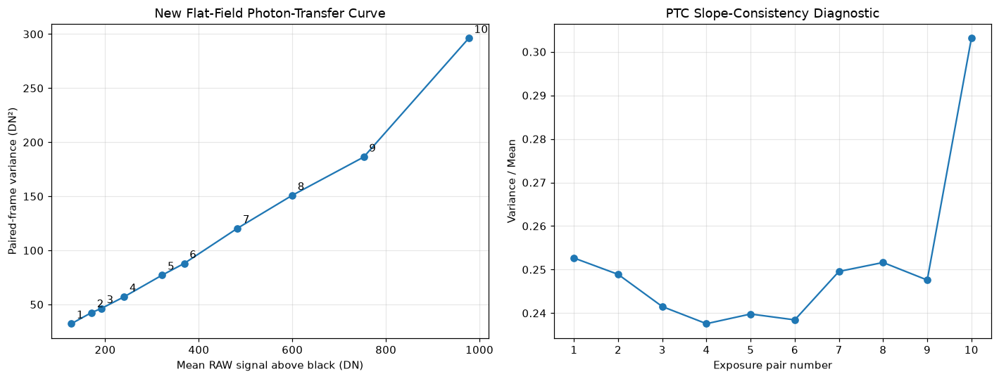

In [45]:

# ==================================================
# STEP 4 — NEW PTC VISUALIZATION
# ==================================================

import matplotlib.pyplot as plt
import numpy as np

means = np.array([
    p["mean_dn"] for p in ptc_results
])

variances = np.array([
    p["variance_dn2"] for p in ptc_results
])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Photon-transfer curve
axes[0].plot(means, variances, "o-")

for p in ptc_results:
    axes[0].annotate(
        str(p["pair"]),
        (p["mean_dn"], p["variance_dn2"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

axes[0].set_xlabel("Mean RAW signal above black (DN)")
axes[0].set_ylabel("Paired-frame variance (DN²)")
axes[0].set_title("New Flat-Field Photon-Transfer Curve")
axes[0].grid(alpha=0.3)

# Variance/mean diagnostic
ratios = np.array([
    p["ratio"] for p in ptc_results
])

axes[1].plot(
    range(1, 11), ratios, "o-"
)
axes[1].set_xlabel("Exposure pair number")
axes[1].set_ylabel("Variance / Mean")
axes[1].set_title("PTC Slope-Consistency Diagnostic")
axes[1].set_xticks(range(1, 11))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 3.9 Investigate the tenth exposure pair

=== PRELIMINARY PTC CHECK ===
Pairs 1-9 weighted slope: 0.24371 DN/e-
Pairs 1-9 intercept: +0.353 DN²
Pair 10 predicted variance: 238.44 DN²
Pair 10 observed variance: 296.12 DN²
Pair 10 excess variance: +24.19%

=== PAIR 9 ===
Files: 1_6 (1).DNG 1_6.DNG
Exposure: 0.166667 s
Frame A mean: 1281.073 DN
Frame B mean: 1280.173 DN
Mean difference: +0.899 DN
Difference SD: 19.305 DN
Row-mean SD: 1.750 DN

=== PAIR 10 ===
Files: 1_5 (1).DNG 1_5.DNG
Exposure: 0.200000 s
Frame A mean: 1504.604 DN
Frame B mean: 1505.298 DN
Mean difference: -0.694 DN
Difference SD: 24.336 DN
Row-mean SD: 2.109 DN


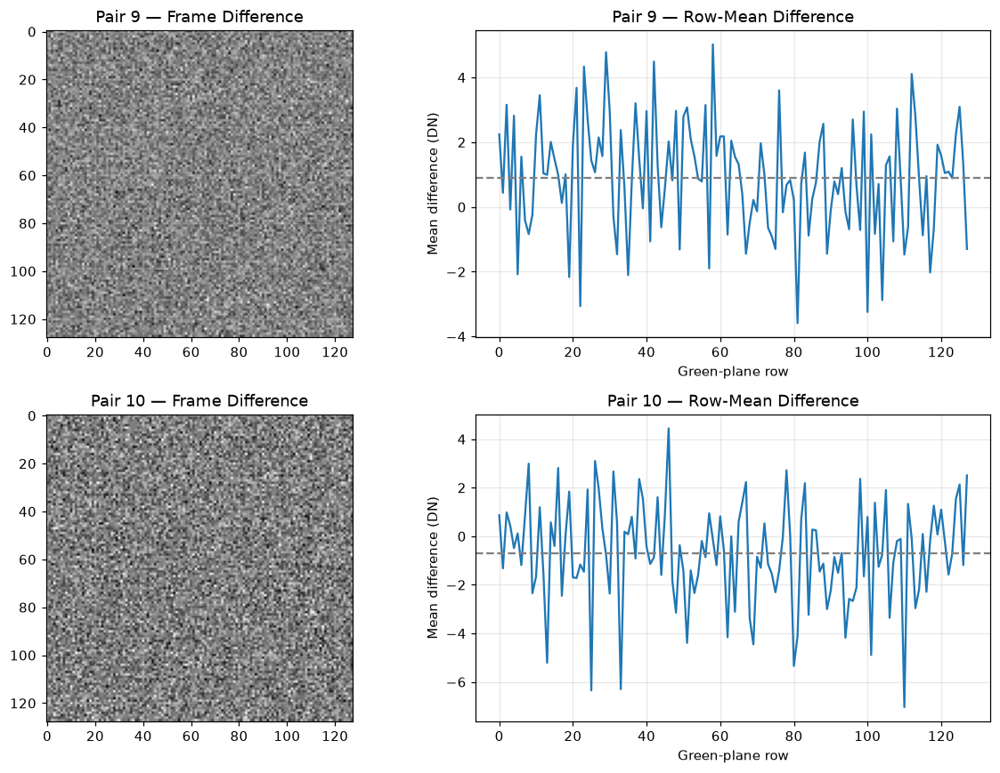

In [46]:

# ==================================================
# STEP 5 — PAIR 10 NOISE DIAGNOSTIC
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

# Preliminary weighted fit using pairs 1–9
# This is a diagnostic, NOT the final selected fit.
x = np.array([p["mean_dn"] for p in ptc_results])
y = np.array([p["variance_dn2"] for p in ptc_results])

N = ptc_results[0]["pixels"]
sigma_y = y * np.sqrt(2 / (N - 1))

fit_coeff, fit_cov = np.polyfit(
    x[:9], y[:9],
    deg=1,
    w=1 / sigma_y[:9],
    cov="unscaled"
)

K_test, c_test = fit_coeff

prediction_10 = K_test * x[9] + c_test

print("=== PRELIMINARY PTC CHECK ===")
print(f"Pairs 1-9 weighted slope: {K_test:.5f} DN/e-")
print(f"Pairs 1-9 intercept: {c_test:+.3f} DN²")
print(f"Pair 10 predicted variance: {prediction_10:.2f} DN²")
print(f"Pair 10 observed variance: {y[9]:.2f} DN²")
print(
    f"Pair 10 excess variance: "
    f"{100*(y[9]/prediction_10-1):+.2f}%"
)

# Reinspect pairs 9 and 10
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for row, pair_num in enumerate([9, 10]):

    exposure = sorted(flat_groups)[pair_num - 1]
    files = sorted(flat_groups[exposure])

    green_A, _ = load_green_raw(files[0])
    green_B, _ = load_green_raw(files[1])

    A = extract_center_patch(green_A, PATCH_SIZE)
    B = extract_center_patch(green_B, PATCH_SIZE)

    diff = A - B

    print(f"\n=== PAIR {pair_num} ===")
    print("Files:", files[0].name, files[1].name)
    print(f"Exposure: {exposure:.6f} s")
    print(f"Frame A mean: {A.mean():.3f} DN")
    print(f"Frame B mean: {B.mean():.3f} DN")
    print(f"Mean difference: {diff.mean():+.3f} DN")
    print(f"Difference SD: {diff.std(ddof=1):.3f} DN")
    print(
        f"Row-mean SD: "
        f"{diff.mean(axis=1).std(ddof=1):.3f} DN"
    )

    axes[row, 0].imshow(
        diff, cmap="gray",
        vmin=-70, vmax=70
    )
    axes[row, 0].set_title(
        f"Pair {pair_num} — Frame Difference"
    )

    axes[row, 1].plot(diff.mean(axis=1))
    axes[row, 1].axhline(
        diff.mean(), color="gray", linestyle="--"
    )
    axes[row, 1].set_title(
        f"Pair {pair_num} — Row-Mean Difference"
    )
    axes[row, 1].set_xlabel("Green-plane row")
    axes[row, 1].set_ylabel("Mean difference (DN)")
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


### 3.10 Fit conversion gain using exposure pairs 1–9

In [47]:

# ==================================================
# STEP 7 — WEIGHTED PHOTON-TRANSFER FITS
# ==================================================

import numpy as np

# Measurements from Step 3
x = np.array([p["mean_dn"] for p in ptc_results])
y = np.array([p["variance_dn2"] for p in ptc_results])

# Number of pixels in each central patch
N = ptc_results[0]["pixels"]

# Estimated uncertainty in temporal variance
sigma_y = y * np.sqrt(2 / (N - 1))

def weighted_ptc_fit(x_data, y_data, sigma_data):
    params, covariance = np.polyfit(
        x_data,
        y_data,
        deg=1,
        w=1 / sigma_data,
        cov="unscaled"
    )

    uncertainty = np.sqrt(np.diag(covariance))

    predicted = np.polyval(params, x_data)

    chi2 = np.sum(
        ((y_data - predicted) / sigma_data)**2
    )

    degrees_of_freedom = len(x_data) - 2
    reduced_chi2 = chi2 / degrees_of_freedom

    return {
        "params": params,
        "uncertainty": uncertainty,
        "reduced_chi2": reduced_chi2
    }

# Baseline fit: exposure pairs 1–9
fit_9 = weighted_ptc_fit(
    x[:9], y[:9], sigma_y[:9]
)

# Comparison fit: all 10 exposure pairs
fit_all = weighted_ptc_fit(
    x, y, sigma_y
)

print("=== WEIGHTED PTC FITS ===")

for label, fit in [
    ("Pairs 1–9", fit_9),
    ("All 10 pairs", fit_all)
]:
    K, intercept = fit["params"]
    u_K, u_intercept = fit["uncertainty"]

    print(f"\n{label}")
    print(f"Gain: {K:.5f} ± {u_K:.5f} DN/e-")
    print(
        f"Intercept: {intercept:+.4f} "
        f"± {u_intercept:.4f} DN²"
    )
    print(
        f"Reduced chi-square: "
        f"{fit['reduced_chi2']:.3f}"
    )


=== WEIGHTED PTC FITS ===

Pairs 1–9
Gain: 0.24371 ± 0.00191 DN/e-
Intercept: +0.3527 ± 0.4475 DN²
Reduced chi-square: 5.428

All 10 pairs
Gain: 0.25626 ± 0.00174 DN/e-
Intercept: -2.0397 ± 0.4219 DN²
Reduced chi-square: 36.947


### 3.11 Compare weighted and unweighted fits

=== PROJECT 1 PTC FIT COMPARISON ===

Unweighted, pairs 1-9
  Gain: 0.25055 +/- 0.00320 DN/e-
  Intercept: -1.6485 +/- 1.3240 DN^2

Unweighted, all 10
  Gain: 0.29239 +/- 0.01537 DN/e-
  Intercept: -14.0586 +/- 7.6765 DN^2

Weighted, pairs 1-9
  Gain: 0.24371 +/- 0.00191 DN/e-
  Intercept: +0.3527 +/- 0.4475 DN^2
  Reduced chi-square: 5.428

Weighted, all 10
  Gain: 0.25626 +/- 0.00174 DN/e-
  Intercept: -2.0397 +/- 0.4219 DN^2
  Reduced chi-square: 36.947

=== WEIGHTING SENSITIVITY ===
Pairs 1-9 slope difference: +2.81%
All 10 slope difference: +14.10%


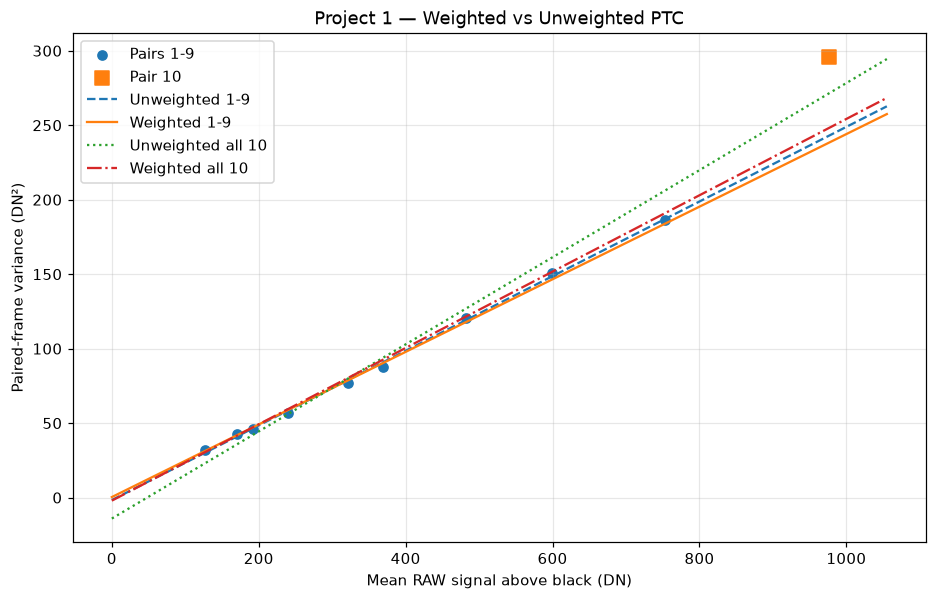

In [48]:

# ==================================================
# STEP 8 — WEIGHTED VS UNWEIGHTED PTC
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

# New flat-field measurements
x = np.array([p["mean_dn"] for p in ptc_results])
y = np.array([p["variance_dn2"] for p in ptc_results])

# Professor's unweighted linear regression method
unweighted_9, cov_u9 = np.polyfit(
    x[:9], y[:9], 1, cov=True
)

unweighted_10, cov_u10 = np.polyfit(
    x, y, 1, cov=True
)

# Previously calculated weighted regressions
weighted_9 = fit_9["params"]
weighted_10 = fit_all["params"]

print("=== PROJECT 1 PTC FIT COMPARISON ===")

for label, params, cov in [
    ("Unweighted, pairs 1-9", unweighted_9, cov_u9),
    ("Unweighted, all 10", unweighted_10, cov_u10)
]:
    K, c = params
    u_K, u_c = np.sqrt(np.diag(cov))

    print(f"\n{label}")
    print(f"  Gain: {K:.5f} +/- {u_K:.5f} DN/e-")
    print(f"  Intercept: {c:+.4f} +/- {u_c:.4f} DN^2")

for label, fit in [
    ("Weighted, pairs 1-9", fit_9),
    ("Weighted, all 10", fit_all)
]:
    K, c = fit["params"]
    u_K, u_c = fit["uncertainty"]

    print(f"\n{label}")
    print(f"  Gain: {K:.5f} +/- {u_K:.5f} DN/e-")
    print(f"  Intercept: {c:+.4f} +/- {u_c:.4f} DN^2")
    print(f"  Reduced chi-square: {fit['reduced_chi2']:.3f}")

print("\n=== WEIGHTING SENSITIVITY ===")
print(
    "Pairs 1-9 slope difference:",
    f"{100*(unweighted_9[0]/weighted_9[0]-1):+.2f}%"
)
print(
    "All 10 slope difference:",
    f"{100*(unweighted_10[0]/weighted_10[0]-1):+.2f}%"
)

# Plot all four models
xx = np.linspace(0, x.max()*1.08, 300)

plt.figure(figsize=(10, 6))

plt.scatter(x[:9], y[:9], label="Pairs 1-9")
plt.scatter(
    x[9], y[9], marker="s", s=75,
    label="Pair 10"
)

plt.plot(
    xx, np.polyval(unweighted_9, xx),
    "--", label="Unweighted 1-9"
)
plt.plot(
    xx, np.polyval(weighted_9, xx),
    "-", label="Weighted 1-9"
)
plt.plot(
    xx, np.polyval(unweighted_10, xx),
    ":", label="Unweighted all 10"
)
plt.plot(
    xx, np.polyval(weighted_10, xx),
    "-.", label="Weighted all 10"
)

plt.xlabel("Mean RAW signal above black (DN)")
plt.ylabel("Paired-frame variance (DN²)")
plt.title("Project 1 — Weighted vs Unweighted PTC")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 3.12 Measure read noise from dark frames

In [49]:

# ==================================================
# PART 3 — REQUIREMENT 3: READ NOISE
# ==================================================

from pathlib import Path
import numpy as np

# Existing lens-capped dark frames
DARK_DIR = Path(str(DATA_ROOT / 'Part1_RAW_Dark'))

assert DARK_DIR.exists(), "Dark-frame folder not found"

dark_files = sorted(DARK_DIR.glob("*.DNG"))

# Select shortest-exposure dark frames by filename
short_files = [
    f for f in dark_files
    if f.name.startswith("1_8197_Dark")
]

assert len(short_files) == 5, (
    f"Expected 5 shortest dark frames, found {len(short_files)}"
)

dark_patches = []

for file in short_files:
    green, meta = load_green_raw(file)
    patch = extract_center_patch(green, PATCH_SIZE)
    dark_patches.append(patch)

stack = np.stack(dark_patches, axis=0)

# Temporal variance at each pixel
variance_map = np.var(stack, axis=0, ddof=1)

read_var_dn2 = variance_map.mean()
read_noise_dn = np.sqrt(read_var_dn2)

# Current provisional conversion gain
K = fit_9["params"][0]

read_noise_e = read_noise_dn / K

print("=== PART 3 — READ NOISE ===")
print("Dark frames:", len(short_files))
print(f"Read-noise variance: {read_var_dn2:.5f} DN²")
print(f"Read noise: {read_noise_dn:.5f} DN RMS")
print(f"Conversion gain: {K:.5f} DN/e-")
print(f"Read noise: {read_noise_e:.4f} e- RMS")

print("\n=== PTC INTERCEPT CROSS-CHECK ===")
print(f"PTC intercept: {fit_9['params'][1]:+.4f} DN²")
print(f"Dark-frame variance: {read_var_dn2:.4f} DN²")


=== PART 3 — READ NOISE ===
Dark frames: 5
Read-noise variance: 2.56315 DN²
Read noise: 1.60098 DN RMS
Conversion gain: 0.24371 DN/e-
Read noise: 6.5692 e- RMS

=== PTC INTERCEPT CROSS-CHECK ===
PTC intercept: +0.3527 DN²
Dark-frame variance: 2.5631 DN²


### 3.13 Estimate read-noise uncertainty

In [50]:

# ==================================================
# PART 3 — READ-NOISE UNCERTAINTY
# ==================================================

import numpy as np

# Existing stack: 5 dark frames x 128 x 128
assert stack.shape == (5, 128, 128)

K = fit_9["params"][0]
u_K = fit_9["uncertainty"][0]

# Temporal variance map
variance_map = np.var(stack, axis=0, ddof=1)

# Leave-one-frame-out stability
loo = []

for i in range(len(stack)):
    reduced_stack = np.delete(stack, i, axis=0)
    v = np.var(reduced_stack, axis=0, ddof=1)
    loo.append(np.sqrt(v.mean()))

print("=== READ-NOISE STABILITY ===")
for i, value in enumerate(loo, 1):
    print(f"Exclude frame {i}: {value:.5f} DN RMS")

# Spatial block bootstrap
block_size = 16
block_means = []

for row in range(0, 128, block_size):
    for col in range(0, 128, block_size):
        block_means.append(
            variance_map[
                row:row+block_size,
                col:col+block_size
            ].mean()
        )

block_means = np.asarray(block_means)

rng = np.random.default_rng(513)
boot_noise = np.empty(5000)

for i in range(5000):
    sampled = rng.choice(
        block_means,
        size=len(block_means),
        replace=True
    )
    boot_noise[i] = np.sqrt(sampled.mean())

u_read_dn = boot_noise.std(ddof=1)

# Propagate gain uncertainty
read_noise_e = read_noise_dn / K

u_read_e = np.sqrt(
    (u_read_dn / K)**2
    +
    (read_noise_dn * u_K / K**2)**2
)

print("\n=== READ-NOISE RESULT ===")
print(f"Read noise: {read_noise_dn:.5f} ± {u_read_dn:.5f} DN RMS")
print(f"Gain: {K:.5f} ± {u_K:.5f} DN/e-")
print(f"Read noise: {read_noise_e:.4f} ± {u_read_e:.4f} e- RMS")

print("\nUncertainty note:")
print("Conditional spatial bootstrap + gain propagation.")
print("Temporal and gain-model systematics are not fully included.")


=== READ-NOISE STABILITY ===
Exclude frame 1: 1.60211 DN RMS
Exclude frame 2: 1.60431 DN RMS
Exclude frame 3: 1.59478 DN RMS
Exclude frame 4: 1.60171 DN RMS
Exclude frame 5: 1.60199 DN RMS

=== READ-NOISE RESULT ===
Read noise: 1.60098 ± 0.00482 DN RMS
Gain: 0.24371 ± 0.00191 DN/e-
Read noise: 6.5692 ± 0.0552 e- RMS

Uncertainty note:
Conditional spatial bootstrap + gain propagation.
Temporal and gain-model systematics are not fully included.


### 3.14 Plot the SNR model and noise crossover

=== NEW PROJECT 1 SNR ANALYSIS ===
Gain: 0.24371 DN/e-
Read noise: 6.5692 e- RMS
Knee: 43.15 ± 0.72 e-
Knee above black: 10.52 DN
Lowest measured signal: 523.1 e-

=== MEASURED SNR ===
Pair    Signal(e-)        SNR
   1        523.13     22.464
   2        700.72     26.194
   3        785.95     28.163
   4        986.22     31.807
   5       1320.64     36.636
   6       1513.25     39.328
   7       1980.43     43.977
   8       2460.92     48.821
   9       3088.20     55.134
  10       4008.68     56.772


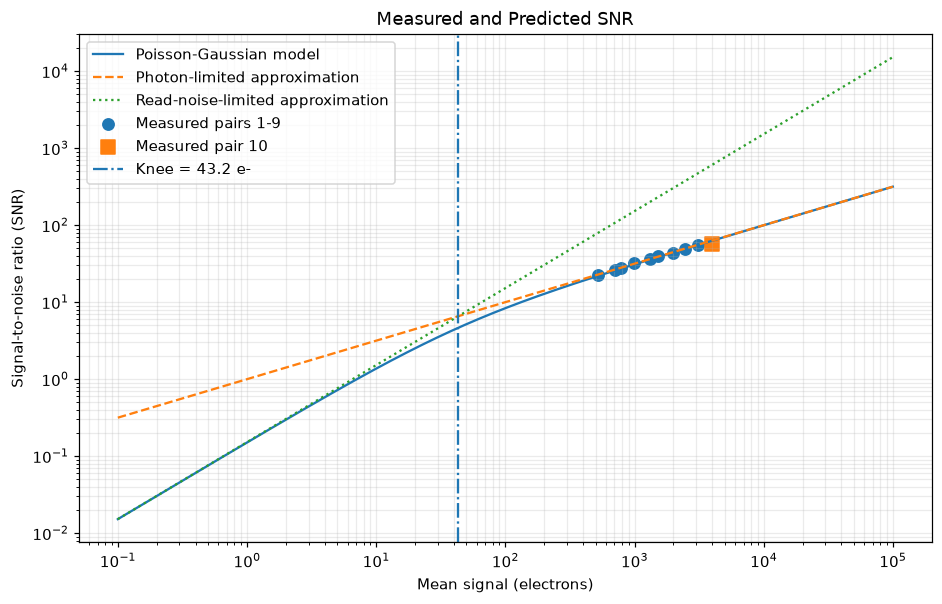

In [51]:

# ==================================================
# PART 3 — SNR CURVE AND NOISE-REGIME KNEE
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

# Use previously measured values from the new dataset
K = fit_9["params"][0]
read_e = read_noise_e
u_read = u_read_e

signals_dn = np.array([
    p["mean_dn"] for p in ptc_results
])

variances_dn2 = np.array([
    p["variance_dn2"] for p in ptc_results
])

# Convert mean signal to electrons
signals_e = signals_dn / K

# Direct measured SNR using difference-of-pairs variance
snr_measured = signals_dn / np.sqrt(variances_dn2)

# Model prediction
signal_axis = np.logspace(-1, 5, 600)

snr_model = signal_axis / np.sqrt(
    signal_axis + read_e**2
)

snr_photon = np.sqrt(signal_axis)
snr_read = signal_axis / read_e

# Noise-regime transition
knee_e = read_e**2
knee_dn = K * knee_e

# Conditional uncertainty; assumes independent inputs
u_knee_e = 2 * read_e * u_read

print("=== NEW PROJECT 1 SNR ANALYSIS ===")
print(f"Gain: {K:.5f} DN/e-")
print(f"Read noise: {read_e:.4f} e- RMS")
print(f"Knee: {knee_e:.2f} ± {u_knee_e:.2f} e-")
print(f"Knee above black: {knee_dn:.2f} DN")
print(f"Lowest measured signal: {signals_e.min():.1f} e-")

print("\n=== MEASURED SNR ===")
print(f"{'Pair':>4} {'Signal(e-)':>13} {'SNR':>10}")

for i, (signal, snr) in enumerate(
    zip(signals_e, snr_measured), start=1
):
    print(f"{i:>4} {signal:>13.2f} {snr:>10.3f}")

plt.figure(figsize=(10, 6))

plt.loglog(
    signal_axis, snr_model,
    label="Poisson-Gaussian model"
)

plt.loglog(
    signal_axis, snr_photon, "--",
    label="Photon-limited approximation"
)

plt.loglog(
    signal_axis, snr_read, ":",
    label="Read-noise-limited approximation"
)

plt.scatter(
    signals_e[:9], snr_measured[:9],
    s=55, label="Measured pairs 1-9"
)

plt.scatter(
    signals_e[9], snr_measured[9],
    marker="s", s=75,
    label="Measured pair 10"
)

plt.axvline(
    knee_e, linestyle="-.",
    label=f"Knee = {knee_e:.1f} e-"
)

plt.xlabel("Mean signal (electrons)")
plt.ylabel("Signal-to-noise ratio (SNR)")
plt.title("Measured and Predicted SNR")
plt.legend()
plt.grid(True, which="both", alpha=0.25)
plt.show()


### 3.15 Measure lens-covered dark-current data

In [52]:

# ==================================================
# PART 3 — DARK CURRENT MEASUREMENTS
# ==================================================

from pathlib import Path
from collections import defaultdict
import numpy as np

DARK_DIR = Path(str(DATA_ROOT / 'Part1_RAW_Dark'))

dark_files = sorted(
    f for f in DARK_DIR.rglob("*")
    if f.is_file() and f.suffix.lower() == ".dng"
)

assert len(dark_files) == 20, (
    f"Expected 20 dark frames, found {len(dark_files)}"
)

dark_groups = defaultdict(list)

for file in dark_files:
    exposure, iso, lens = get_capture_metadata(file)

    assert iso == EXPECTED_ISO
    assert lens == reference_lens

    dark_groups[exposure].append(file)

assert len(dark_groups) == 4
assert all(len(files) == 5 for files in dark_groups.values())

dark_results = []

for exposure, files in sorted(dark_groups.items()):
    frame_means = []

    for file in sorted(files):
        green, meta = load_green_raw(file)

        assert np.array_equal(
            meta["pattern"], reference_meta["pattern"]
        )
        assert meta["black"] == reference_meta["black"]

        patch = extract_center_patch(green, PATCH_SIZE)
        frame_means.append(patch.mean() - meta["black"])

    frame_means = np.asarray(frame_means)

    dark_results.append({
        "exposure_s": exposure,
        "mean_dn": frame_means.mean(),
        "sd_dn": frame_means.std(ddof=1),
        "sem_dn": frame_means.std(ddof=1) / np.sqrt(5)
    })

print("=== NEW PROJECT 1 DARK-CURRENT DATA ===")
print("Dark frames verified:", len(dark_files))

print(f"{'Exposure(s)':>12} {'Mean(DN)':>12} "
      f"{'SD(DN)':>12} {'SEM(DN)':>12}")

for r in dark_results:
    print(
        f"{r['exposure_s']:>12.6f} "
        f"{r['mean_dn']:>+12.5f} "
        f"{r['sd_dn']:>12.5f} "
        f"{r['sem_dn']:>12.5f}"
    )

print("\nPASS: Dark-frame groups verified and measured.")


=== NEW PROJECT 1 DARK-CURRENT DATA ===
Dark frames verified: 20
 Exposure(s)     Mean(DN)       SD(DN)      SEM(DN)
    0.000122     -0.41604      0.01329      0.00595
    0.005000     -0.41163      0.02557      0.01143
    0.100000     -0.44464      0.00754      0.00337
    1.000000     -0.26090      0.03257      0.01456

PASS: Dark-frame groups verified and measured.


### 3.16 Fit dark current and test sensitivity

=== NEW PROJECT 1 DARK CURRENT ===
All four groups: +0.6762 ± 0.1332 e-/s
Excluding longest group: -1.2878 e-/s
95% model-conditional interval: [+0.1033, +1.2490] e-/s

Interpretation:
Compare slope sign and magnitude before
deciding whether dark current is resolved.


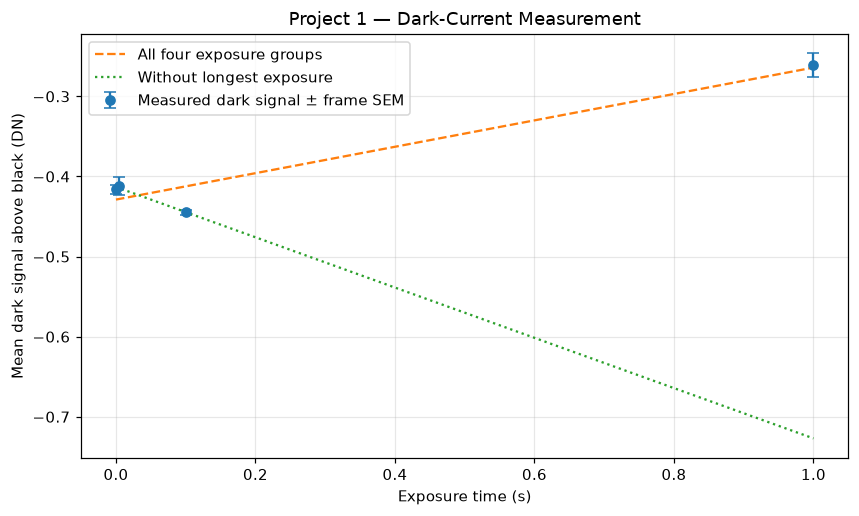

In [53]:

# ==================================================
# PART 3 — DARK-CURRENT FIT
# ==================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

times = np.array([r["exposure_s"] for r in dark_results])
means = np.array([r["mean_dn"] for r in dark_results])
sems = np.array([r["sem_dn"] for r in dark_results])

K = fit_9["params"][0]
u_K = fit_9["uncertainty"][0]

# Fit all four exposure groups
params, covariance = np.polyfit(times, means, 1, cov=True)
slope, offset = params
u_slope = np.sqrt(covariance[0, 0])

dark_current = slope / K

u_dark_current = np.sqrt(
    (u_slope / K)**2 +
    (slope * u_K / K**2)**2
)

# Sensitivity: remove the longest exposure group
short_params = np.polyfit(times[:-1], means[:-1], 1)
short_slope = short_params[0]

# Model-conditional two-sided 95% interval
dof = len(times) - 2
critical = t.ppf(0.975, dof)

ci_low = (slope - critical * u_slope) / K
ci_high = (slope + critical * u_slope) / K

print("=== NEW PROJECT 1 DARK CURRENT ===")
print(f"All four groups: {dark_current:+.4f} "
      f"± {u_dark_current:.4f} e-/s")

print(f"Excluding longest group: "
      f"{short_slope/K:+.4f} e-/s")

print(f"95% model-conditional interval: "
      f"[{ci_low:+.4f}, {ci_high:+.4f}] e-/s")

print("\nInterpretation:")
print("Compare slope sign and magnitude before")
print("deciding whether dark current is resolved.")

x_line = np.linspace(0, times.max(), 200)

plt.figure(figsize=(9, 5))

plt.errorbar(
    times, means, yerr=sems,
    fmt="o", capsize=4,
    label="Measured dark signal ± frame SEM"
)

plt.plot(
    x_line, np.polyval(params, x_line),
    "--", label="All four exposure groups"
)

plt.plot(
    x_line, np.polyval(short_params, x_line),
    ":", label="Without longest exposure"
)

plt.xlabel("Exposure time (s)")
plt.ylabel("Mean dark signal above black (DN)")
plt.title("Project 1 — Dark-Current Measurement")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 3.17 Compare single-frame and paired-frame variance

=== SINGLE VS PAIRED FRAME VARIANCE ===
Pair   Mean(DN)   Single(DN²)   Paired(DN²)
   1     127.49         32.89         32.21
   2     170.77         43.65         42.50
   3     191.54         47.45         46.26
   4     240.35         59.18         57.10
   5     321.85         80.92         77.18
   6     368.79         92.37         87.94
   7     482.65        128.18        120.45
   8     599.75        163.18        150.91
   9     752.62        213.57        186.35
  10     976.95        328.12        296.12

=== APPARENT GAIN COMPARISON ===
Single-frame slope: 0.28808 DN/e-
Paired-frame slope: 0.25055 DN/e-
Relative difference: +14.98%


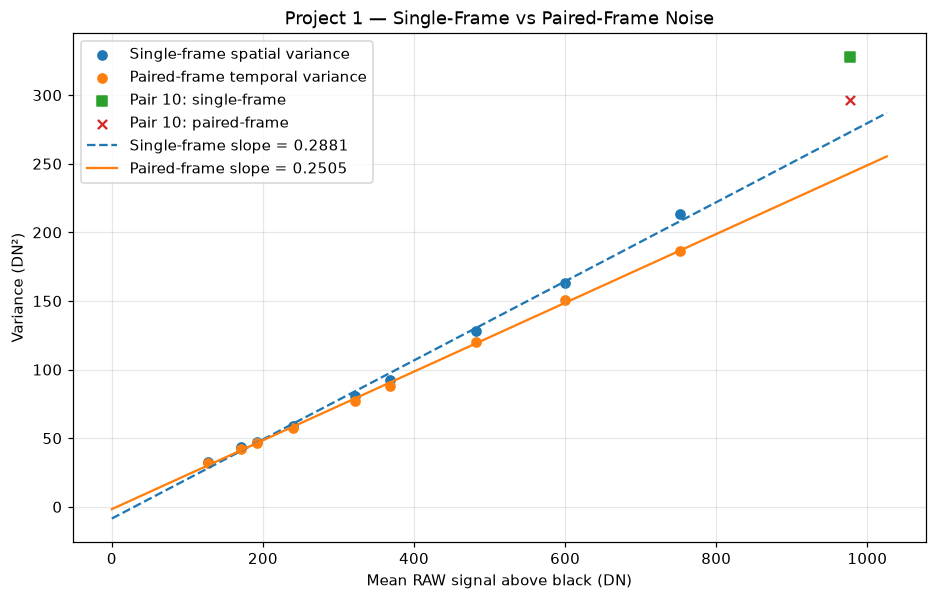

In [54]:

# ==================================================
# PART 3 — SINGLE VS PAIRED FRAME COMPARISON
# ==================================================

import numpy as np
import matplotlib.pyplot as plt

single_variances = []
paired_variances = []
mean_signals = []

for exposure, files in sorted(flat_groups.items()):

    files = sorted(files)
    green_A, meta_A = load_green_raw(files[0])
    green_B, meta_B = load_green_raw(files[1])

    A = extract_center_patch(green_A, PATCH_SIZE)
    B = extract_center_patch(green_B, PATCH_SIZE)

    mean_signal = (
        (A.mean() + B.mean()) / 2 - meta_A["black"]
    )

    # Spatial variance of individual frames
    single_var = (
        np.var(A, ddof=1) + np.var(B, ddof=1)
    ) / 2

    # Temporal variance from paired differences
    paired_var = np.var(A - B, ddof=1) / 2

    mean_signals.append(mean_signal)
    single_variances.append(single_var)
    paired_variances.append(paired_var)

mean_signals = np.asarray(mean_signals)
single_variances = np.asarray(single_variances)
paired_variances = np.asarray(paired_variances)

print("=== SINGLE VS PAIRED FRAME VARIANCE ===")
print(
    f"{'Pair':>4} {'Mean(DN)':>10} "
    f"{'Single(DN²)':>13} {'Paired(DN²)':>13}"
)

for i in range(len(mean_signals)):
    print(
        f"{i+1:>4} "
        f"{mean_signals[i]:>10.2f} "
        f"{single_variances[i]:>13.2f} "
        f"{paired_variances[i]:>13.2f}"
    )

# Professor's unweighted fitting method,
# same first nine pairs for a fair comparison.
single_fit = np.polyfit(
    mean_signals[:9], single_variances[:9], 1
)

paired_fit = np.polyfit(
    mean_signals[:9], paired_variances[:9], 1
)

K_single = single_fit[0]
K_paired = paired_fit[0]

print("\n=== APPARENT GAIN COMPARISON ===")
print(f"Single-frame slope: {K_single:.5f} DN/e-")
print(f"Paired-frame slope: {K_paired:.5f} DN/e-")
print(
    f"Relative difference: "
    f"{100*(K_single/K_paired-1):+.2f}%"
)

# Visualization
xline = np.linspace(0, mean_signals.max()*1.05, 300)

plt.figure(figsize=(10, 6))

plt.scatter(
    mean_signals[:9], single_variances[:9],
    label="Single-frame spatial variance"
)
plt.scatter(
    mean_signals[:9], paired_variances[:9],
    label="Paired-frame temporal variance"
)

plt.scatter(
    mean_signals[9], single_variances[9],
    marker="s", label="Pair 10: single-frame"
)
plt.scatter(
    mean_signals[9], paired_variances[9],
    marker="x", label="Pair 10: paired-frame"
)

plt.plot(
    xline, np.polyval(single_fit, xline),
    "--", label=f"Single-frame slope = {K_single:.4f}"
)
plt.plot(
    xline, np.polyval(paired_fit, xline),
    "-", label=f"Paired-frame slope = {K_paired:.4f}"
)

plt.xlabel("Mean RAW signal above black (DN)")
plt.ylabel("Variance (DN²)")
plt.title("Project 1 — Single-Frame vs Paired-Frame Noise")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### 3.18 Compare measurements with the DNG NoiseProfile

In [55]:

# ==================================================
# PART 3 — MANUFACTURER NOISEPROFILE
# ==================================================

import numpy as np
import tifffile

vendor_file = flat_files[0]
_, vendor_meta = load_green_raw(vendor_file)

R = vendor_meta["white"] - vendor_meta["black"]
profile = None

with tifffile.TiffFile(str(vendor_file)) as tif:
    for page_index, page in enumerate(tif.pages):
        tag = page.tags.get("NoiseProfile")

        if tag is None:
            tag = page.tags.get(51041)

        if tag is not None:
            profile = np.asarray(
                tag.value, dtype=float
            ).ravel()
            print("NoiseProfile found in IFD", page_index)
            break

print("=== DNG NOISEPROFILE ===")
print("File:", vendor_file.name)
print("Normalization range:", R, "DN")

if profile is None:
    print("NoiseProfile not found in inspected IFDs.")
else:
    print("Raw profile:", profile)

    assert len(profile) >= 2
    S, O = profile[:2]

    assert S > 0 and O >= 0

    K_vendor = S * R
    read_vendor_dn = np.sqrt(O) * R
    read_vendor_e = np.sqrt(O) / S
    intercept_vendor = O * R**2

    K_measured = fit_9["params"][0]
    intercept_measured = fit_9["params"][1]

    print("\n=== MANUFACTURER MODEL ===")
    print(f"Scale S: {S:.9g}")
    print(f"Offset O: {O:.9g}")
    print(f"Gain: {K_vendor:.5f} DN/e-")
    print(f"Read noise: {read_vendor_dn:.5f} DN RMS")
    print(f"Read noise: {read_vendor_e:.4f} e- RMS")
    print(f"Variance intercept: {intercept_vendor:.4f} DN²")

    print("\n=== OUR MEASUREMENTS ===")
    print(f"Weighted PTC gain: {K_measured:.5f} DN/e-")
    print(f"PTC fitted intercept: {intercept_measured:+.4f} DN²")
    print(f"Dark-frame read noise: {read_noise_dn:.5f} DN RMS")
    print(f"Dark-frame read noise: {read_noise_e:.4f} e- RMS")

    print("\n=== RELATIVE DIFFERENCES ===")
    print(
        "Measured gain vs vendor:",
        f"{100*(K_measured/K_vendor - 1):+.2f}%"
    )
    print(
        "Measured read noise vs vendor:",
        f"{100*(read_noise_e/read_vendor_e - 1):+.2f}%"
    )


NoiseProfile found in IFD 0
=== DNG NOISEPROFILE ===
File: 1_10 (1).DNG
Normalization range: 3567.0 DN
Raw profile: [0.0001 0.    ]

=== MANUFACTURER MODEL ===
Scale S: 0.000130931
Offset O: 3.98708e-07
Gain: 0.46703 DN/e-
Read noise: 2.25232 DN RMS
Read noise: 4.8226 e- RMS
Variance intercept: 5.0730 DN²

=== OUR MEASUREMENTS ===
Weighted PTC gain: 0.24371 DN/e-
PTC fitted intercept: +0.3527 DN²
Dark-frame read noise: 1.60098 DN RMS
Dark-frame read noise: 6.5692 e- RMS

=== RELATIVE DIFFERENCES ===
Measured gain vs vendor: -47.82%
Measured read noise vs vendor: +36.22%


### 3.19 Check noise-fit and dark-frame results

In [56]:
# Check that the fit and dark-frame noise estimates are physically meaningful.
assert fit_9['params'][0] > 0, "Conversion gain must be positive."
assert read_noise_dn > 0 and read_noise_e > 0
assert np.isfinite(fit_9['reduced_chi2'])
print("PASS — positive gain and read-noise measurements")
print(f"Gain: {fit_9['params'][0]:.5f} DN/e-")
print(f"Read noise: {read_noise_e:.4f} e- RMS")

project_noise_gain = float(fit_9["params"][0])
project_read_noise_e = float(read_noise_e)


PASS — positive gain and read-noise measurements
Gain: 0.24371 DN/e-
Read noise: 6.5692 e- RMS


## 4. Dynamic range — saturation check

I used the green-channel saturation value that I saw in the decoded Bayer mosaic. I also checked the DNG white-level metadata because the two interpretations were different. I report the dynamic range using one RMS read noise as the low-signal limit, and I keep the saturation uncertainty in the report.

### 4.1 Inspect the saturated green-channel RAW data

In [57]:

# ==================================================
# PART 4 — SATURATION VERIFICATION
# ==================================================

from pathlib import Path
import numpy as np

SAT_FILE = Path(
    str(DATA_ROOT / 'Saturation' / '1_1.DNG')
)

assert SAT_FILE.exists(), (
    f"Saturated DNG not found: {SAT_FILE}"
)

# Reuse our verified RAW extraction functions
green_sat, sat_meta = load_green_raw(SAT_FILE)

sat_patch = extract_center_patch(
    green_sat, PATCH_SIZE
)

values, counts = np.unique(
    sat_patch, return_counts=True
)

mode_index = np.argmax(counts)

plateau_dn = float(values[mode_index])
plateau_fraction = counts[mode_index] / sat_patch.size

black_dn = sat_meta["black"]
white_dn = sat_meta["white"]

signal_ceiling_dn = plateau_dn - black_dn

print("=== PART 4 — SATURATION VERIFICATION ===")
print("File:", SAT_FILE.name)
print(f"Black level: {black_dn:.1f} DN")
print(f"DNG WhiteLevel: {white_dn:.1f} DN")
print(f"Observed green plateau: {plateau_dn:.1f} DN")
print(f"Unique patch values: {len(values)}")
print(f"Fraction at plateau: {100*plateau_fraction:.2f}%")
print(f"Signal above black: {signal_ceiling_dn:.1f} DN")

assert len(values) == 1, (
    "Patch is not uniformly saturated; inspect it."
)

assert signal_ceiling_dn > 0

print("\nPASS: Saturation evidence verified.")


=== PART 4 — SATURATION VERIFICATION ===
File: 1_1.DNG
Black level: 528.0 DN
DNG WhiteLevel: 4095.0 DN
Observed green plateau: 3567.0 DN
Unique patch values: 1
Fraction at plateau: 100.00%
Signal above black: 3039.0 DN

PASS: Saturation evidence verified.


### 4.2 Calculate conditional dynamic range

In [58]:

# ==================================================
# PART 4 — EFFECTIVE DYNAMIC RANGE
# ==================================================

import numpy as np

# Measured values from Part 3
K = fit_9["params"][0]
u_K = fit_9["uncertainty"][0]

read_dn = read_noise_dn
u_read_dn = 0.00482  # Earlier spatial bootstrap result

# Effective full-well equivalent
full_well_e = signal_ceiling_dn / K

# Conditional gain-only uncertainty
u_full_well_e = signal_ceiling_dn * u_K / K**2

# One-RMS-read-noise dynamic-range criterion
dr_stops = np.log2(signal_ceiling_dn / read_dn)

# Conditional read-noise-only uncertainty
u_dr_stops = u_read_dn / (
    read_dn * np.log(2)
)

# Nominal DNG WhiteLevel alternative
nominal_ceiling_dn = white_dn - black_dn

dr_nominal = np.log2(
    nominal_ceiling_dn / read_dn
)

print("=== PROJECT 1 — PART 4 DYNAMIC RANGE ===")
print(f"Observed signal ceiling: {signal_ceiling_dn:.1f} DN")

print(
    f"Effective full-well equivalent: "
    f"{full_well_e:.1f} ± {u_full_well_e:.1f} e-"
)

print(
    f"Effective DR: "
    f"{dr_stops:.4f} ± {u_dr_stops:.4f} stops"
)

print(
    f"Nominal-white-level comparison: "
    f"{dr_nominal:.4f} stops"
)

print("\nCriterion: 1 RMS temporal read-noise floor.")
print("Uncertainty: conditional; saturation systematic excluded.")


=== PROJECT 1 — PART 4 DYNAMIC RANGE ===
Observed signal ceiling: 3039.0 DN
Effective full-well equivalent: 12469.8 ± 97.7 e-
Effective DR: 10.8904 ± 0.0043 stops
Nominal-white-level comparison: 11.1215 stops

Criterion: 1 RMS temporal read-noise floor.
Uncertainty: conditional; saturation systematic excluded.


### 4.3 Check decoded RAW values and black level

In [59]:

import numpy as np
import rawpy

print("=== RAW SATURATION AND BLACK-LEVEL VERIFICATION ===")

with rawpy.imread(str(SAT_FILE)) as raw:
    original = raw.raw_image_visible.copy()

    pattern = raw.raw_pattern.copy()
    r, c = reference_meta["green_position"]

    green_direct = original[r::2, c::2].astype(np.float64)

    black = float(
        raw.black_level_per_channel[int(pattern[r, c])]
    )
    white = float(raw.white_level)

# Our existing extraction function
green_function, _ = load_green_raw(SAT_FILE)

# Compare the same central region
direct_patch = extract_center_patch(
    green_direct, PATCH_SIZE
)

function_patch = extract_center_patch(
    green_function, PATCH_SIZE
)

print(f"BlackLevel: {black:.0f} DN")
print(f"WhiteLevel: {white:.0f} DN")
print(f"WhiteLevel - BlackLevel: {white-black:.0f} DN")

print("\n--- DIRECT RAW PIXELS ---")
print("Minimum:", direct_patch.min())
print("Maximum:", direct_patch.max())
print("Unique values:", np.unique(direct_patch).size)

print("\n--- OUR EXTRACTION FUNCTION ---")
print("Minimum:", function_patch.min())
print("Maximum:", function_patch.max())

print("\n--- CHECK FOR PROCESSING ---")
print(
    "Function identical to direct RAW:",
    np.array_equal(direct_patch, function_patch)
)

signal_patch = direct_patch - black

print("\n--- BLACK SUBTRACTION ---")
print("Stored RAW plateau:", direct_patch.max(), "DN")
print("After black subtraction:", signal_patch.max(), "DN")

print("\n--- CLIPPING CHECK ---")
print("Full mosaic maximum:", original.max())
print("Fraction of full mosaic above 3567:",
      100*np.mean(original > 3567), "%")
print("Fraction of full mosaic equal to 4095:",
      100*np.mean(original == 4095), "%")

assert np.array_equal(direct_patch, function_patch)

print("\nPASS: Extraction function matches direct RAW pixels.")


=== RAW SATURATION AND BLACK-LEVEL VERIFICATION ===
BlackLevel: 528 DN
WhiteLevel: 4095 DN
WhiteLevel - BlackLevel: 3567 DN

--- DIRECT RAW PIXELS ---
Minimum: 3567.0
Maximum: 3567.0
Unique values: 1

--- OUR EXTRACTION FUNCTION ---
Minimum: 3567.0
Maximum: 3567.0

--- CHECK FOR PROCESSING ---
Function identical to direct RAW: True

--- BLACK SUBTRACTION ---
Stored RAW plateau: 3567.0 DN
After black subtraction: 3039.0 DN

--- CLIPPING CHECK ---
Full mosaic maximum: 3576
Fraction of full mosaic above 3567: 0.40437085327958344 %
Fraction of full mosaic equal to 4095: 0.0 %

PASS: Extraction function matches direct RAW pixels.


### 4.4 Verify the dynamic-range equation

In [60]:
# Check the calculation directly from the measured signal and read-noise floor.
assert signal_ceiling_dn > 0 and read_dn > 0
recomputed_dr = np.log2(signal_ceiling_dn / read_dn)
assert np.isclose(recomputed_dr, dr_stops, atol=1e-10)
print(f"PASS — dynamic range equation: {dr_stops:.4f} stops")
print(f"DNG white-level alternative: {dr_nominal:.4f} stops")

project_dynamic_range = float(dr_stops)


PASS — dynamic range equation: 10.8904 stops
DNG white-level alternative: 11.1215 stops


## 5. Color accuracy — corrected Assignment 4 analysis

I kept the color processing steps together because the later CCM calculations use the earlier patch measurements. After the professor's feedback, I normalized the measured white patch to the reference luminance, used a consistent Lab reference white, and averaged each chart's worst patch error for the final result.

The three-chart results are in-sample fits. The final lighting comparisons use one fixed LED CCM to compare different lighting conditions.

### 5.1 Check ColorChecker captures and clipping

Unique lens IDs found: 1
Lens ID information: {('iPhone 14 Pro back camera 6.86mm f/1.78', 6.86, 24, (4032, 3024))}
Lens_id assertion: PASSED

ISO and exposure consistency: PASSED

Table 1. RAW Capture Settings and Saturation Measurements


,Round,Chart,File,ISO,Exposure,Saturation DN,Clipped fraction
0,1,Chart 1,Round1_1.DNG,400,"(1, 60)",3582 (observed),0.0429%
1,1,Chart 2,Round1_2.DNG,400,"(1, 60)",3582 (observed),0.0326%
2,1,Chart 3,Round1_3.DNG,400,"(1, 60)",3582 (observed),0.0264%
3,1,White sheet,Round1_4.DNG,400,"(1, 60)",3580 (observed),0.1204%
4,2,Chart 1,Round2_1.DNG,400,"(1, 60)",3582 (assumed),0.0000%
5,2,Chart 2,Round2_2.DNG,400,"(1, 60)",3582 (assumed),0.0000%
6,2,Chart 3,Round2_3.DNG,400,"(1, 60)",3582 (assumed),0.0000%
7,2,White sheet,Round2_4.DNG,400,"(1, 60)",3582 (assumed),0.0000%
8,3,Chart 1,Round3_1.DNG,400,"(1, 60)",3582 (assumed),0.0000%
9,3,Chart 2,Round3_2.DNG,400,"(1, 60)",3582 (assumed),0.0000%


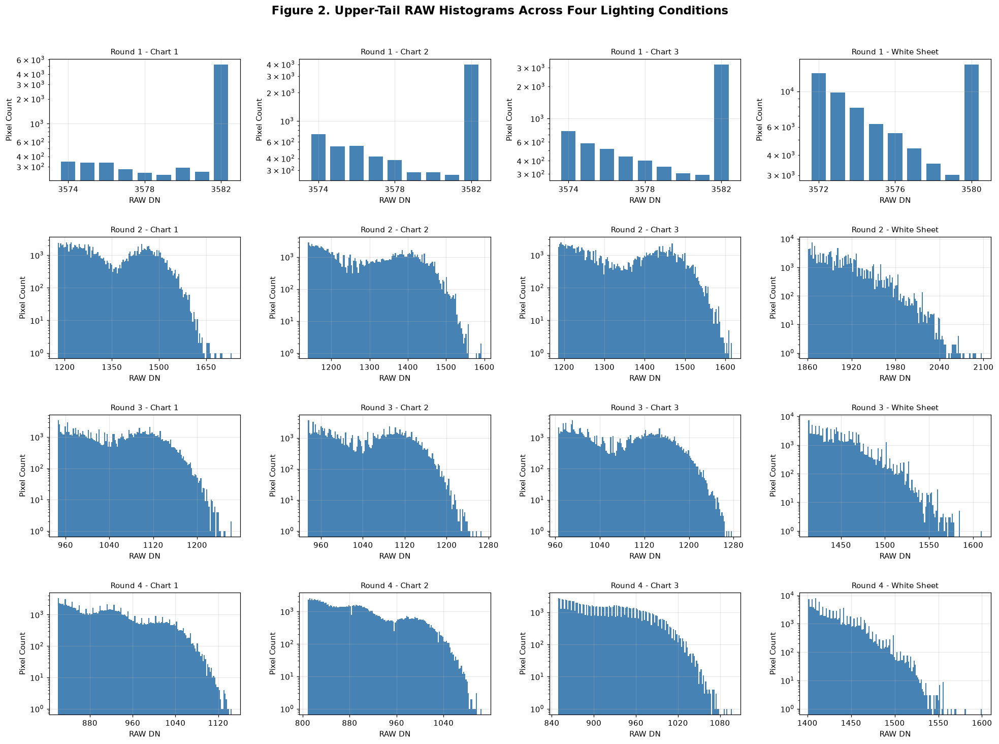

In [61]:

# ============================================================
# ColorChecker RAW inventory and clipping
# ============================================================

from pathlib import Path
import re
import numpy as np
import pandas as pd
import rawpy
import tifffile
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD ALL 16 DNG FILES
# ------------------------------------------------------------

folder = Path(str(DATA_ROOT / 'HW4_Set2'))

files = sorted(
    [f for f in folder.iterdir()
     if f.suffix.lower() == ".dng"],
    key=lambda f: tuple(map(
        int,
        re.search(r"Round(\d+)_(\d+)", f.stem).groups()
    ))
)

assert len(files) == 16, (
    f"Expected 16 DNG files, found {len(files)}"
)

# ------------------------------------------------------------
# 2. PROFESSOR'S LENS_ID ASSERTION
# ------------------------------------------------------------

def lens_id(path):
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        exif = p.tags["ExifTag"].value
        fl = exif["FocalLength"]

        return (
            exif.get("LensModel", "unknown"),
            round(fl[0] / fl[1], 3),
            exif.get("FocalLengthIn35mmFilm"),
            (
                p.tags["ImageWidth"].value,
                p.tags["ImageLength"].value
            )
        )

ids = {lens_id(f) for f in files}

print("Unique lens IDs found:", len(ids))
print("Lens ID information:", ids)

assert len(ids) == 1, (
    "Lens configurations do not match."
)

print("Lens_id assertion: PASSED")

# ------------------------------------------------------------
# 3. READ ISO AND EXPOSURE TIME
# ------------------------------------------------------------

def metadata(path):
    with tifffile.TiffFile(path) as t:
        exif = t.pages[0].tags["ExifTag"].value

        iso = exif.get(
            "ISOSpeedRatings", "Unknown"
        )

        exposure = exif.get(
            "ExposureTime", "Unknown"
        )

        return iso, exposure

# ------------------------------------------------------------
# 4. SATURATION THRESHOLDS
# ------------------------------------------------------------

# Measured from Round 1 histogram spikes.
# Other rounds use 3582 DN as an assumed threshold.

round1_sat = {
    "Round1_1.DNG": 3582,
    "Round1_2.DNG": 3582,
    "Round1_3.DNG": 3582,
    "Round1_4.DNG": 3580
}

assumed_sat = 3582

# ------------------------------------------------------------
# 5. QUESTION 1 DELIVERABLE TABLE
# ------------------------------------------------------------

rows = []

for f in files:

    round_num, image_num = map(
        int,
        re.search(
            r"Round(\d+)_(\d+)", f.stem
        ).groups()
    )

    iso, exposure = metadata(f)

    with rawpy.imread(str(f)) as raw:
        data = raw.raw_image_visible

        # Measured ceiling for Round 1;
        # assumed ceiling for Rounds 2-4.
        threshold = round1_sat.get(
            f.name, assumed_sat
        )

        fraction = np.mean(data >= threshold)

        rows.append({
            "Round": round_num,
            "Chart": (
                f"Chart {image_num}"
                if image_num <= 3
                else "White sheet"
            ),
            "File": f.name,
            "ISO": str(iso),
            "Exposure": str(exposure),
            "Saturation DN": (
                f"{threshold} (observed)"
                if round_num == 1
                else f"{threshold} (assumed)"
            ),
            "Clipped fraction": f"{fraction:.4%}"
        })

df = pd.DataFrame(rows)

# Verify consistent ISO and exposure within each round
for round_num, group in df.groupby("Round"):

    assert group["ISO"].nunique() == 1, (
        f"ISO mismatch in Round {round_num}"
    )

    assert group["Exposure"].nunique() == 1, (
        f"Exposure mismatch in Round {round_num}"
    )

    assert group["ISO"].iloc[0] != "Unknown"
    assert group["Exposure"].iloc[0] != "Unknown"

print("\nISO and exposure consistency: PASSED")

print(
    "\nTable 1. RAW Capture Settings "
    "and Saturation Measurements"
)

display(df)

# ------------------------------------------------------------
# 6. HISTOGRAMS FOR ALL FOUR LIGHTING ROUNDS
# ------------------------------------------------------------

fig, axes = plt.subplots(4, 4, figsize=(18, 13))

for i, f in enumerate(files):

    round_num, image_num = map(
        int,
        re.search(
            r"Round(\d+)_(\d+)", f.stem
        ).groups()
    )

    ax = axes.flat[i]

    with rawpy.imread(str(f)) as raw:
        data = raw.raw_image_visible

        if round_num == 1:

            # Exact pixel counts for the highest 9 DN codes
            maximum = int(data.max())

            values = np.arange(
                maximum - 8, maximum + 1
            )

            counts = [
                np.count_nonzero(data == v)
                for v in values
            ]

            ax.bar(
                values,
                counts,
                width=0.75,
                color="steelblue"
            )

            ax.set_xlim(
                maximum - 9, maximum + 1
            )

            ax.set_xticks([
                maximum - 8,
                maximum - 4,
                maximum
            ])

        else:

            # Upper 1% of RAW pixel values
            upper = data[
                data >= np.percentile(data, 99)
            ]

            ax.hist(
                upper,
                bins=150,
                color="steelblue"
            )

            ax.xaxis.set_major_locator(
                MaxNLocator(nbins=5)
            )

        # Logarithmic scale for every histogram
        ax.set_yscale("log")

        ax.set_title(
            f"Round {round_num} - "
            f"{'White Sheet' if image_num == 4 else 'Chart ' + str(image_num)}",
            fontsize=10
        )

        ax.set_xlabel("RAW DN")
        ax.set_ylabel("Pixel Count")


plt.suptitle(
    "Figure 2. Upper-Tail RAW Histograms Across Four Lighting Conditions",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

plt.tight_layout(h_pad=2.8, w_pad=2.0)
plt.show()


### 5.2 Extract linear RGB from the Bayer mosaic

Selected file: Round2_1.DNG
CFA pattern: BGGR
Black levels (DN): [528. 528. 528. 528.]
Saturation level (DN): 3582
Original RAW dimensions: (3024, 4032)
Linear RGB dimensions: (1512, 2016, 3)


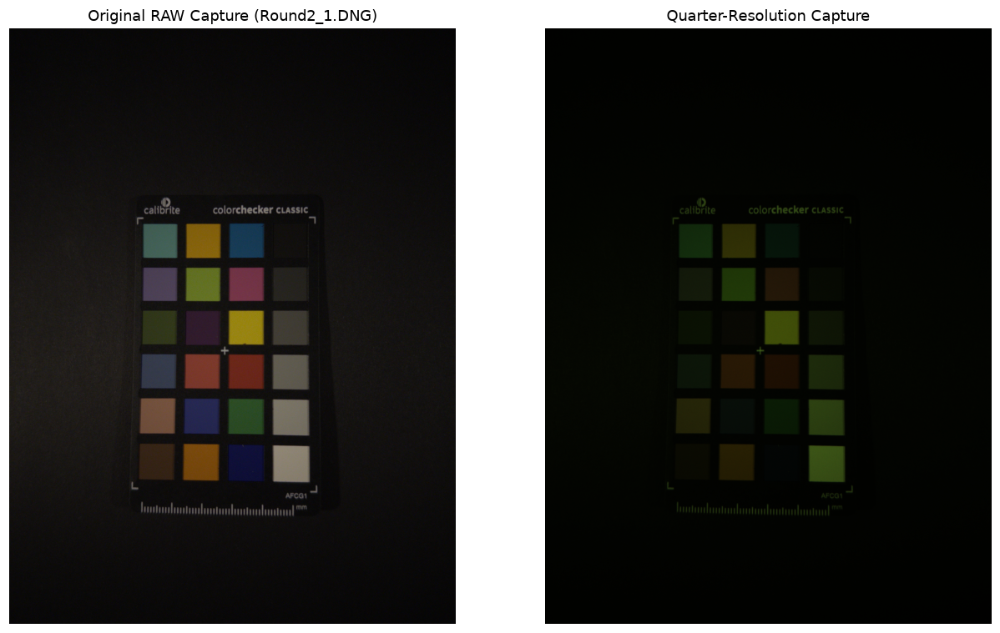

In [62]:

# ============================================================
# Linear RGB extraction from Bayer RAW
# Convert Bayer RAW to Linear RGB Without Demosaicing
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import rawpy
from pathlib import Path

# 1. Select RAW capture
folder = Path(str(DATA_ROOT / 'HW4_Set2'))
file = folder / "Round2_1.DNG"

# Measured saturation from Question 1
saturation = 3582

# 2. Read RAW mosaic
with rawpy.imread(str(file)) as raw:

    mosaic = raw.raw_image_visible.astype(np.float32)
    colors = raw.raw_colors_visible.copy()

    black_levels = np.array(
        raw.black_level_per_channel,
        dtype=np.float32
    )

    color_desc = raw.color_desc.decode("ascii")

    # Determine Bayer pattern using camera metadata
    pattern = raw.raw_pattern
    assert pattern is not None
    assert pattern.shape == (2, 2)

    cfa = [
        "".join(color_desc[k] for k in row)
        for row in pattern
    ]

    cfa_pattern = "".join(cfa)

    # 3. Subtract black level and normalize
    linear = np.empty_like(mosaic)

    for channel in np.unique(colors):
        mask = colors == channel
        black = black_levels[channel]

        linear[mask] = (
            mosaic[mask] - black
        ) / (saturation - black)

    linear = np.clip(linear, 0, 1)

    # 4. Convert each 2x2 Bayer block into RGB
    h, w = linear.shape

    h = h - h % 2
    w = w - w % 2

    linear = linear[:h, :w]
    colors = colors[:h, :w]

    blocks = np.stack([
        linear[0::2, 0::2],
        linear[0::2, 1::2],
        linear[1::2, 0::2],
        linear[1::2, 1::2]
    ], axis=-1)

    site_colors = [
        color_desc[colors[r, c]]
        for r, c in [(0,0), (0,1), (1,0), (1,1)]
    ]

    assert site_colors.count("R") == 1
    assert site_colors.count("G") == 2
    assert site_colors.count("B") == 1

    R = blocks[..., site_colors.index("R")]
    G = blocks[..., [
        i for i, color in enumerate(site_colors)
        if color == "G"
    ]].mean(axis=-1)
    B = blocks[..., site_colors.index("B")]

    rgb = np.stack([R, G, B], axis=-1)



# ============================================================
# 5. DISPLAY ORIGINAL AND LINEAR RGB IMAGES
# ============================================================

print("Selected file:", file.name)
print("CFA pattern:", cfa_pattern)
print("Black levels (DN):", black_levels)
print("Saturation level (DN):", saturation)
print("Original RAW dimensions:", mosaic.shape)
print("Linear RGB dimensions:", rgb.shape)

# Camera-processed preview for comparison
with rawpy.imread(str(file)) as raw:
    preview = raw.postprocess(
        use_camera_wb=True,
        no_auto_bright=True,
        output_bps=8
    )

# Rotate linear RGB image to match portrait orientation
rgb_display = np.rot90(rgb, k=3)

fig, axes = plt.subplots(1, 2, figsize=(12, 7))

axes[0].imshow(preview)
axes[0].set_title("Original RAW Capture (Round2_1.DNG)")
axes[0].axis("off")

axes[1].imshow(rgb_display)
axes[1].set_title("Quarter-Resolution Capture")
axes[1].axis("off")

plt.tight_layout()
plt.show()


### 5.3 Correct lens shading using white-sheet images

Selected round: 2
Chart: Round2_1.DNG
White sheet: Round2_4.DNG
Red: corner/center before = 0.370, after = 0.997
Green: corner/center before = 0.368, after = 0.996
Blue: corner/center before = 0.376, after = 1.000


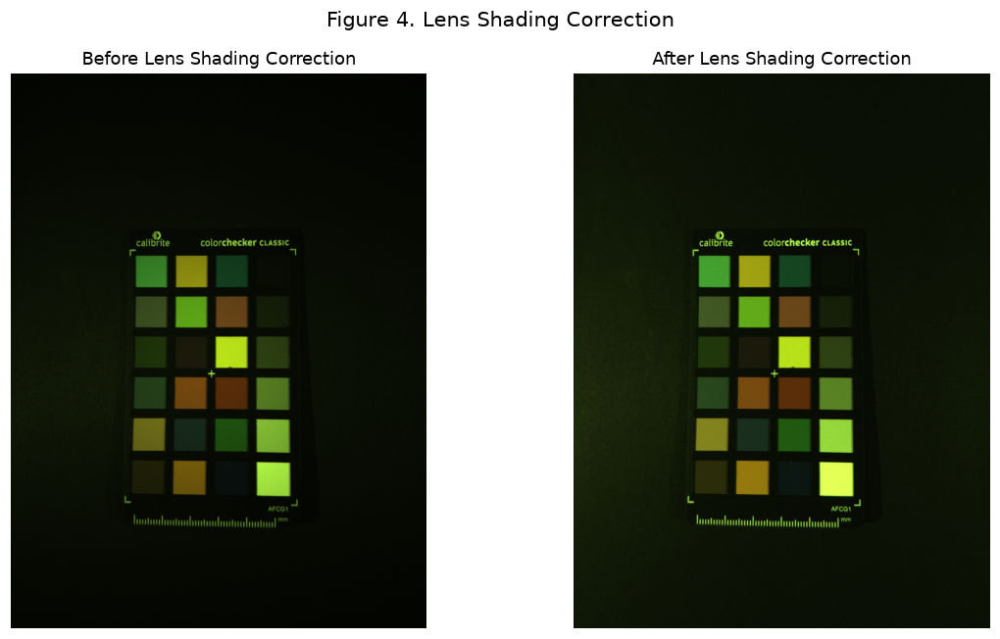

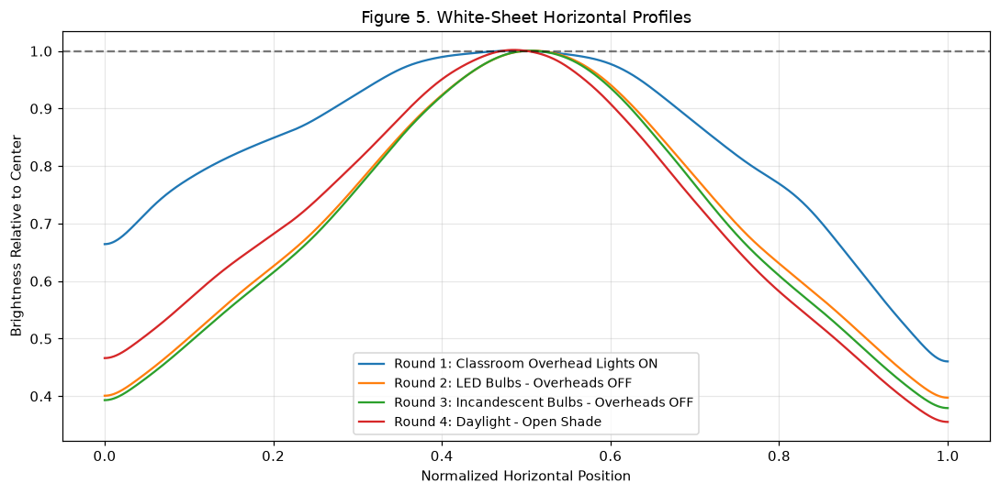

In [63]:

# ============================================================
# White-sheet lens-shading correction
# Lens Shading Correction Using White Sheet
# ============================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import rawpy
import cv2

folder = Path(str(DATA_ROOT / 'HW4_Set2'))

# Choose one round for the before/after correction
round_num = 2
saturation = 3582  # Provisional ceiling from Q1

chart_file = folder / f"Round{round_num}_1.DNG"
white_file = folder / f"Round{round_num}_4.DNG"

# ------------------------------------------------------------
# 1. RAW to quarter-resolution linear RGB
# ------------------------------------------------------------

def linear_rgb(path):
    with rawpy.imread(str(path)) as raw:
        mosaic = raw.raw_image_visible.astype(np.float32)
        color_indices = raw.raw_colors_visible
        blacks = np.array(
            raw.black_level_per_channel,
            dtype=np.float32
        )

        desc = raw.color_desc.decode("ascii")

        # Black subtraction and normalization
        linear = np.zeros_like(mosaic)

        for k in np.unique(color_indices):
            mask = color_indices == k
            linear[mask] = (
                mosaic[mask] - blacks[k]
            ) / (saturation - blacks[k])

        linear = np.maximum(linear, 0)

        # Get each of the four Bayer sites
        sites = [
            linear[0::2, 0::2],
            linear[0::2, 1::2],
            linear[1::2, 0::2],
            linear[1::2, 1::2]
        ]

        site_colors = [
            desc[color_indices[r, c]]
            for r, c in [(0,0), (0,1), (1,0), (1,1)]
        ]

        assert site_colors.count("R") == 1
        assert site_colors.count("G") == 2
        assert site_colors.count("B") == 1

        R = sites[site_colors.index("R")]

        G = np.mean(
            [sites[i] for i, c in enumerate(site_colors)
             if c == "G"],
            axis=0
        )

        B = sites[site_colors.index("B")]

        return np.stack([R, G, B], axis=-1)


# ------------------------------------------------------------
# 2. Load chart and matching white sheet
# ------------------------------------------------------------

chart = linear_rgb(chart_file)
white = linear_rgb(white_file)

# Smooth white sheet to reduce sensor noise
flat = cv2.GaussianBlur(
    white, (0, 0), sigmaX=35, sigmaY=35
)

# Use a small center region for reference
h, w, _ = flat.shape
cy, cx = h // 2, w // 2

center = flat[
    cy-25:cy+25,
    cx-25:cx+25
].mean(axis=(0, 1))

# Normalize each RGB channel to its center
flat_normalized = flat / center.reshape(1, 1, 3)

# Correct chart using separate RGB flat fields
corrected = chart / np.maximum(
    flat_normalized, 1e-6
)

# ------------------------------------------------------------
# 3. Corner-to-center ratios
# ------------------------------------------------------------

# Upper-left corner region, avoiding image boundaries
ys = slice(int(0.05*h), int(0.10*h))
xs = slice(int(0.05*w), int(0.10*w))

before_ratio = (
    white[ys, xs].mean(axis=(0, 1)) /
    white[cy-25:cy+25, cx-25:cx+25].mean(axis=(0, 1))
)

white_corrected = white / np.maximum(
    flat_normalized, 1e-6
)

after_ratio = (
    white_corrected[ys, xs].mean(axis=(0, 1)) /
    white_corrected[
        cy-25:cy+25, cx-25:cx+25
    ].mean(axis=(0, 1))
)

print("Selected round:", round_num)
print("Chart:", chart_file.name)
print("White sheet:", white_file.name)

for i, name in enumerate(["Red", "Green", "Blue"]):
    print(
        f"{name}: corner/center "
        f"before = {before_ratio[i]:.3f}, "
        f"after = {after_ratio[i]:.3f}"
    )

# ------------------------------------------------------------
# 4. Figure: Before and after correction
# ------------------------------------------------------------

# Rotate for correct portrait orientation
before_display = np.rot90(chart, k=3)
after_display = np.rot90(corrected, k=3)

# Same display gain for a fair comparison
gain = 0.85 / max(
    np.percentile(before_display, 99.5),
    np.percentile(after_display, 99.5)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 6))

axes[0].imshow(
    np.clip(before_display * gain, 0, 1)
)
axes[0].set_title("Before Lens Shading Correction")
axes[0].axis("off")

axes[1].imshow(
    np.clip(after_display * gain, 0, 1)
)
axes[1].set_title("After Lens Shading Correction")
axes[1].axis("off")

plt.suptitle(
    "Figure 4. Lens Shading Correction",
    fontsize=14
)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 5. Horizontal profiles for all four rounds
# ------------------------------------------------------------

lighting = {
    1: "Classroom Overhead Lights ON",
    2: "LED Bulbs - Overheads OFF",
    3: "Incandescent Bulbs - Overheads OFF",
    4: "Daylight - Open Shade"
}

plt.figure(figsize=(10, 5))

for r in [1, 2, 3, 4]:

    white_r = linear_rgb(
        folder / f"Round{r}_4.DNG"
    )

    smooth = cv2.GaussianBlur(
        white_r, (0, 0), sigmaX=35, sigmaY=35
    )

    hh, ww, _ = smooth.shape

    # Average a small horizontal band through center
    profile = smooth[
        hh//2-10:hh//2+10
    ].mean(axis=(0, 2))

    # Normalize each round to its own center
    reference = profile[
        ww//2-25:ww//2+25
    ].mean()

    profile = profile / reference

    plt.plot(
        np.arange(ww) / (ww - 1),
        profile,
        label=f"Round {r}: {lighting[r]}"
    )

plt.axhline(1, color="black",
            linestyle="--", alpha=0.5)

plt.xlabel("Normalized Horizontal Position")
plt.ylabel("Brightness Relative to Center")
plt.title(
    "Figure 5. White-Sheet Horizontal Profiles"
)
plt.legend(fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 5.4 Sample the 24 ColorChecker patches

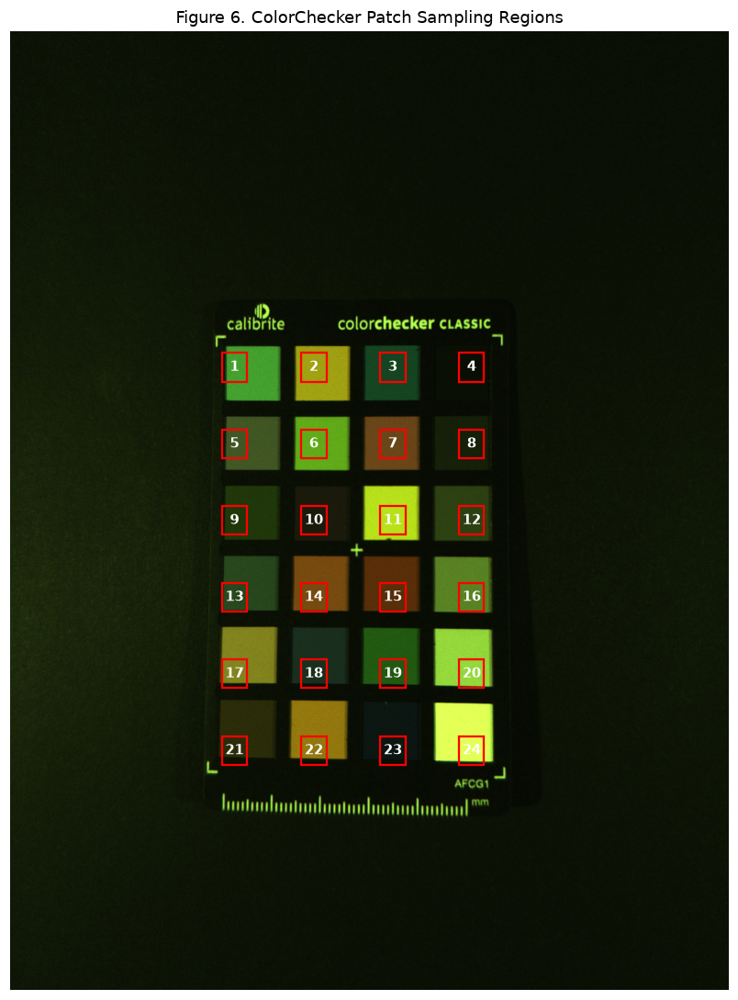

Table 2. Mean Linear RGB Values of 24 ColorChecker Patches


,Patch,R,G,B
0,1,0.07903,0.18278,0.05396
1,2,0.21910,0.21919,0.02534
2,3,0.02880,0.09344,0.04560
3,4,0.01384,0.02000,0.00577
4,5,0.07673,0.10326,0.04221
5,6,0.13231,0.23248,0.03405
6,7,0.14313,0.09533,0.03319
7,8,0.02939,0.04304,0.01216
8,9,0.04094,0.06925,0.01373
9,10,0.03634,0.03586,0.01530


Patch RGB array shape: (24, 3)

Patch Clipping Check


,Patch,Maximum RAW DN,Clipped blocks,Status
0,1,1143,0,OK
1,2,1202,0,OK
2,3,840,0,OK
3,4,608,0,OK
4,5,909,0,OK
5,6,1329,0,OK
6,7,1035,0,OK
7,8,697,0,OK
8,9,789,0,OK
9,10,691,0,OK


Valid patches: 24 / 24
Excluded patches: []


In [64]:

# ============================================================
# ColorChecker patch sampling
# Centered ColorChecker Sampling Regions
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rawpy

from pathlib import Path
from matplotlib.patches import Rectangle
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD CORRECTED IMAGE FROM QUESTION 3
# ------------------------------------------------------------

assert "corrected" in globals(), "Run Q3 first."
assert round_num == 2, "Q3 must use Round 2."

folder = Path(str(DATA_ROOT / 'HW4_Set2'))
file = folder / "Round2_1.DNG"

# Rotate image to upright orientation
img = np.rot90(corrected, k=3)
H, W = img.shape[:2]

# ------------------------------------------------------------
# 2. PATCH GRID LOCATION
# ------------------------------------------------------------

# Chart patch centers based on your Round 2 layout.
# Adjust these four boundaries only if necessary.

# Approximate first and last column centers
x_first = 0.312 * W
x_last  = 0.642 * W

# Approximate first and last row centers
y_first = 0.350 * H
y_last  = 0.750 * H

# Generate evenly spaced centers
x_centers = np.linspace(x_first, x_last, 4)
y_centers = np.linspace(y_first, y_last, 6)

# Sampling box dimensions
box_w = 0.035 * W
box_h = 0.030 * H

# ------------------------------------------------------------
# 3. SHOW PATCH REGIONS AND MEASURE RGB
# ------------------------------------------------------------

gain = 0.85 / max(np.percentile(img, 99.5), 1e-6)

fig, ax = plt.subplots(figsize=(8, 10))
ax.imshow(np.clip(img * gain, 0, 1))
ax.set_title("Figure 6. ColorChecker Patch Sampling Regions")
ax.axis("off")

records = []
regions = []

patch_number = 1

for cy in y_centers:
    for cx in x_centers:

        x0 = int(round(cx - box_w / 2))
        x1 = int(round(cx + box_w / 2))
        y0 = int(round(cy - box_h / 2))
        y1 = int(round(cy + box_h / 2))

        patch = img[y0:y1, x0:x1]

        if patch.size == 0:
            raise ValueError(
                f"Patch {patch_number}: empty region."
            )

        mean_rgb = patch.mean(axis=(0, 1))

        records.append({
            "Patch": patch_number,
            "R": mean_rgb[0],
            "G": mean_rgb[1],
            "B": mean_rgb[2]
        })

        regions.append((x0, y0, x1, y1))

        # Red rectangle
        ax.add_patch(
            Rectangle(
                (x0, y0),
                x1-x0,
                y1-y0,
                edgecolor="red",
                facecolor="none",
                linewidth=1.5
            )
        )

        # White number centered in rectangle
        ax.text(
            (x0+x1)/2,
            (y0+y1)/2,
            str(patch_number),
            color="white",
            fontsize=10,
            fontweight="bold",
            ha="center",
            va="center"
        )

        patch_number += 1

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 4. DISPLAY 24 x 3 PATCH-MEAN TABLE
# ------------------------------------------------------------

patch_df = pd.DataFrame(records)

print("Table 2. Mean Linear RGB Values of 24 ColorChecker Patches")
display(patch_df.round(5))

patch_rgb = patch_df[["R", "G", "B"]].to_numpy()

print("Patch RGB array shape:", patch_rgb.shape)

# ------------------------------------------------------------
# 5. CHECK RAW CLIPPING
# ------------------------------------------------------------

saturation = 3582  # Assumed ceiling from Q1

with rawpy.imread(str(file)) as raw:
    mosaic = raw.raw_image_visible.copy()

# Highest original RAW value in each 2x2 block
block_max = np.maximum.reduce([
    mosaic[0::2, 0::2],
    mosaic[0::2, 1::2],
    mosaic[1::2, 0::2],
    mosaic[1::2, 1::2]
])

raw_max_upright = np.rot90(block_max, k=3)

clipping_results = []

for n, (x0, y0, x1, y1) in enumerate(regions, start=1):

    region = raw_max_upright[y0:y1, x0:x1]

    max_dn = int(region.max())
    clipped = int(np.count_nonzero(region >= saturation))

    clipping_results.append({
        "Patch": n,
        "Maximum RAW DN": max_dn,
        "Clipped blocks": clipped,
        "Status": "CLIPPED" if clipped > 0 else "OK"
    })

clip_patch_df = pd.DataFrame(clipping_results)

print("\nPatch Clipping Check")
display(clip_patch_df)

valid_mask = clip_patch_df["Status"].to_numpy() == "OK"

print("Valid patches:", valid_mask.sum(), "/ 24")
print(
    "Excluded patches:",
    clip_patch_df.loc[~valid_mask, "Patch"].tolist()
)


### 5.5 Apply white balance and load reference colors

In [65]:

# ============================================================
# White balance and published reference colors
# White Balance and ColorChecker24 Reference
# ============================================================

import numpy as np
import pandas as pd
import colour
from IPython.display import display

# ------------------------------------------------------------
# 1. LOAD RGB MEASUREMENTS FROM QUESTION 4
# ------------------------------------------------------------

# Run Q4 first to create patch_rgb and valid_mask
assert "patch_rgb" in globals(), "Run Q4 first."
assert "valid_mask" in globals(), "Run the Q4 clipping check first."

assert patch_rgb.shape == (24, 3)
assert len(valid_mask) == 24

# ------------------------------------------------------------
# 2. LOAD PUBLISHED COLORCHECKER REFERENCE
# ------------------------------------------------------------

checker = colour.CCS_COLOURCHECKERS[
    "ColorChecker24 - After November 2014"
]

# Reference xyY values
patch_names = list(checker.data.keys())

xyY = np.array(
    list(checker.data.values()),
    dtype=float
)

# Convert xyY to XYZ
reference_XYZ = colour.xyY_to_XYZ(xyY)

assert reference_XYZ.shape == (24, 3)

print("Reference: ColorChecker24 - After November 2014")
print("Reference XYZ shape:", reference_XYZ.shape)

# ------------------------------------------------------------
# 3. MATCH CAMERA PATCHES TO REFERENCE ORDER
# ------------------------------------------------------------

# Your Q4 image has 4 columns and 6 rows.
# The standard reference has 6 columns and 4 rows.
#
# Mapping based on the clockwise-rotated layout
# shown in your Round 2 ColorChecker image.
#
# Standard Patch 1 = Dark Skin (Q4 position 21)
# Standard Patch 19 = White (Q4 position 24)

patch_order = [
    21, 17, 13, 9, 5, 1,
    22, 18, 14, 10, 6, 2,
    23, 19, 15, 11, 7, 3,
    24, 20, 16, 12, 8, 4
]

indices = np.array(patch_order) - 1

camera_rgb = patch_rgb[indices].copy()
reference_valid = np.asarray(valid_mask, dtype=bool)[indices]

# Verify expected neutral positions
print("\nReference patch mapping:")
print("Patch 1 - Dark Skin: Q4 position", patch_order[0])
print("Patch 19 - White: Q4 position", patch_order[18])
print("Patch 21 - Neutral 6.5: Q4 position", patch_order[20])

# ------------------------------------------------------------
# 4. SELECT AN UNCLIPPED MID-GRAY PATCH
# ------------------------------------------------------------

# Standard Patch 21 is Neutral 6.5.
# This is a mid-gray rather than the bright white patch.

gray_patch = 21
gray_index = gray_patch - 1

assert reference_valid[gray_index], (
    "Selected gray patch is clipped."
)

gray_rgb = camera_rgb[gray_index]

R_gray, G_gray, B_gray = gray_rgb

assert np.all(gray_rgb > 0), (
    "Gray patch contains nonpositive RGB values."
)

print("\nSelected neutral patch:", gray_patch)
print("Measured neutral RGB:", gray_rgb)

# ------------------------------------------------------------
# 5. CALCULATE WHITE BALANCE GAINS
# ------------------------------------------------------------

# Normalize gains to the green channel

gain_R = G_gray / R_gray
gain_G = 1.0
gain_B = G_gray / B_gray

gains = np.array([
    gain_R,
    gain_G,
    gain_B
])

print("\nWhite Balance Gains (normalized to green)")
print(f"Red gain:   {gain_R:.5f}")
print(f"Green gain: {gain_G:.5f}")
print(f"Blue gain:  {gain_B:.5f}")

# ------------------------------------------------------------
# 6. APPLY WHITE BALANCE TO ALL 24 PATCHES
# ------------------------------------------------------------

balanced_rgb = camera_rgb * gains

balanced_df = pd.DataFrame({
    "Patch": np.arange(1, 25),
    "R": balanced_rgb[:, 0],
    "G": balanced_rgb[:, 1],
    "B": balanced_rgb[:, 2]
})

print("\nTable 3. White-Balanced Linear RGB Patch Means")
display(balanced_df.round(5))

# ------------------------------------------------------------
# 7. VERIFY THE NEUTRAL PATCHES
# ------------------------------------------------------------

neutral_df = balanced_df.iloc[18:24].copy()

print("\nNeutral Patches 19-24 After White Balance")
display(neutral_df.round(5))

# Selected mid-gray should have equal channels
print("\nSelected mid-gray after balancing:")
print(balanced_rgb[gray_index])

# ------------------------------------------------------------
# 8. KEEP ARRAYS FOR QUESTIONS 6-8
# ------------------------------------------------------------

# c = measured camera RGB
# t = published XYZ tristimulus values

c = camera_rgb
c_WB = balanced_rgb
t = reference_XYZ

print("\nCamera RGB shape:", c.shape)
print("White-balanced RGB shape:", c_WB.shape)
print("Reference XYZ shape:", t.shape)
print("Valid patches:", reference_valid.sum(), "/ 24")


Reference: ColorChecker24 - After November 2014
Reference XYZ shape: (24, 3)

Reference patch mapping:
Patch 1 - Dark Skin: Q4 position 21
Patch 19 - White: Q4 position 24
Patch 21 - Neutral 6.5: Q4 position 16

Selected neutral patch: 21
Measured neutral RGB: [ 0.1212  0.1767  0.0486]

White Balance Gains (normalized to green)
Red gain:   1.45810
Green gain: 1.00000
Blue gain:  3.63858

Table 3. White-Balanced Linear RGB Patch Means


,Patch,R,G,B
0,1,0.06885,0.05115,0.04178
1,2,0.21888,0.15325,0.12883
2,3,0.07477,0.09101,0.13495
3,4,0.05970,0.06925,0.04997
4,5,0.11188,0.10326,0.15358
5,6,0.11524,0.18278,0.19635
6,7,0.23592,0.13418,0.06123
7,8,0.04685,0.05702,0.12859
8,9,0.22971,0.09926,0.07714
9,10,0.05299,0.03586,0.05567



Neutral Patches 19-24 After White Balance


,Patch,R,G,B
18,19,0.40276,0.39770,0.39057
19,20,0.27738,0.27834,0.27798
20,21,0.17668,0.17668,0.17668
21,22,0.08957,0.08860,0.08889
22,23,0.04285,0.04304,0.04425
23,24,0.02017,0.02000,0.02100



Selected mid-gray after balancing:
[ 0.1767  0.1767  0.1767]

Camera RGB shape: (24, 3)
White-balanced RGB shape: (24, 3)
Reference XYZ shape: (24, 3)
Valid patches: 24 / 24


### 5.6 Calculate before-CCM color error with exposure correction

In [66]:
# ============================================================
# Before-CCM color error (exposure normalized)
# ============================================================
import numpy as np
import pandas as pd
import colour
from IPython.display import display

assert c_WB.shape == (24, 3) and t.shape == (24, 3), "Run Question 5 first"
valid_q6 = np.asarray(reference_valid, dtype=bool)
assert valid_q6[18], "Reference white patch 19 is clipped"

M_sRGB = colour.RGB_COLOURSPACES["sRGB"].matrix_RGB_to_XYZ
XYZ_before = c_WB @ M_sRGB.T
XYZ_reference = t.copy()
white_index = 18  # Published Patch 19 (white)
Y_ref = float(XYZ_reference[white_index, 1])
white_xy = colour.XYZ_to_xy(XYZ_reference[white_index])
Y_measured = float(XYZ_before[white_index, 1])
assert Y_measured > 0
q6_scale = Y_ref / Y_measured
XYZ_before_scaled = XYZ_before * q6_scale

Lab_reference = colour.XYZ_to_Lab(XYZ_reference / Y_ref, illuminant=white_xy)
Lab_before = colour.XYZ_to_Lab(XYZ_before_scaled / Y_ref, illuminant=white_xy)
DE_before = np.asarray(colour.delta_E(Lab_before, Lab_reference, method="CIE 2000"), dtype=float)
DE_before[~valid_q6] = np.nan

print("QUESTION 6 - CORRECTED")
print("Metric: CIEDE2000")
print(f"Measured white Y: {Y_measured:.5f}; Reference white Y: {Y_ref:.5f}")
print(f"Exposure scale: {q6_scale:.5f}")
print(f"Mean Delta E: {np.nanmean(DE_before):.3f}")
print(f"Worst Delta E: {np.nanmax(DE_before):.3f}")
print(f"Worst patch: {np.nanargmax(DE_before)+1}")
q6_df = pd.DataFrame({"Patch": np.arange(1, 25), "Name": patch_names, "Delta E 00": DE_before})
display(q6_df.round(3))


QUESTION 6 - CORRECTED
Metric: CIEDE2000
Measured white Y: 0.39826; Reference white Y: 0.88069
Exposure scale: 2.21135
Mean Delta E: 13.047
Worst Delta E: 22.904
Worst patch: 14


,Patch,Name,Delta E 00
0,1,dark skin,16.103
1,2,light skin,16.937
2,3,blue sky,3.740
3,4,foliage,17.808
4,5,blue flower,4.249
5,6,bluish green,19.544
6,7,orange,16.221
7,8,purplish blue,3.885
8,9,moderate red,14.821
9,10,purple,9.694


### 5.7 Fit the 3 × 3 color correction matrix

In [67]:

# ============================================================
# Least-squares 3 × 3 color correction matrix
# Fit a 3x3 Color Correction Matrix (Least Squares)
# ============================================================

import numpy as np

# Q5 outputs:
# c_WB = white-balanced camera RGB, shape (24, 3)
# t    = published reference XYZ, shape (24, 3)

assert c_WB.shape == (24, 3)
assert t.shape == (24, 3)

# Only use valid (unclipped) patches
valid = np.asarray(reference_valid, dtype=bool)

# Fit: c_WB @ M.T ≈ t
M_T, residuals, rank, singular_values = np.linalg.lstsq(
    c_WB[valid],
    t[valid],
    rcond=None
)

M = M_T.T

# Display fitted 3x3 matrix
print("QUESTION 7 - FITTED COLOR CORRECTION MATRIX")
print("\nM =")
print(np.round(M, 5))

# Check row sums
row_sums = M.sum(axis=1)

print("\nMatrix row sums:")
print(f"X row: {row_sums[0]:.5f}")
print(f"Y row: {row_sums[1]:.5f}")
print(f"Z row: {row_sums[2]:.5f}")

# Check the result for a neutral RGB input [1, 1, 1]
neutral_output = M @ np.ones(3)

print("\nOutput for neutral RGB [1, 1, 1]:")
print(np.round(neutral_output, 5))

# Save predicted XYZ values for Question 8
corrected_XYZ = c_WB @ M.T

print("\nPredicted XYZ shape:", corrected_XYZ.shape)


# Professor's feedback: evaluate neutral chromaticity,
# not whether raw row sums are close to 1.
neutral_XYZ = M @ np.ones(3)
neutral_xy = colour.XYZ_to_xy(neutral_XYZ)
reference_xy = colour.XYZ_to_xy(t[18])
print("\nNeutral XYZ normalized by Y:", np.round(neutral_XYZ / neutral_XYZ[1], 5))
print("Fitted neutral xy:", np.round(neutral_xy, 5))
print("Reference patch 19 xy:", np.round(reference_xy, 5))
print("The row sums' overall scale reflects luminance/exposure; compare xy for neutrality.")


QUESTION 7 - FITTED COLOR CORRECTION MATRIX

M =
[[ 1.0489  0.547   0.4076]
 [ 0.0108  1.9267  0.1759]
 [ 0.0458 -0.9444  2.6034]]

Matrix row sums:
X row: 2.00338
Y row: 2.11336
Z row: 1.70485

Output for neutral RGB [1, 1, 1]:
[ 2.0034  2.1134  1.7048]

Predicted XYZ shape: (24, 3)

Neutral XYZ normalized by Y: [ 0.948   1.      0.8067]
Fitted neutral xy: [ 0.3441  0.363 ]
Reference patch 19 xy: [ 0.3489  0.3642]
The row sums' overall scale reflects luminance/exposure; compare xy for neutrality.


### 5.8 Compare per-patch color error before and after CCM

QUESTION 8 - CORRECTED
Mean before: 13.047; worst: 22.904
Mean after: 3.298; worst: 7.606
Worst after patch: 15


,Patch,Name,Before CCM,After CCM
14,15,red,15.060,7.606
17,18,cyan,14.772,5.896
7,8,purplish blue,3.885,4.795


,Patch,Name,Before CCM,After CCM
0,1,dark skin,16.103,4.289
1,2,light skin,16.937,4.303
2,3,blue sky,3.740,2.732
3,4,foliage,17.808,3.047
4,5,blue flower,4.249,1.350
5,6,bluish green,19.544,4.390
6,7,orange,16.221,3.745
7,8,purplish blue,3.885,4.795
8,9,moderate red,14.821,3.123
9,10,purple,9.694,4.026


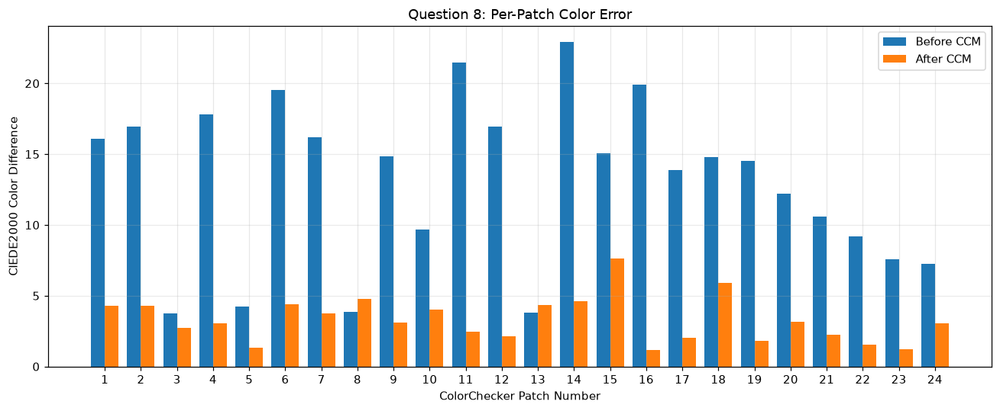

Residual errors: a 3x3 CCM cannot in general overcome camera/eye spectral
sensitivity differences (Luther condition); the CCM fits XYZ, not Delta E directly.


In [68]:
# ============================================================
# Per-patch CIEDE2000 before and after CCM
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import colour
from IPython.display import display

assert M.shape == (3, 3), "Run Question 7 first"
valid_q8 = np.asarray(reference_valid, dtype=bool)
white_idx = 18
ref_XYZ = t.copy()
Y_ref = float(ref_XYZ[white_idx, 1])
white_xy = colour.XYZ_to_xy(ref_XYZ[white_idx])

M_sRGB = colour.RGB_COLOURSPACES["sRGB"].matrix_RGB_to_XYZ
XYZ_pre = c_WB @ M_sRGB.T
XYZ_post = c_WB @ M.T
scale_pre = Y_ref / float(XYZ_pre[white_idx, 1])
XYZ_pre = XYZ_pre * scale_pre
Lab_ref = colour.XYZ_to_Lab(ref_XYZ / Y_ref, illuminant=white_xy)
Lab_pre = colour.XYZ_to_Lab(XYZ_pre / Y_ref, illuminant=white_xy)
Lab_post = colour.XYZ_to_Lab(XYZ_post / Y_ref, illuminant=white_xy)
DE_before = np.asarray(colour.delta_E(Lab_pre, Lab_ref, method="CIE 2000"), float)
DE_after = np.asarray(colour.delta_E(Lab_post, Lab_ref, method="CIE 2000"), float)
DE_before[~valid_q8] = np.nan
DE_after[~valid_q8] = np.nan

q8_df = pd.DataFrame({"Patch": np.arange(1, 25), "Name": patch_names,
                      "Before CCM": DE_before, "After CCM": DE_after})
print("QUESTION 8 - CORRECTED")
print(f"Mean before: {np.nanmean(DE_before):.3f}; worst: {np.nanmax(DE_before):.3f}")
print(f"Mean after: {np.nanmean(DE_after):.3f}; worst: {np.nanmax(DE_after):.3f}")
print("Worst after patch:", np.nanargmax(DE_after)+1)
display(q8_df.nlargest(3, "After CCM").round(3))
display(q8_df.round(3))

x = np.arange(1,25)
fig, ax = plt.subplots(figsize=(12,5))
ax.bar(x-0.19, DE_before, width=0.38, label="Before CCM")
ax.bar(x+0.19, DE_after, width=0.38, label="After CCM")
ax.set(xlabel="ColorChecker Patch Number", ylabel="CIEDE2000 Color Difference",
       title="Question 8: Per-Patch Color Error")
ax.set_xticks(x)
ax.legend(); ax.grid(axis="y", alpha=0.25)
plt.tight_layout(); plt.show()
print("Residual errors: a 3x3 CCM cannot in general overcome camera/eye spectral")
print("sensitivity differences (Luther condition); the CCM fits XYZ, not Delta E directly.")


### 5.9 Find and evaluate three ColorChecker charts

Using existing normalized flat field.
Loaded three corrected chart images.

Chart 1: Original Q4 reference grid

Chart 2: Matching score = 0.978, Scale = 1.080

Chart 3: Matching score = 0.943, Scale = 1.100


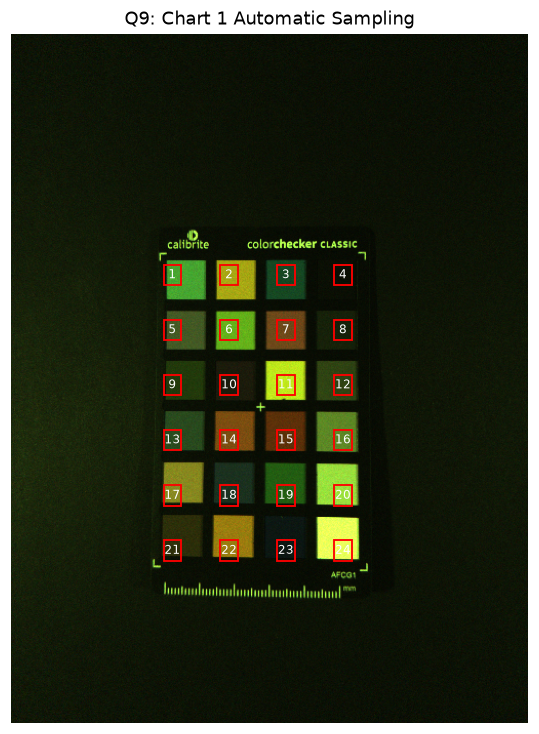

Chart 1: 24/24 valid patches


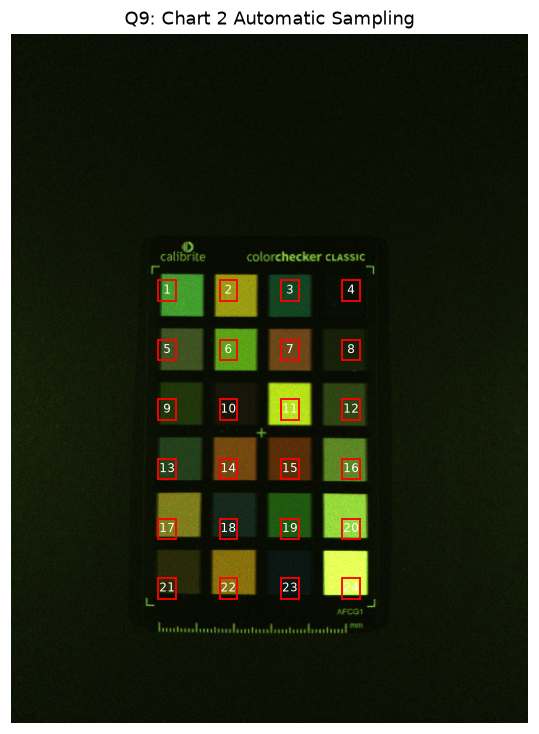

Chart 2: 24/24 valid patches


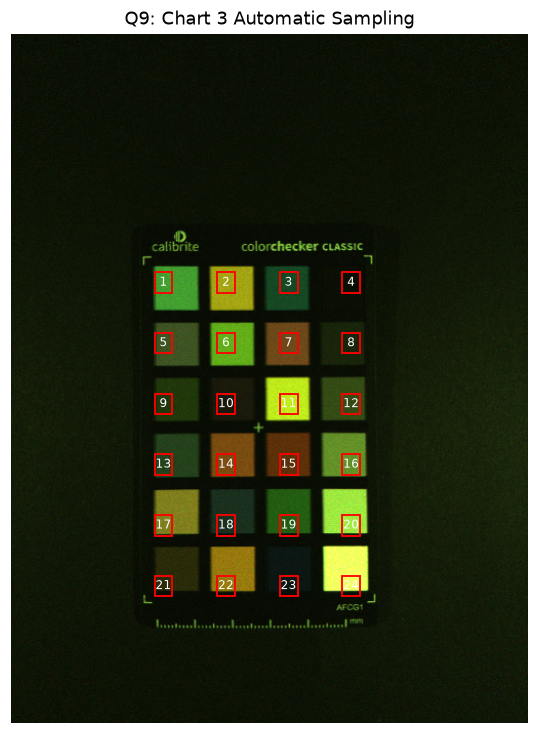

Chart 3: 24/24 valid patches

QUESTION 9 - THREE CHART COMPARISON
Metric: CIEDE2000 (Delta E 00)


,Chart,Mean DE00,Worst DE00,Worst Patch,Valid Patches
0,1,3.284,7.622,15,24
1,2,3.427,7.302,15,24
2,3,3.707,7.731,15,24



Chart 1: White Balance Gains
[ 1.4587  1.      3.6384]

Chart 1: Fitted 3x3 Matrix
[[ 1.0414  0.5607  0.3963]
 [ 0.0108  1.9319  0.1656]
 [ 0.0478 -0.9398  2.5912]]

Chart 2: White Balance Gains
[ 1.4604  1.      3.6262]

Chart 2: Fitted 3x3 Matrix
[[ 1.0778  0.6159  0.4269]
 [ 0.0234  2.0077  0.204 ]
 [ 0.0552 -0.9488  2.6816]]

Chart 3: White Balance Gains
[ 1.4588  1.      3.6207]

Chart 3: Fitted 3x3 Matrix
[[ 1.0793  0.5207  0.4557]
 [ 0.0635  1.8664  0.2324]
 [ 0.0902 -0.9707  2.5974]]

MATRIX COLUMN DIRECTION SIMILARITY
(1.000 means identical direction)
Charts 1 vs 2: R=0.9999, G=0.9998, B=0.9999
Charts 1 vs 3: R=0.9981, G=0.9996, B=0.9995
Charts 2 vs 3: R=0.9988, G=0.9989, B=0.9998


In [69]:

# ============================================================
# Automatic ColorChecker alignment and accuracy
# AUTOMATIC COLORCHECKER ALIGNMENT AND COLOR ACCURACY
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import rawpy
import colour

from pathlib import Path
from matplotlib.patches import Rectangle
from IPython.display import display

# ------------------------------------------------------------
# 1. FILES AND SETTINGS
# ------------------------------------------------------------

folder = Path(str(DATA_ROOT / 'HW4_Set2'))

chart_files = [
    folder / "Round2_1.DNG",
    folder / "Round2_2.DNG",
    folder / "Round2_3.DNG"
]

white_file = folder / "Round2_4.DNG"

SATURATION = 3582.0

# Q4 verified sampling positions for Chart 1
REF_X_FIRST = 0.312
REF_X_LAST  = 0.642
REF_Y_FIRST = 0.350
REF_Y_LAST  = 0.750

BOX_W_FRAC = 0.035
BOX_H_FRAC = 0.030

for f in chart_files + [white_file]:
    assert f.exists(), f"Missing file: {f}"

# ------------------------------------------------------------
# 2. CONVERT RAW BAYER TO LINEAR RGB
# ------------------------------------------------------------

def linear_rgb(path):

    with rawpy.imread(str(path)) as raw:

        mosaic = raw.raw_image_visible.astype(np.float32)
        colors = raw.raw_colors_visible.copy()

        black_levels = np.array(
            raw.black_level_per_channel,
            dtype=np.float32
        )

        color_desc = raw.color_desc.decode("ascii")
        pattern = raw.raw_pattern.copy()

        linear = np.zeros_like(mosaic)

        for ch in range(4):

            mask = colors == ch
            black = black_levels[ch]

            linear[mask] = (
                mosaic[mask] - black
            ) / (SATURATION - black)

        linear = np.clip(linear, 0, 1)

        channels = {}

        for row in range(2):
            for col in range(2):

                ch_index = int(pattern[row, col])
                name = color_desc[ch_index]

                values = linear[row::2, col::2]

                channels.setdefault(name, []).append(values)

        R = np.mean(channels["R"], axis=0)
        G = np.mean(channels["G"], axis=0)
        B = np.mean(channels["B"], axis=0)

        rgb = np.stack([R, G, B], axis=-1)

    return rgb

# ------------------------------------------------------------
# 3. LENS-SHADING CORRECTION
# ------------------------------------------------------------

# Reuse Q9 flat field if available, otherwise generate it.

if "flat_normalized" in globals():

    shading = np.asarray(
        flat_normalized, dtype=np.float32
    )

    print("Using existing normalized flat field.")

else:

    white_rgb = linear_rgb(white_file)

    flat = cv2.GaussianBlur(
        white_rgb, (0, 0),
        sigmaX=35,
        sigmaY=35
    )

    h, w = flat.shape[:2]

    center = flat[
        int(0.45*h):int(0.55*h),
        int(0.45*w):int(0.55*w)
    ].mean(axis=(0, 1))

    shading = flat / np.maximum(center, 1e-8)

    print("Calculated normalized flat field.")

# Load all three charts
images = []

for path in chart_files:

    rgb = linear_rgb(path)

    assert rgb.shape == shading.shape, (
        "Chart and flat-field shapes do not match."
    )

    corrected = rgb / np.maximum(shading, 1e-6)

    # Match the portrait orientation from Q4
    upright = np.rot90(corrected, k=3)

    images.append(upright)

print("Loaded three corrected chart images.")

# ------------------------------------------------------------
# 4. REFERENCE GRID FROM QUESTION 4
# ------------------------------------------------------------

H, W = images[0].shape[:2]

ref_x = np.linspace(
    REF_X_FIRST * W,
    REF_X_LAST * W,
    4
)

ref_y = np.linspace(
    REF_Y_FIRST * H,
    REF_Y_LAST * H,
    6
)

# Template includes complete 4x6 patch grid
dx = ref_x[1] - ref_x[0]
dy = ref_y[1] - ref_y[0]

left = int(ref_x[0] - 0.45 * dx)
right = int(ref_x[-1] + 0.45 * dx)
top = int(ref_y[0] - 0.45 * dy)
bottom = int(ref_y[-1] + 0.45 * dy)

# ------------------------------------------------------------
# 5. AUTOMATIC TEMPLATE MATCHING
# ------------------------------------------------------------

DOWNSCALE = 0.33

def make_gray(img):

    gray = cv2.cvtColor(
        np.maximum(img, 0).astype(np.float32),
        cv2.COLOR_RGB2GRAY
    )

    gray = np.sqrt(gray)

    gray = cv2.resize(
        gray, None,
        fx=DOWNSCALE,
        fy=DOWNSCALE
    )

    gray = cv2.normalize(
        gray, None,
        0, 255,
        cv2.NORM_MINMAX
    )

    return gray.astype(np.uint8)

ref_gray = make_gray(images[0])

L = round(left * DOWNSCALE)
R = round(right * DOWNSCALE)
T = round(top * DOWNSCALE)
B = round(bottom * DOWNSCALE)

template = ref_gray[T:B, L:R]

auto_centers = {}

for chart_number, img in enumerate(images, start=1):

    if chart_number == 1:

        xc = ref_x.copy()
        yc = ref_y.copy()

        print("\nChart 1: Original Q4 reference grid")

    else:

        target = make_gray(img)

        best_score = -1
        best_match = None

        # Search for position and scale
        for scale in np.linspace(0.80, 1.40, 31):

            tw = round(template.shape[1] * scale)
            th = round(template.shape[0] * scale)

            if (
                tw >= target.shape[1]
                or th >= target.shape[0]
                or tw < 2
                or th < 2
            ):
                continue

            resized_template = cv2.resize(
                template,
                (tw, th)
            )

            response = cv2.matchTemplate(
                target,
                resized_template,
                cv2.TM_CCOEFF_NORMED
            )

            _, score, _, location = cv2.minMaxLoc(
                response
            )

            if score > best_score:

                best_score = score
                best_match = (location, scale)

        if best_match is None:
            raise RuntimeError(
                f"Automatic detection failed for Chart {chart_number}"
            )

        (match_x, match_y), scale = best_match

        # Apply detected translation and scale
        # to all 24 reference sampling centers
        xc = (
            match_x + (ref_x * DOWNSCALE - L) * scale
        ) / DOWNSCALE

        yc = (
            match_y + (ref_y * DOWNSCALE - T) * scale
        ) / DOWNSCALE

        print(
            f"\nChart {chart_number}: "
            f"Matching score = {best_score:.3f}, "
            f"Scale = {scale:.3f}"
        )

        if best_score < 0.55:
            print("WARNING: Low-confidence detection.")

    auto_centers[chart_number] = (xc, yc)

# ------------------------------------------------------------
# 6. SAMPLE PATCHES AND SHOW REGIONS
# ------------------------------------------------------------

all_patch_rgb = {}
all_valid = {}

for chart_number, img in enumerate(images, start=1):

    H, W = img.shape[:2]

    xc, yc = auto_centers[chart_number]

    box_w = max(2, int(BOX_W_FRAC * W))
    box_h = max(2, int(BOX_H_FRAC * H))

    # Only read the RAW once for clipping checking
    with rawpy.imread(str(chart_files[chart_number-1])) as raw:

        mosaic = raw.raw_image_visible

        block_max = np.maximum.reduce([
            mosaic[0::2, 0::2],
            mosaic[0::2, 1::2],
            mosaic[1::2, 0::2],
            mosaic[1::2, 1::2]
        ])

        raw_max_upright = np.rot90(
            block_max.copy(), k=3
        )

    means = []
    valid_patches = []
    regions = []

    for y in yc:
        for x in xc:

            x0 = int(round(x - box_w/2))
            x1 = x0 + box_w

            y0 = int(round(y - box_h/2))
            y1 = y0 + box_h

            if not (
                0 <= x0 < x1 <= W
                and 0 <= y0 < y1 <= H
            ):
                raise ValueError(
                    f"Chart {chart_number}: Patch box outside image."
                )

            region = img[y0:y1, x0:x1]

            means.append(
                region.mean(axis=(0, 1))
            )

            raw_region = raw_max_upright[
                y0:y1, x0:x1
            ]

            valid_patches.append(
                not np.any(raw_region >= SATURATION)
            )

            regions.append((x0, y0, x1, y1))

    all_patch_rgb[chart_number] = np.array(means)
    all_valid[chart_number] = np.array(valid_patches)

    # Display lower-resolution preview for speed
    preview = np.clip(
        img[::3, ::3] * 3,
        0, 1
    )

    fig, ax = plt.subplots(figsize=(5, 7))

    ax.imshow(
        preview,
        extent=[0, W, H, 0]
    )

    for n, (x0, y0, x1, y1) in enumerate(
        regions, start=1
    ):

        ax.add_patch(
            Rectangle(
                (x0, y0),
                x1-x0,
                y1-y0,
                fill=False,
                edgecolor="red",
                linewidth=1.2
            )
        )

        ax.text(
            (x0+x1)/2,
            (y0+y1)/2,
            str(n),
            color="white",
            fontsize=8,
            ha="center",
            va="center"
        )

    ax.set_title(
        f"Q9: Chart {chart_number} Automatic Sampling"
    )
    ax.axis("off")

    plt.tight_layout()
    plt.show()

    print(
        f"Chart {chart_number}: "
        f"{np.sum(valid_patches)}/24 valid patches"
    )

# ------------------------------------------------------------
# 7. LOAD PUBLISHED COLORCHECKER REFERENCE
# ------------------------------------------------------------

checker = colour.CCS_COLOURCHECKERS[
    "ColorChecker24 - After November 2014"
]

patch_names = list(checker.data.keys())

target_XYZ = colour.xyY_to_XYZ(
    np.array(list(checker.data.values()), dtype=float)
)

# Q4 portrait numbering -> standard ColorChecker order
patch_order = np.array([
    21, 17, 13, 9, 5, 1,
    22, 18, 14, 10, 6, 2,
    23, 19, 15, 11, 7, 3,
    24, 20, 16, 12, 8, 4
]) - 1

M_sRGB = colour.RGB_COLOURSPACES[
    "sRGB"
].matrix_RGB_to_XYZ

# ------------------------------------------------------------
# 8. WHITE BALANCE, MATRIX FIT, AND COLOR ERROR
# ------------------------------------------------------------

q9_results = []
q9_matrices = {}
q9_errors = {}
q9_gains = {}
q9_before_errors = {}

for chart_number in (1, 2, 3):

    # Measurements in published reference order
    c = all_patch_rgb[chart_number][patch_order]

    valid = all_valid[chart_number][patch_order]

    # White balance with mid-gray Patch 21
    gray_index = 20

    if not valid[gray_index]:
        raise ValueError(
            f"Chart {chart_number}: Patch 21 clipped."
        )

    Rg, Gg, Bg = c[gray_index]

    gains = np.array([
        Gg / Rg,
        1.0,
        Gg / Bg
    ])

    wb = c * gains

    q9_gains[chart_number] = gains

    # Fit 3x3 matrix with least squares
    M_T = np.linalg.lstsq(
        wb[valid],
        target_XYZ[valid],
        rcond=None
    )[0]

    M = M_T.T

    q9_matrices[chart_number] = M

    # XYZ before and after matrix
    XYZ_before = wb @ M_sRGB.T
    XYZ_after = wb @ M.T

    # Use published reference Patch 19 for Lab comparisons
    white_index = 18

    if not valid[white_index]:
        raise ValueError(
            f"Chart {chart_number}: Patch 19 clipped."
        )

    # Consistent published Patch 19 reference white (Q6/Q8)
    white_XYZ = target_XYZ[white_index]
    white_xy = colour.XYZ_to_xy(white_XYZ)
    white_Y = white_XYZ[1]

    Lab_after = colour.XYZ_to_Lab(
        XYZ_after / white_Y,
        illuminant=white_xy
    )

    Lab_reference = colour.XYZ_to_Lab(
        target_XYZ / white_Y,
        illuminant=white_xy
    )

    DE_after = colour.delta_E(
        Lab_after,
        Lab_reference,
        method="CIE 2000"
    )

    DE_after[~valid] = np.nan

    # Corrected before-CCM comparison, exposure normalized to Patch 19.
    scale_before = target_XYZ[white_index, 1] / XYZ_before[white_index, 1]
    Lab_before = colour.XYZ_to_Lab(
        (XYZ_before * scale_before) / white_Y, illuminant=white_xy
    )
    DE_before = np.asarray(
        colour.delta_E(Lab_before, Lab_reference, method="CIE 2000"), dtype=float
    )
    DE_before[~valid] = np.nan
    q9_before_errors[chart_number] = DE_before

    q9_errors[chart_number] = DE_after

    q9_results.append({
        "Chart": chart_number,
        "Mean DE00": np.nanmean(DE_after),
        "Worst DE00": np.nanmax(DE_after),
        "Worst Patch": np.nanargmax(DE_after) + 1,
        "Valid Patches": np.sum(valid)
    })

# ------------------------------------------------------------
# 9. REQUIRED RESULTS TABLE
# ------------------------------------------------------------

q9_df = pd.DataFrame(q9_results)

print("\nQUESTION 9 - THREE CHART COMPARISON")
print("Metric: CIEDE2000 (Delta E 00)")

display(q9_df.round(3))

# ------------------------------------------------------------
# 10. DISPLAY ALL THREE 3x3 MATRICES
# ------------------------------------------------------------

for chart_number in (1, 2, 3):

    print(f"\nChart {chart_number}: White Balance Gains")
    print(np.round(q9_gains[chart_number], 5))

    print(f"\nChart {chart_number}: Fitted 3x3 Matrix")
    print(np.round(q9_matrices[chart_number], 5))

# ------------------------------------------------------------
# 11. MATRIX COLUMN DIRECTION SIMILARITY
# ------------------------------------------------------------

def unit_columns(M):

    norm = np.linalg.norm(M, axis=0)

    if np.any(norm < 1e-12):
        raise ValueError("Matrix has a near-zero column.")

    return M / norm

print("\nMATRIX COLUMN DIRECTION SIMILARITY")
print("(1.000 means identical direction)")

for a, b in [(1, 2), (1, 3), (2, 3)]:

    A = unit_columns(q9_matrices[a])
    B = unit_columns(q9_matrices[b])

    similarity = np.sum(A * B, axis=0)

    print(
        f"Charts {a} vs {b}: "
        f"R={similarity[0]:.4f}, "
        f"G={similarity[1]:.4f}, "
        f"B={similarity[2]:.4f}"
    )



### 5.10 Summarize the three-chart color accuracy results

In [70]:
# ============================================================
# Final three-chart color results
# ============================================================
import numpy as np
import pandas as pd
from IPython.display import display

assert all(v in globals() for v in ("q9_df", "q9_before_errors", "q9_errors")), "Run Q9 first"
summary = q9_df.set_index("Chart").loc[[1,2,3]]
before_means = np.array([np.nanmean(q9_before_errors[i]) for i in (1,2,3)])
after_means = summary["Mean DE00"].to_numpy(dtype=float)
worst_values = summary["Worst DE00"].to_numpy(dtype=float)

q10_df = pd.DataFrame({
    "Chart": [1,2,3],
    "Mean Before CCM": before_means,
    "Mean After CCM": after_means,
    "Worst After CCM": worst_values
})
print("QUESTION 10 - FINAL CORRECTED RESULTS (CIEDE2000)")
display(q10_df.round(4))

def mean_sd(a):
    return [round(float(np.mean(a)), 3), round(float(np.std(a, ddof=1)), 3)]

q10_before = mean_sd(before_means)
q10_after = mean_sd(after_means)
q10_worst = mean_sd(worst_values)  # professor: MEAN of worst values
print("\nFINAL results.json color entries:")
print('"delta_e_metric": "CIEDE2000",')
print('"colorchecker_reference_set": "ColorChecker24 - After November 2014",')
print(f'"delta_e_mean_before_ccm": {q10_before},')
print(f'"delta_e_mean_after_ccm": {q10_after},')
print(f'"delta_e_worst_after_ccm": {q10_worst}')
print("Uncertainties: three-chart sample standard deviations (ddof=1)")


QUESTION 10 - FINAL CORRECTED RESULTS (CIEDE2000)


,Chart,Mean Before CCM,Mean After CCM,Worst After CCM
0,1,13.0598,3.2836,7.6221
1,2,13.2627,3.4265,7.3017
2,3,14.2206,3.7067,7.7309



FINAL results.json color entries:
"delta_e_metric": "CIEDE2000",
"colorchecker_reference_set": "ColorChecker24 - After November 2014",
"delta_e_mean_before_ccm": [13.514, 0.62],
"delta_e_mean_after_ccm": [3.472, 0.215],
"delta_e_worst_after_ccm": [7.552, 0.223]
Uncertainties: three-chart sample standard deviations (ddof=1)


### 5.11 Test the LED-fitted CCM under incandescent light

Using original Q7 matrix:
[[ 1.0793  0.5207  0.4557]
 [ 0.0635  1.8664  0.2324]
 [ 0.0902 -0.9707  2.5974]]

Detection score: 0.951
Detected scale: 0.960


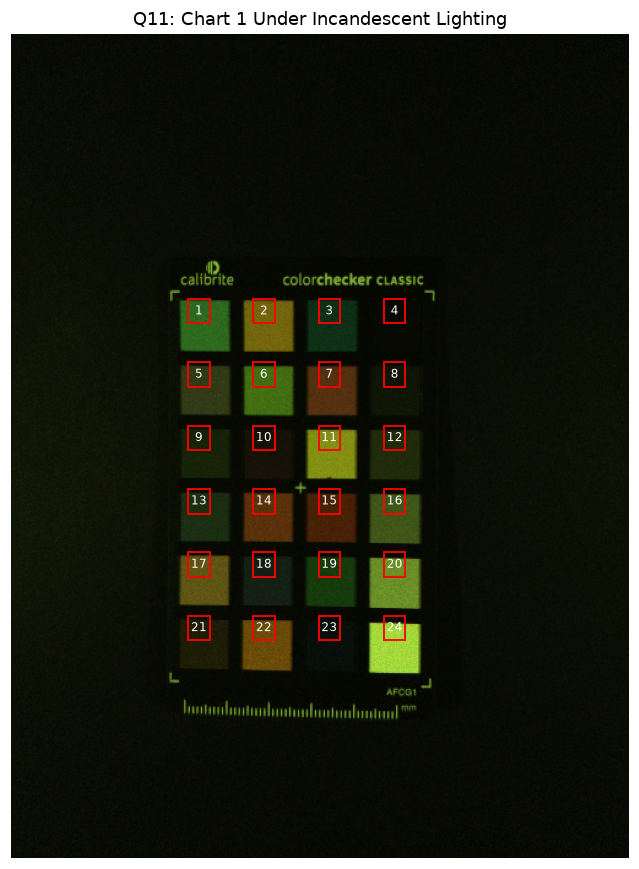

Valid patches: 24 / 24

QUESTION 11 - MATRIX TRANSFER TEST
Metric: CIEDE2000 (Delta E 00)
Same Q7 matrix used for both lighting conditions


Lighting,Mean Delta E,Worst Delta E,Worst Patch
LED (Round 2),3.719,7.755,15
Incandescent (Round 3),6.589,12.018,15



LED white balance gains: [ 1.4581  1.      3.6386]
Incandescent white balance gains: [ 1.3367  1.      3.6037]

Exposure scaling factors:
LED:          1.02568
Incandescent: 2.01561

Mean Delta E change: 2.87


In [71]:

# ============================================================
# Transfer of LED CCM to incandescent lighting
# Transfer Q7 Matrix: LED -> Incandescent
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import rawpy
import colour

from pathlib import Path
from matplotlib.patches import Rectangle
from IPython.display import display

folder = Path(str(DATA_ROOT / 'HW4_Set2'))

reference_file = folder / "Round2_1.DNG"
second_file = folder / "Round3_1.DNG"
second_white_file = folder / "Round3_4.DNG"

SATURATION = 3582.0

# ------------------------------------------------------------
# 1. REUSE ORIGINAL Q7 MATRIX AND COLOR REFERENCES
# ------------------------------------------------------------

assert "M" in globals(), "Run Q7 first."
assert "patch_rgb" in globals(), "Run Q4 first."
assert "valid_mask" in globals(), "Run Q4 clipping check."


# Original Question 7 fitted matrix
# Keep this unchanged for Questions 11 and 12

M_fixed = M.copy()  # Original fitted Q7 matrix, unchanged across illuminants

print("Using original Q7 matrix:")
print(M_fixed)

checker = colour.CCS_COLOURCHECKERS[
    "ColorChecker24 - After November 2014"
]

patch_names = list(checker.data.keys())

target_XYZ = colour.xyY_to_XYZ(
    np.array(list(checker.data.values()), dtype=float)
)

# Portrait position -> published reference order
order = np.array([
    21, 17, 13, 9, 5, 1,
    22, 18, 14, 10, 6, 2,
    23, 19, 15, 11, 7, 3,
    24, 20, 16, 12, 8, 4
]) - 1

# ------------------------------------------------------------
# 2. RAW BAYER -> LINEAR CAMERA RGB
# ------------------------------------------------------------

def q11_linear_rgb(path):

    with rawpy.imread(str(path)) as raw:

        mosaic = raw.raw_image_visible.astype(np.float32)
        colors = raw.raw_colors_visible
        black = np.array(
            raw.black_level_per_channel, dtype=np.float32
        )

        desc = raw.color_desc.decode("ascii")
        pattern = raw.raw_pattern

        linear = np.empty_like(mosaic)

        for ch in range(4):
            mask = colors == ch
            linear[mask] = (
                mosaic[mask] - black[ch]
            ) / (SATURATION - black[ch])

        linear = np.clip(linear, 0, 1)

        channels = {"R": [], "G": [], "B": []}

        for r in range(2):
            for c in range(2):
                ch = int(pattern[r, c])
                name = desc[ch]
                channels[name].append(linear[r::2, c::2])

        R = channels["R"][0]
        G = np.mean(channels["G"], axis=0)
        B = channels["B"][0]

        return np.stack([R, G, B], axis=-1)

# ------------------------------------------------------------
# 3. APPLY MATCHING WHITE-SHEET SHADING CORRECTION
# ------------------------------------------------------------

def q11_corrected_image(chart_path, white_path):

    chart = q11_linear_rgb(chart_path)
    white = q11_linear_rgb(white_path)

    flat = cv2.GaussianBlur(
        white, (0, 0), sigmaX=35, sigmaY=35
    )

    h, w = flat.shape[:2]

    center = flat[
        int(0.45*h):int(0.55*h),
        int(0.45*w):int(0.55*w)
    ].mean(axis=(0, 1))

    flat_normalized = flat / np.maximum(center, 1e-8)

    corrected_img = (
        chart / np.maximum(flat_normalized, 1e-6)
    )

    return np.rot90(corrected_img, k=3)

# Reuse Q3's corrected Round 2 image when available
if "corrected" in globals() and globals().get("round_num") == 2:
    ref_img = np.rot90(corrected, k=3)
else:
    ref_img = q11_corrected_image(
        reference_file, folder / "Round2_4.DNG"
    )

new_img = q11_corrected_image(
    second_file, second_white_file
)

H, W = ref_img.shape[:2]
H2, W2 = new_img.shape[:2]

assert (H, W) == (H2, W2)

# ------------------------------------------------------------
# 4. AUTOMATIC PATCH GRID ALIGNMENT
# ------------------------------------------------------------

# Reference centers from your verified Q4
ref_x = np.linspace(0.312*W, 0.642*W, 4)
ref_y = np.linspace(0.350*H, 0.750*H, 6)

dx = ref_x[1] - ref_x[0]
dy = ref_y[1] - ref_y[0]

left = int(ref_x[0] - 0.45*dx)
right = int(ref_x[-1] + 0.45*dx)
top = int(ref_y[0] - 0.45*dy)
bottom = int(ref_y[-1] + 0.45*dy)

downscale = 0.33

def matching_gray(img):
    gray = cv2.cvtColor(
        np.maximum(img, 0).astype(np.float32),
        cv2.COLOR_RGB2GRAY
    )
    gray = np.sqrt(gray)
    gray = cv2.resize(
        gray, None, fx=downscale, fy=downscale
    )
    return cv2.normalize(
        gray, None, 0, 255, cv2.NORM_MINMAX
    ).astype(np.uint8)

ref_gray = matching_gray(ref_img)
new_gray = matching_gray(new_img)

L = round(left*downscale)
R = round(right*downscale)
T = round(top*downscale)
B = round(bottom*downscale)

template = ref_gray[T:B, L:R]

best_score = -1
best_match = None

for scale in np.linspace(0.80, 1.40, 31):

    tw = round(template.shape[1]*scale)
    th = round(template.shape[0]*scale)

    if tw >= new_gray.shape[1] or th >= new_gray.shape[0]:
        continue

    resized = cv2.resize(template, (tw, th))

    response = cv2.matchTemplate(
        new_gray, resized, cv2.TM_CCOEFF_NORMED
    )

    _, score, _, location = cv2.minMaxLoc(response)

    if score > best_score:
        best_score = score
        best_match = (location, scale)

if best_match is None:
    raise RuntimeError("Chart detection failed.")

(mx, my), scale = best_match

xc = (mx + (ref_x*downscale - L)*scale) / downscale
yc = (my + (ref_y*downscale - T)*scale) / downscale

print(f"\nDetection score: {best_score:.3f}")
print(f"Detected scale: {scale:.3f}")

if best_score < 0.55:
    print("WARNING: Low-confidence match. Check the figure.")

# ------------------------------------------------------------
# 5. SAMPLE 24 PATCHES AND CHECK RAW CLIPPING
# ------------------------------------------------------------

box_w = int(0.035 * W2)
box_h = int(0.030 * H2)

with rawpy.imread(str(second_file)) as raw:
    mosaic = raw.raw_image_visible.copy()

block_max = np.maximum.reduce([
    mosaic[0::2, 0::2],
    mosaic[0::2, 1::2],
    mosaic[1::2, 0::2],
    mosaic[1::2, 1::2]
])

raw_max = np.rot90(block_max, k=3)

means = []
valid_regions = []
regions = []

for y in yc:
    for x in xc:

        x0 = int(round(x - box_w/2))
        x1 = x0 + box_w
        y0 = int(round(y - box_h/2))
        y1 = y0 + box_h

        if not (0 <= x0 < x1 <= W2 and
                0 <= y0 < y1 <= H2):
            raise ValueError("Sampling region outside image.")

        region = new_img[y0:y1, x0:x1]
        raw_region = raw_max[y0:y1, x0:x1]

        means.append(region.mean(axis=(0, 1)))
        valid_regions.append(
            not np.any(raw_region >= SATURATION)
        )
        regions.append((x0, y0, x1, y1))

new_patch_rgb = np.array(means)[order]
new_valid = np.array(valid_regions)[order]

# Display sample locations
preview = np.clip(
    new_img[::3, ::3] * 3, 0, 1
)

fig, ax = plt.subplots(figsize=(6, 8))
ax.imshow(preview, extent=[0, W2, H2, 0])

for i, (x0, y0, x1, y1) in enumerate(regions, 1):
    ax.add_patch(Rectangle(
        (x0, y0), x1-x0, y1-y0,
        fill=False, edgecolor="red", linewidth=1.2
    ))
    ax.text(
        (x0+x1)/2, (y0+y1)/2, str(i),
        color="white", ha="center", va="center",
        fontsize=8
    )

ax.set_title("Q11: Chart 1 Under Incandescent Lighting")
ax.axis("off")
plt.tight_layout()
plt.show()

print("Valid patches:", new_valid.sum(), "/ 24")

# ------------------------------------------------------------
# 6. WHITE BALANCE + FIXED MATRIX + EXPOSURE SCALE
# ------------------------------------------------------------

def transfer_error(camera_rgb, valid, label):

    gray_idx = 20   # Published Patch 21, Neutral 6.5
    white_idx = 18  # Published Patch 19, White

    if not (valid[gray_idx] and valid[white_idx]):
        raise ValueError(
            f"{label}: required neutral patch is clipped."
        )

    Rg, Gg, Bg = camera_rgb[gray_idx]

    gains = np.array([
        Gg / Rg, 1.0, Gg / Bg
    ])

    balanced = camera_rgb * gains

    # IMPORTANT: same Q7 matrix, no refitting
    predicted_XYZ = balanced @ M_fixed.T

    # Exposure scale to match reference Patch 19 Y
    scale_factor = (
        target_XYZ[white_idx, 1]
        / predicted_XYZ[white_idx, 1]
    )

    predicted_XYZ *= scale_factor

    # Consistent published Patch 19 reference white for Lab
    white_XYZ = target_XYZ[white_idx]
    white_xy = colour.XYZ_to_xy(white_XYZ)
    white_Y = white_XYZ[1]

    Lab_measured = colour.XYZ_to_Lab(
        predicted_XYZ / white_Y,
        illuminant=white_xy
    )

    Lab_target = colour.XYZ_to_Lab(
        target_XYZ / white_Y,
        illuminant=white_xy
    )

    DE = colour.delta_E(
        Lab_measured,
        Lab_target,
        method="CIE 2000"
    )

    DE = np.asarray(DE, dtype=float)
    DE[~valid] = np.nan

    return {
        "gains": gains,
        "scale": scale_factor,
        "errors": DE,
        "mean": np.nanmean(DE),
        "worst": np.nanmax(DE),
        "worst_patch": np.nanargmax(DE)+1
    }

# Original Round 2 measurements from Q4
original_rgb = patch_rgb[order]
original_valid = np.asarray(valid_mask)[order]

original = transfer_error(
    original_rgb, original_valid, "LED"
)

second = transfer_error(
    new_patch_rgb, new_valid, "Incandescent"
)


# ------------------------------------------------------------
# 7. REQUIRED QUESTION 11 RESULTS
# ------------------------------------------------------------

q11_df = pd.DataFrame([
    {
        "Lighting": "LED (Round 2)",
        "Mean Delta E": original["mean"],
        "Worst Delta E": original["worst"],
        "Worst Patch": original["worst_patch"]
    },
    {
        "Lighting": "Incandescent (Round 3)",
        "Mean Delta E": second["mean"],
        "Worst Delta E": second["worst"],
        "Worst Patch": second["worst_patch"]
    }
])

print("\nQUESTION 11 - MATRIX TRANSFER TEST")
print("Metric: CIEDE2000 (Delta E 00)")
print("Same Q7 matrix used for both lighting conditions")

display(
    q11_df.style
    .format({
        "Mean Delta E": "{:.3f}",
        "Worst Delta E": "{:.3f}",
        "Worst Patch": "{:.0f}"
    })
    .hide(axis="index")
)

print("\nLED white balance gains:",
      np.round(original["gains"], 5))
print("Incandescent white balance gains:",
      np.round(second["gains"], 5))

print("\nExposure scaling factors:")
print(f"LED:          {original['scale']:.5f}")
print(f"Incandescent: {second['scale']:.5f}")

print("\nMean Delta E change:",
      round(second["mean"] - original["mean"], 3))

# Retain results for Question 12
q11_original = original
q11_second = second
q11_fixed_matrix = M_fixed.copy()


### 5.12 Test the LED-fitted CCM under daylight

Q12: Using unchanged Q7 color correction matrix
[[ 1.0793  0.5207  0.4557]
 [ 0.0635  1.8664  0.2324]
 [ 0.0902 -0.9707  2.5974]]

Daylight detection score: 0.954
Detected scale: 0.880
Valid daylight patches: 24 / 24


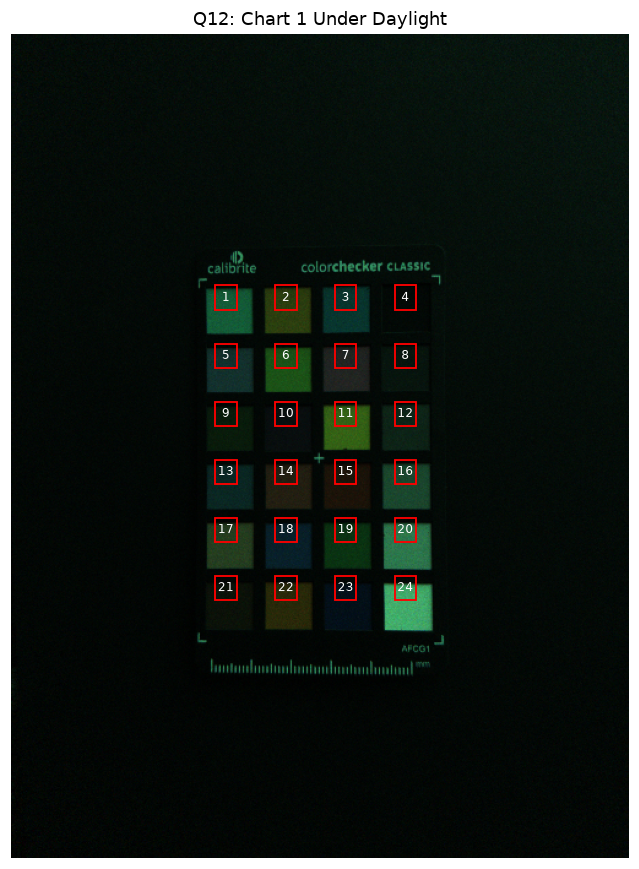


QUESTION 12 - THREE ILLUMINANT COMPARISON
Metric: CIEDE2000 (Delta E 00)


Lighting,Mean Delta E,Worst Delta E,Worst Patch
LED (Round 2),3.719,7.755,15
Incandescent (Round 3),6.589,12.018,15
Daylight (Round 4),8.726,18.102,18



Daylight white balance gains: [ 2.6382  1.      1.5665]
Daylight exposure scale: 2.75096


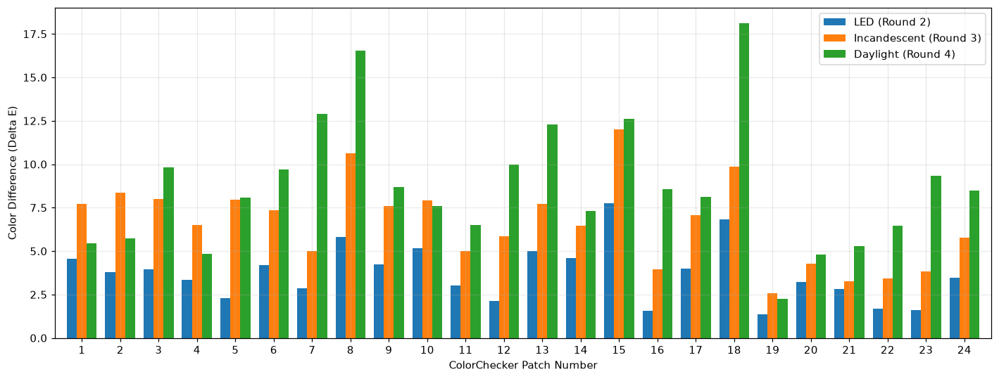


Per-Patch Color Error Comparison


,Patch,LED,Incandescent,Daylight
0,1,4.566,7.697,5.429
1,2,3.779,8.364,5.749
2,3,3.962,8.008,9.815
3,4,3.340,6.516,4.837
4,5,2.273,7.974,8.066
5,6,4.209,7.344,9.719
6,7,2.858,5.000,12.909
7,8,5.827,10.614,16.529
8,9,4.244,7.588,8.703
9,10,5.158,7.905,7.606


In [72]:

# ============================================================
# Transfer of LED CCM to daylight
# Third Illuminant: Daylight (Round 4)
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import rawpy

from pathlib import Path
from matplotlib.patches import Rectangle
from IPython.display import display

# ------------------------------------------------------------
# 1. FILES AND ORIGINAL Q7 MATRIX
# ------------------------------------------------------------

folder = Path(str(DATA_ROOT / 'HW4_Set2'))

daylight_file = folder / "Round4_1.DNG"
daylight_white_file = folder / "Round4_4.DNG"

assert daylight_file.exists()
assert daylight_white_file.exists()

assert "q11_original" in globals(), "Run Q11 first."
assert "q11_second" in globals(), "Run Q11 first."
assert "q11_fixed_matrix" in globals(), "Run Q11 first."

# IMPORTANT: use the SAME matrix saved during Q11.
# This is the original Q7 matrix, not a matrix from Q9.
M_fixed = q11_fixed_matrix.copy()

print("Q12: Using unchanged Q7 color correction matrix")
print(np.round(M_fixed, 5))

# ------------------------------------------------------------
# 2. LOAD DAYLIGHT IMAGE WITH SHADING CORRECTION
# ------------------------------------------------------------

daylight_img = q11_corrected_image(
    daylight_file,
    daylight_white_file
)

H, W = daylight_img.shape[:2]

# ------------------------------------------------------------
# 3. AUTOMATIC COLORCHECKER ALIGNMENT
# ------------------------------------------------------------

# Use the reference image and Q4 centers from Q11.
# Q11 already defined ref_img and matching_gray().

ref_H, ref_W = ref_img.shape[:2]

ref_x = np.linspace(0.312 * ref_W, 0.642 * ref_W, 4)
ref_y = np.linspace(0.350 * ref_H, 0.750 * ref_H, 6)

dx = ref_x[1] - ref_x[0]
dy = ref_y[1] - ref_y[0]

left = int(ref_x[0] - 0.45 * dx)
right = int(ref_x[-1] + 0.45 * dx)
top = int(ref_y[0] - 0.45 * dy)
bottom = int(ref_y[-1] + 0.45 * dy)

downscale = 0.33

reference_gray = matching_gray(ref_img)
daylight_gray = matching_gray(daylight_img)

L = round(left * downscale)
R = round(right * downscale)
T = round(top * downscale)
B = round(bottom * downscale)

template = reference_gray[T:B, L:R]

best_score = -1
best_match = None

for scale in np.linspace(0.80, 1.40, 31):

    tw = round(template.shape[1] * scale)
    th = round(template.shape[0] * scale)

    if (tw >= daylight_gray.shape[1] or
        th >= daylight_gray.shape[0] or
        tw < 2 or th < 2):
        continue

    resized = cv2.resize(template, (tw, th))

    response = cv2.matchTemplate(
        daylight_gray,
        resized,
        cv2.TM_CCOEFF_NORMED
    )

    _, score, _, location = cv2.minMaxLoc(response)

    if score > best_score:
        best_score = score
        best_match = (location, scale)

if best_match is None:
    raise RuntimeError("Daylight chart detection failed.")

(mx, my), scale = best_match

xc = (
    mx + (ref_x * downscale - L) * scale
) / downscale

yc = (
    my + (ref_y * downscale - T) * scale
) / downscale

print(f"\nDaylight detection score: {best_score:.3f}")
print(f"Detected scale: {scale:.3f}")

if best_score < 0.55:
    print("WARNING: Check detected patch positions.")

# ------------------------------------------------------------
# 4. SAMPLE THE 24 PATCHES
# ------------------------------------------------------------

box_w = int(0.035 * W)
box_h = int(0.030 * H)

with rawpy.imread(str(daylight_file)) as raw:
    mosaic = raw.raw_image_visible.copy()

block_max = np.maximum.reduce([
    mosaic[0::2, 0::2],
    mosaic[0::2, 1::2],
    mosaic[1::2, 0::2],
    mosaic[1::2, 1::2]
])

raw_max = np.rot90(block_max, k=3)

means = []
valid_regions = []
regions = []

for y in yc:
    for x in xc:

        x0 = int(round(x - box_w / 2))
        x1 = x0 + box_w

        y0 = int(round(y - box_h / 2))
        y1 = y0 + box_h

        if not (0 <= x0 < x1 <= W and
                0 <= y0 < y1 <= H):
            raise ValueError("Patch region outside image.")

        patch = daylight_img[y0:y1, x0:x1]
        raw_patch = raw_max[y0:y1, x0:x1]

        means.append(patch.mean(axis=(0, 1)))

        valid_regions.append(
            not np.any(raw_patch >= 3582)
        )

        regions.append((x0, y0, x1, y1))

# Reorder to standard ColorChecker numbering
# 'order' was defined in Q11.
daylight_rgb = np.array(means)[order]
daylight_valid = np.array(valid_regions)[order]

print("Valid daylight patches:",
      daylight_valid.sum(), "/ 24")

# ------------------------------------------------------------
# 5. DISPLAY DAYLIGHT SAMPLING REGIONS
# ------------------------------------------------------------

preview = np.clip(
    daylight_img[::3, ::3] * 3,
    0, 1
)

fig, ax = plt.subplots(figsize=(6, 8))

ax.imshow(preview, extent=[0, W, H, 0])

for n, (x0, y0, x1, y1) in enumerate(regions, 1):

    ax.add_patch(
        Rectangle(
            (x0, y0),
            x1 - x0,
            y1 - y0,
            fill=False,
            edgecolor="red",
            linewidth=1.2
        )
    )

    ax.text(
        (x0 + x1) / 2,
        (y0 + y1) / 2,
        str(n),
        color="white",
        fontsize=8,
        ha="center",
        va="center"
    )

ax.set_title("Q12: Chart 1 Under Daylight")
ax.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. WHITE BALANCE AND APPLY ORIGINAL Q7 MATRIX
# ------------------------------------------------------------

# Reuse Q11 transfer_error() function.
# It recalculates WB, applies M_fixed, scales exposure,
# and computes CIEDE2000.

daylight = transfer_error(
    daylight_rgb,
    daylight_valid,
    "Daylight"
)

# Keep results for Q13
q12_daylight = daylight

# ------------------------------------------------------------
# 7. QUESTION 12 RESULTS TABLE
# ------------------------------------------------------------

q12_df = pd.DataFrame([
    {
        "Lighting": "LED (Round 2)",
        "Mean Delta E": q11_original["mean"],
        "Worst Delta E": q11_original["worst"],
        "Worst Patch": q11_original["worst_patch"]
    },
    {
        "Lighting": "Incandescent (Round 3)",
        "Mean Delta E": q11_second["mean"],
        "Worst Delta E": q11_second["worst"],
        "Worst Patch": q11_second["worst_patch"]
    },
    {
        "Lighting": "Daylight (Round 4)",
        "Mean Delta E": daylight["mean"],
        "Worst Delta E": daylight["worst"],
        "Worst Patch": daylight["worst_patch"]
    }
])

print("\nQUESTION 12 - THREE ILLUMINANT COMPARISON")
print("Metric: CIEDE2000 (Delta E 00)")

display(
    q12_df.style
    .format({
        "Mean Delta E": "{:.3f}",
        "Worst Delta E": "{:.3f}",
        "Worst Patch": "{:.0f}"
    })
    .hide(axis="index")
)

print("\nDaylight white balance gains:",
      np.round(daylight["gains"], 5))

print("Daylight exposure scale:",
      round(daylight["scale"], 5))

# ------------------------------------------------------------
# 8. REQUIRED PER-PATCH DELTA E FIGURE
# ------------------------------------------------------------

patch_numbers = np.arange(1, 25)
bar_width = 0.26

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    patch_numbers - bar_width,
    q11_original["errors"],
    width=bar_width,
    label="LED (Round 2)"
)

ax.bar(
    patch_numbers,
    q11_second["errors"],
    width=bar_width,
    label="Incandescent (Round 3)"
)

ax.bar(
    patch_numbers + bar_width,
    daylight["errors"],
    width=bar_width,
    label="Daylight (Round 4)"
)



ax.set_xlabel("ColorChecker Patch Number")
ax.set_ylabel("Color Difference (Delta E)")

ax.set_xticks(patch_numbers)
ax.set_xlim(0.3, 24.7)

ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 9. PER-PATCH TABLE FOR CHECKING
# ------------------------------------------------------------

per_patch_df = pd.DataFrame({
    "Patch": np.arange(1, 25),
    "LED": q11_original["errors"],
    "Incandescent": q11_second["errors"],
    "Daylight": daylight["errors"]
})

print("\nPer-Patch Color Error Comparison")
display(per_patch_df.round(3))


### 5.13 Compare white-balance gains across illuminants

In [73]:
# ============================================================
# White-balance gains and illumination comparison
# ============================================================
import numpy as np
import pandas as pd
from IPython.display import display

assert all(v in globals() for v in ("q11_original", "q11_second", "q12_daylight")), "Run Q11 and Q12 first"
lighting = [
    ("LED (Round 2)", q11_original),
    ("Incandescent (Round 3)", q11_second),
    ("Daylight (Round 4)", q12_daylight)
]
rows = []
for label, r in lighting:
    g = np.asarray(r["gains"], float) / float(r["gains"][1])
    rows.append({"Lighting": label, "Red Gain": g[0], "Green Gain": g[1],
                 "Blue Gain": g[2], "Mean Delta E": r["mean"], "Worst Delta E": r["worst"]})
q13_df = pd.DataFrame(rows)
print("QUESTION 13 - WHITE BALANCE AND FIXED-CCM TRANSFER")
display(q13_df.round(4))
led = q13_df.iloc[0]
for i in (1,2):
    r = q13_df.iloc[i]
    print(f"{r['Lighting']} relative to LED: R gain {r['Red Gain']-led['Red Gain']:+.4f}, "
          f"B gain {r['Blue Gain']-led['Blue Gain']:+.4f}, "
          f"mean DE difference {r['Mean Delta E']-led['Mean Delta E']:+.3f}")
print("\nInterpretation: white balance indicates relative illuminant color balance,")
print("not a measurement of the light spectrum or color temperature. A fixed CCM")
print("cannot correct every illuminant equally; some DNG workflows use separate")
print("Illuminant A and D65 matrices blended using an estimated white balance.")


QUESTION 13 - WHITE BALANCE AND FIXED-CCM TRANSFER


,Lighting,Red Gain,Green Gain,Blue Gain,Mean Delta E,Worst Delta E
0,LED (Round 2),1.4581,1.0,3.6386,3.7192,7.7553
1,Incandescent (Round 3),1.3367,1.0,3.6037,6.5892,12.0175
2,Daylight (Round 4),2.6382,1.0,1.5665,8.7264,18.1022


Incandescent (Round 3) relative to LED: R gain -0.1214, B gain -0.0349, mean DE difference +2.870
Daylight (Round 4) relative to LED: R gain +1.1801, B gain -2.0721, mean DE difference +5.007

Interpretation: white balance indicates relative illuminant color balance,
not a measurement of the light spectrum or color temperature. A fixed CCM
cannot correct every illuminant equally; some DNG workflows use separate
Illuminant A and D65 matrices blended using an estimated white balance.


### 5.14 Check three-chart color statistics

In [74]:
# The final three-chart statistics come from Question 10, not typed-in report values.
assert len(before_means) == len(after_means) == len(worst_values) == 3
assert np.all(np.isfinite(before_means))
assert np.all(np.isfinite(after_means))
assert np.all(np.isfinite(worst_values))
assert np.isclose(q10_worst[0], np.mean(worst_values), atol=0.001)
assert q10_after[0] < q10_before[0], "Check CCM results: no improvement in mean error."
print("PASS — three charts included and worst-patch averaging checked")
print("Before CCM:", q10_before)
print("After CCM: ", q10_after)
print("Worst patch:", q10_worst)

project_color_before = float(q10_before[0])
project_color_after = float(q10_after[0])
project_color_worst = float(q10_worst[0])


PASS — three charts included and worst-patch averaging checked
Before CCM: [13.514, 0.62]
After CCM:  [3.472, 0.215]
Worst patch: [7.552, 0.223]


## 6. Final checks

I check that the reported quantities were calculated and that the values are finite. These checks are useful for finding code mistakes, but **they do not replace** checking the RAW images, plots, uncertainty assumptions, and experimental conditions.

The official `results.json` remains the file submitted with the project; I only update it after comparing the new notebook outputs with the report. I did not make the notebook overwrite it automatically.

### 6.1 Check the main measured outputs

In [86]:
# Quick check of the main numbers calculated above.
final_checks = {
    "calibration_rms_px": calibration_rms,
    "mtf50_center_cy_per_green_pixel": float(mean_mtf50),
    "conversion_gain_dn_per_e": project_noise_gain,
    "read_noise_e": project_read_noise_e,
    "dynamic_range_stops": project_dynamic_range,
    "delta_e_mean_before_ccm": project_color_before,
    "delta_e_mean_after_ccm": project_color_after,
    "delta_e_worst_after_ccm": project_color_worst,
}

for name, value in final_checks.items():
    assert np.isfinite(value), f"Invalid measurement: {name}"
    print(f"{name}: {value:.5f}")

print("\nPASS - All final measurement values are finite.")


calibration_rms_px: 0.89457
mtf50_center_cy_per_green_pixel: 0.37297
conversion_gain_dn_per_e: 0.24371
read_noise_e: 6.56924
dynamic_range_stops: 10.89042
delta_e_mean_before_ccm: 13.51400
delta_e_mean_after_ccm: 3.47200
delta_e_worst_after_ccm: 7.55200

PASS - All final measurement values are finite.
